## Configuración antes de empezar

1. Los CSV están en `data/csv` dentro del proyecto. Si están en otro sitio, cambia `DATA_DIR` en la siguiente celda por su ruta; por ejemplo, `Path(r"C:\mis_datos\csv")` o `Path("/ruta/a/csv")`. Una ruta relativa depende del directorio de trabajo del kernel.
2. `CHECKPOINT_DIR` indica dónde guardar y buscar los checkpoints; por defecto es el directorio de trabajo. Puedes cambiarlo por otra carpeta existente. No se necesitan checkpoints anteriores para empezar desde cero.
3. Instala `python-dotenv` y copia `.env.example` como `.env` en la raíz del proyecto. Configura MySQL en `.env`: `CHESS_MYSQL_HOST`, `CHESS_MYSQL_USER` y `CHESS_MYSQL_PASSWORD`. Si la contraseña no está definida se solicita de forma oculta; una contraseña definida vacía se usa vacía. No escribas contraseñas en el notebook ni compartas `.env`.
4. Para reutilizar los datos del estudio, descomprime `datos_chesscraping.zip` y restaura los volcados de `sql` en una base MySQL de trabajo llamada `chesscraping`. Los CSV por sí solos no sustituyen a las tablas utilizadas por el análisis. Consulta `USO_NOTEBOOK.md` antes de importar.
5. Si necesitas un ChromeDriver concreto, indica su ruta en `CHESS_CHROMEDRIVER_PATH` dentro de `.env`; si no, Selenium intentará gestionarlo. Para acceder a la API, configura `CHESS_USER_AGENT` con un identificador y contacto adecuados.
6. Ejecuta la siguiente celda y después las secciones que necesites en orden. Algunas celdas descargan datos, escriben en MySQL o sobrescriben CSV. Las opciones de análisis y de informes HTML están descritas en `USO_NOTEBOOK.md`. Revisa las condiciones de las fuentes antes de ejecutar la recopilación.

In [ ]:
import os
from getpass import getpass
from pathlib import Path
from dotenv import load_dotenv

load_dotenv(dotenv_path=Path(".env"))

DATA_DIR = Path("./data/csv").expanduser().resolve()
CHECKPOINT_DIR = Path(".").resolve()
MYSQL_HOST = os.environ.get("CHESS_MYSQL_HOST", "127.0.0.1")
MYSQL_USER = os.environ.get("CHESS_MYSQL_USER", "root")
MYSQL_PASSWORD = os.environ.get("CHESS_MYSQL_PASSWORD")
if MYSQL_PASSWORD is None:
    MYSQL_PASSWORD = getpass("Contraseña de MySQL: ")
CHROMEDRIVER_PATH = os.environ.get("CHESS_CHROMEDRIVER_PATH", "")
CHESS_USER_AGENT = os.environ.get("CHESS_USER_AGENT", "chesscraping/1.0 (contacto: configura CHESS_USER_AGENT)")


# **CHESSCRAPING** X MARTÍN JOSÉ GARCÍA NAVARRO

### ANÁLISIS DE DATOS EXPLORATORIO Y MODELO PREDICTIVO CON XBOOST SOBRE LAS PARTIDAS DE AJEDREZ ACTIVIDADES 2-3 EJECUCIÓN COMPLETA ESTIMADA 30-35 HRS (10 MIN CON DB (32HRS AVG) Y HTML (1HR))

El ajedrez tiene orígenes antiguos desde la india, y persia con la variación llamada **chaturanga** el VI dc  llegando a Europa con la conquista mususlmana en el 711 de la península ibérica, estableciendose allí condiciones modernas y cambios en el juego la modificación como la pieza alferza "ferz" (ministro) que se jugaba en la versión antigua de con la versión llamada **shatranj**, ocurriendo con la reconquita llegando a su fin, este ministro era una especie de rey que se movía y capturaba en diagonal un espacio y representado como un alfil al revés en digital llegando a valer 1.5pts a la Dama en honor a Isabel La Católica, llegando a aperecer por primera vez en el **Arte de axedrez de Luis de Lucena (1497)** aumentando su valor un **600%** y movimientos posibles un **650%**.

El primer Campeonato Mundial de Ajedrez oficial se disputó en 1886, ganado por Wilhelm Steinitz, el 20 de julio 1924 se fundó en París la **FIDE** (Federación Internacional de Ajedrez), (casualmente dia del adrez), encargada de regular títulos y competiciones. Desde entonces el ajedrez picos de popularidad como la era soviética y la guerra fría donde se competía en todo ámbito, incluso en el ajedrez **Fischer–Spassky** (1972), la era informática **Deep Blue vs Kasparov en 1997**, y sobre todo un pico  y resurgimiento desde la pandemia en 2020.

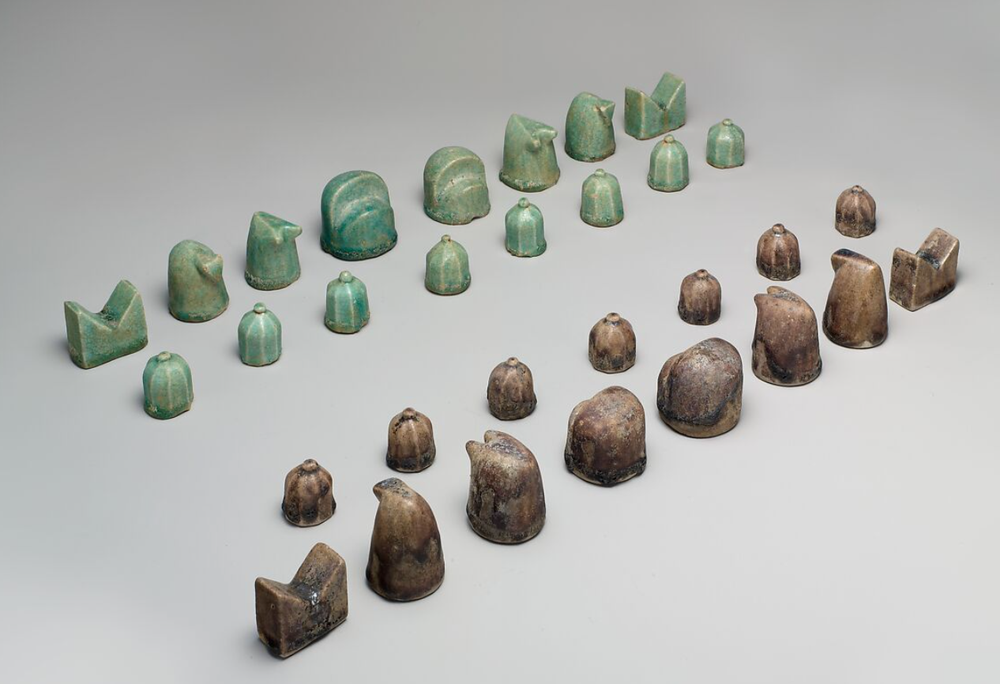

## **INSTALACIONES, IMPORTS Y CREACIÓN SQL**

### **IMPORTS E INSTALACIONES**

#### **INSTALACIONES**

In [8]:
!pip install xgboost
!pip install pandas
!pip install requests 
!pip install python-dotenv 
!pip install tqdm 
!pip install tenacity
!pip install ratelimit
!pip install mysql-connector-python SQLAlchemy
!pip install pymysql
!pip install beautifulsoup4
!pip install lxml
!pip install selenium
!pip install webdriver-manager
!pip install python-chess
!pip install selenium
!pip install ydata-profiling
!pip install itables
!pip install pycountry
!pip install ipywidgets
!pip install jupyterlab 
!pip install jupyterlab_widgets
!pip install ipython-autotime
%load_ext autotime

  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
Using cached h11-0.16.0-py3-none-any.whl (37 kB)
  Attempting uninstall: h11
    Found existing installation: h11 0.14.0
    Uninstalling h11-0.14.0:
      Successfully uninstalled h11-0.14.0


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
httpcore 1.0.2 requires h11<0.15,>=0.13, but you have h11 0.16.0 which is incompatible.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
wsproto 1.3.1 requires h11<1,>=0.16.0, but you have h11 0.14.0 which is incompatible.



  Using cached h11-0.14.0-py3-none-any.whl.metadata (8.2 kB)
Using cached h11-0.14.0-py3-none-any.whl (58 kB)
  Attempting uninstall: h11
    Found existing installation: h11 0.16.0
    Uninstalling h11-0.16.0:
      Successfully uninstalled h11-0.16.0
time: 0 ns (started: 2025-12-11 09:40:23 +01:00)


#### **IMPORTS**

In [10]:
import pandas as pd
import sys
import warnings
import ipywidgets as widgets
from IPython.display import display
import chess
import chess.svg
from IPython.display import SVG, display
import time
import plotly.express as px
from ydata_profiling import ProfileReport
import pycountry
from matplotlib.patches import Patch
from matplotlib import cm
from datetime import datetime as dt
sys.path.insert(0,'/usr/lib/chromium-browser/chromedriver')
pd.set_option("display.max_columns", None)
# pip install webdriver-manager
from selenium import webdriver
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.common.by import By
from bs4 import BeautifulSoup as bs
import re
import io
import mysql.connector
import requests
import json
import random
import numpy as np
import math
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8')
import seaborn as sns
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle
from matplotlib.patches import Polygon  #mollewide
from mpl_toolkits.mplot3d import Axes3D  #compatibilidad 3D en Matplotlib
import plotly.graph_objects as go
import matplotlib.dates as mdates  # ticks de meses
import os
import csv
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed
session = requests.Session()#SESION REQUESTS XA LATENCIAS
from pathlib import Path
from datetime import timezone
from datetime import datetime
from sqlalchemy import create_engine
from sqlalchemy import URL
url_object = URL.create(
    "mysql+pymysql",
    username=MYSQL_USER,
    password=MYSQL_PASSWORD, 
    host=MYSQL_HOST,
    database="chesscraping",
)
engine = create_engine(url_object)
%matplotlib inline
import xgboost as xgb
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, classification_report, log_loss
from collections import Counter
from sklearn.datasets import make_classification
from imblearn.combine import SMOTETomek

time: 5.91 s (started: 2025-12-11 09:40:23 +01:00)


### **CONEXIÓN MYSQL LOOPBACK, CREACIÓN TABLAS E INSERCIÓN BÁSICA**

In [12]:
conn = mysql.connector.connect(
    user=MYSQL_USER,
    password=MYSQL_PASSWORD,
    host=MYSQL_HOST
)
cursor = conn.cursor()

time: 16 ms (started: 2025-12-11 09:40:29 +01:00)


#### **SQL CREATION**

In [14]:
cursor.execute("CREATE DATABASE IF NOT EXISTS chesscraping")
cursor.execute("USE chesscraping")

statements = [
    """
    CREATE TABLE IF NOT EXISTS Title (
        code VARCHAR(10) PRIMARY KEY,
        name VARCHAR(100) NOT NULL,
        gender CHAR(1)
    );
    """,
    """
    INSERT IGNORE INTO Title (code, name, gender) VALUES
        ('GM','Gran Maestro','M'),
        ('WGM','Gran Maestra','F'),
        ('IM','Maestro Internacional','M'),
        ('WIM','Maestra Internacional','F'),
        ('FM','Maestro FIDE','M'),
        ('WFM','Maestra FIDE','F'),
        ('NM','Maestro Nacional','M'),
        ('WNM','Maestra Nacional','F'),
        ('CM','Candidato a Maestro','M'),
        ('WCM','Candidata a Maestra','F');
    """,
    """
    CREATE TABLE IF NOT EXISTS Country (
        code CHAR(2) PRIMARY KEY, -- Código ISO-3166-1 (2 letras)
        name VARCHAR(100) NOT NULL -- Nombre país
    );
    """,
    """
    CREATE TABLE IF NOT EXISTS Status (
        code VARCHAR(50) PRIMARY KEY, -- 'closed:fair_play_violations'
        name VARCHAR(50) NOT NULL
    );
    """,
    """
    INSERT IGNORE INTO Status (code, name) VALUES
        ('basic','Cuenta básica'),
        ('premium','Cuenta premium'),
        ('closed:fair_play_violations','Cuenta cerrada por trampas'),
        ('closed','Cuenta cerrada (otra razón)'),
        ('mod','Moderador'),
        ('staff','Staff'),
        ('other','Otro/Desconocido');
    """,
    """
    CREATE TABLE IF NOT EXISTS Mode (
        mode_id INT PRIMARY KEY, -- Id modo (a mano)
        name VARCHAR(50) NOT NULL -- Nombre modo
    );
    """,
    """
    INSERT IGNORE INTO Mode (mode_id, name) VALUES
        (1,'bullet'),
        (2,'blitz'),
        (3,'rapid'),
        (4,'daily'),
        (5,'chess960_daily'),
        (6,'tactics'),
        (7,'puzzle_rush'),
        (8,'lessons');
    """,
    """
    CREATE TABLE IF NOT EXISTS Player (
        id BIGINT PRIMARY KEY, -- Id numérico Chess.com (player_id)
        username VARCHAR(100) NOT NULL UNIQUE, -- Nombre de usuario
        title_code VARCHAR(10) DEFAULT NULL, -- FK a Title
        country_code CHAR(2) DEFAULT NULL,   -- FK a Country
        status_code VARCHAR(50) DEFAULT NULL, -- FK a Status
        registration_date DATETIME, -- Fecha registro
        last_seen DATETIME, -- Última conexión
        gender CHAR(1) DEFAULT NULL, -- M/F por título o lo que sea
        is_cheater BOOLEAN DEFAULT FALSE, -- True si tramposo
        in_club BOOLEAN DEFAULT FALSE, -- True si está en algún club
        in_tournament BOOLEAN DEFAULT FALSE, -- True si ha jugado torneos
        is_streamer BOOLEAN DEFAULT FALSE, -- True si es streamer oficial
        league VARCHAR(50) DEFAULT NULL, -- Liga Chess.com
        streaming_platforms TEXT DEFAULT NULL, -- Plataformas de streaming
        tournaments_played INT DEFAULT 0,
        followers INT DEFAULT 0,
        FOREIGN KEY (title_code) REFERENCES Title(code),
        FOREIGN KEY (country_code) REFERENCES Country(code),
        FOREIGN KEY (status_code) REFERENCES Status(code)
    );
    """,
    """
    CREATE TABLE IF NOT EXISTS Stats (
        player_id BIGINT NOT NULL,
        mode_id INT NOT NULL,
        last_rating INT,
        best_rating INT,
        rd INT DEFAULT NULL, -- Rating deviation
        wins INT DEFAULT 0,
        losses INT DEFAULT 0,
        draws INT DEFAULT 0,
        games_played INT DEFAULT 0,
        win_rate DECIMAL(5,2) DEFAULT 0.00,
        loss_rate DECIMAL(5,2) DEFAULT 0.00,
        draw_rate DECIMAL(5,2) DEFAULT 0.00,
        PRIMARY KEY (player_id, mode_id),
        FOREIGN KEY (player_id) REFERENCES Player(id),
        FOREIGN KEY (mode_id) REFERENCES Mode(mode_id)
    );
    """,
    """
    CREATE TABLE IF NOT EXISTS GameList (
        list_id INT AUTO_INCREMENT PRIMARY KEY,
        player_id BIGINT NOT NULL,
        mode_id INT NOT NULL,
        UNIQUE (player_id, mode_id),
        FOREIGN KEY (player_id, mode_id)
            REFERENCES Stats(player_id, mode_id)
            ON DELETE CASCADE
    );
    """,
    """
    CREATE TABLE IF NOT EXISTS Opening (
        eco_code VARCHAR(5) PRIMARY KEY, -- Código ECO (A00-E99)
        name TEXT -- Nombre de la apertura
    );
    """,
    "INSERT IGNORE INTO Opening (eco_code, name) VALUES ('NONE','NPI');",
          """
    CREATE TABLE IF NOT EXISTS Game (
        game_id BIGINT AUTO_INCREMENT PRIMARY KEY,
        list_id INT NOT NULL, 
        white_player_id BIGINT NULL,
        black_player_id BIGINT NULL, -- SI NO ESTA EN PLAYER, GUARDAR COMO NULL!!!
        white_username VARCHAR(200),
        black_username VARCHAR(200),
        white_elo INT,
        black_elo INT,
        mode_id INT NOT NULL,
        pgn TEXT NOT NULL, -- Notación PGN completa
        url_id VARCHAR(300) NOT NULL UNIQUE, -- URL única de la partida
        white_accuracy DECIMAL(5,2),
        black_accuracy DECIMAL(5,2),
        result VARCHAR(30),
        date DATETIME,
        eco_code VARCHAR(5) DEFAULT NULL,
        FOREIGN KEY (list_id) REFERENCES GameList(list_id),
        FOREIGN KEY (mode_id) REFERENCES Mode(mode_id),
        FOREIGN KEY (eco_code) REFERENCES Opening(eco_code),
        FOREIGN KEY (white_player_id) REFERENCES Player(id),
        FOREIGN KEY (black_player_id) REFERENCES Player(id)
    );
    """
]
#OJO PONER CONTRINCANTE ID A NULL
for xd in statements:
    cursor.execute(xd)

conn.commit()
cursor.close()
conn.close()
print("ok")

ok
time: 31 ms (started: 2025-12-11 09:40:29 +01:00)


##### **IMAGEN DIAGRAMA ER**

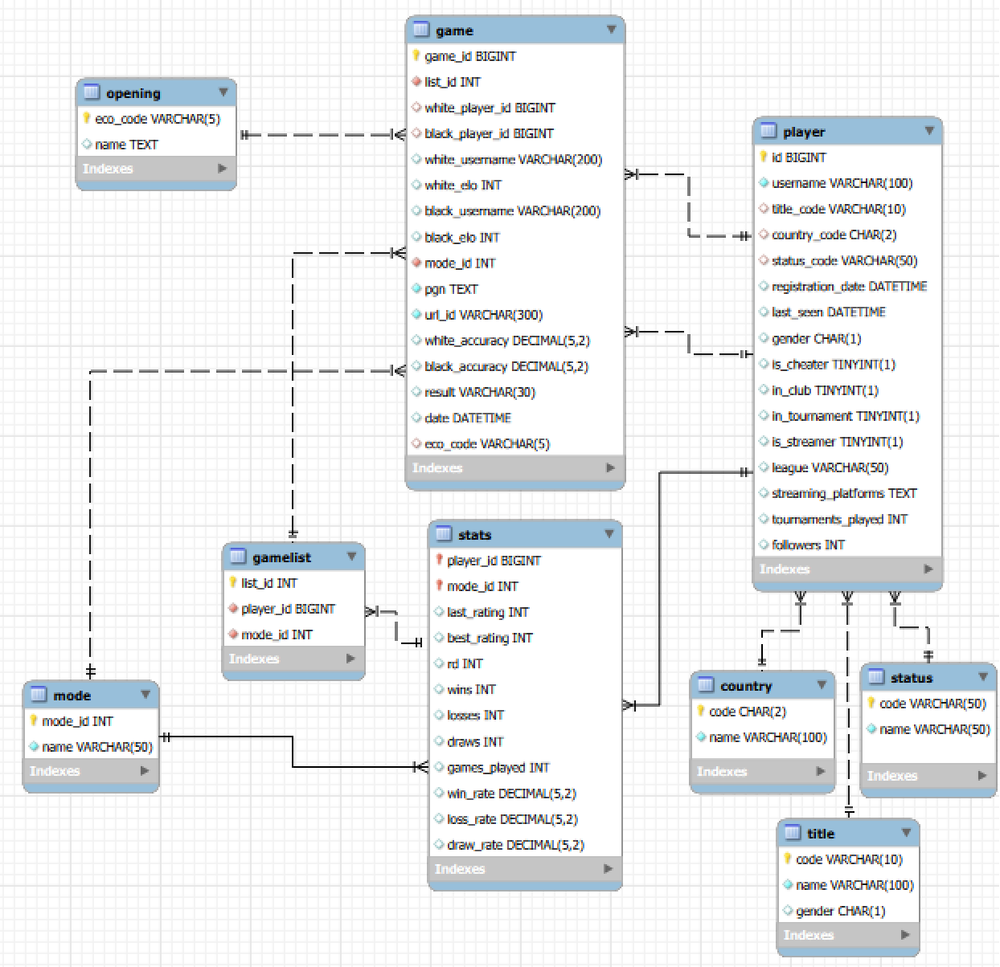

##### **IMAGEN DIAGRAMA RELACIONAL**

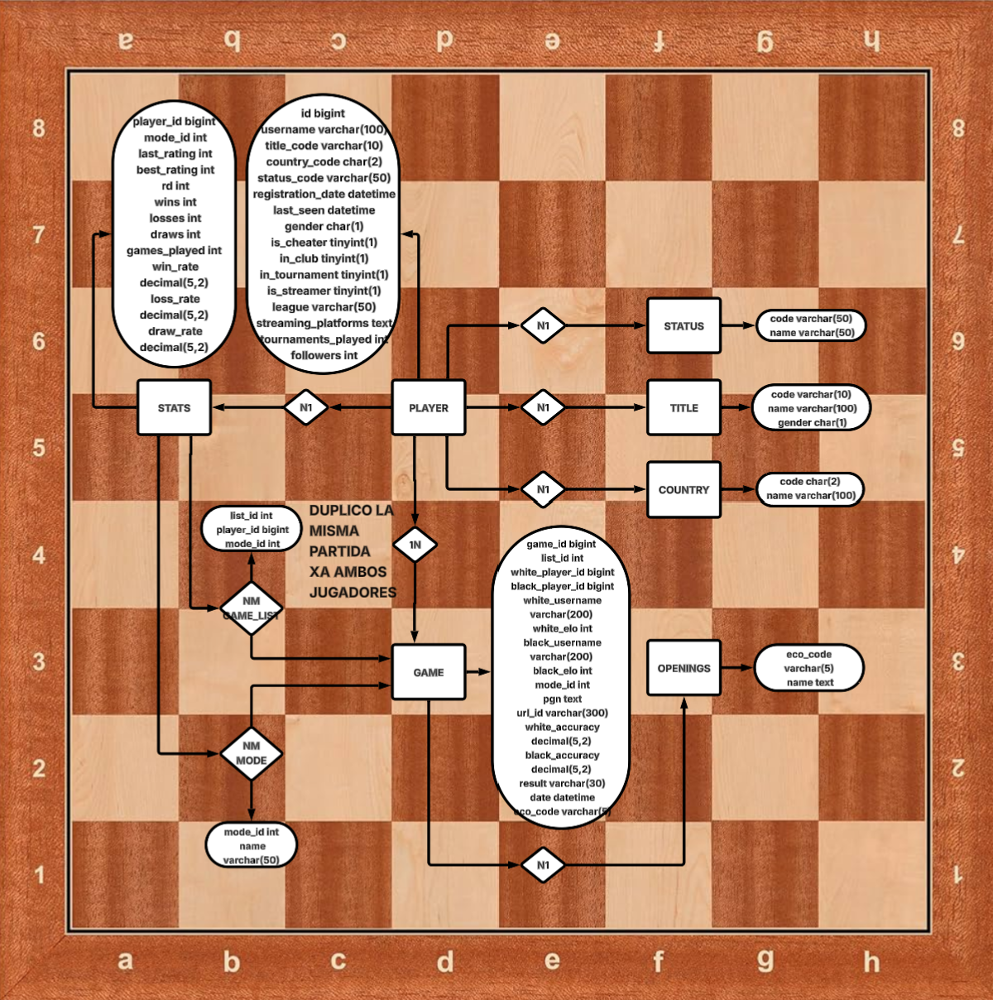

## **WEB SCRAPING TABLAS ECO, PAISES, PARTIDAS, TITULOS, STATUS, MODOS DE JUEGO, JUGADORES Y STATS (google driver/requests/sessions)**

### **WEB SCRAPING ECO/CÓDIGOS PAISES**

#### **CROMEDRIVER**

In [22]:
service = Service(CHROMEDRIVER_PATH) if CHROMEDRIVER_PATH else Service()
#service = Service("chromedriver.exe")
options = webdriver.ChromeOptions()
options.add_argument("--incognito")

driver = webdriver.Chrome(service=service, options=options)

url = "https://es.wikipedia.org/wiki/Anexo:Aperturas_de_ajedrez"          
driver.get(url)

time: 1.66 s (started: 2025-12-11 09:40:29 +01:00)


#### **APERTURAS ECO SCRAPING WIKI**

In [24]:
html = driver.page_source
soup = bs(html)
#print(soup.prettify())
li_elements = driver.find_elements(By.XPATH, '//*[@id="mw-content-text"]//div[contains(@class,"mw-parser-output")]//li')#div, con id content text y class parser outpont entre li-li

time: 125 ms (started: 2025-12-11 09:40:31 +01:00)


In [25]:
openings = []
for li in li_elements:
    text = li.text.strip()
    m = re.match(r'^([A-E]{1}[0-9]{2})\s+(.+)$', text)#grupo X una letra 12 dos numeros {2} espacios s+, (.+) mas d eun caracter y final frase $
    if not m:
        continue
    eco_code = m.group(1)
    name_text = m.group(2)
    openings.append((eco_code, name_text))

print(len(openings), "Eco encontradas (deberían ser ~500) A00-E99\n")
print(openings[:10], end="\n\n") 

500 Eco encontradas (deberían ser ~500) A00-E99

[('A00', "Aperturas irregulares (incluye Apertura Anderssen, Apertura Amar, Apertura Barnes, Apertura Benko, Apertura Clemenz, Apertura Desprez, Apertura Dunst , Apertura Durkin, Ataque Grob, Apertura Mieses, Apertura Zaragoza, Apertura Sokolsky, Apertura Van 't Kruijs, y Apertura Ware)"), ('A01', 'Apertura Larsen'), ('A02', 'Apertura Bird'), ('A03', 'Apertura Bird, 1...d5'), ('A04', 'Apertura Reti, 1.Cf3'), ('A05', 'Apertura Reti, 2...Cf6'), ('A06', 'Apertura Reti, 2...d5'), ('A07', 'Apertura Reti, Ataque indio de rey (sistema Barcza)'), ('A08', 'Apertura Reti, Ataque indio de rey'), ('A09', 'Apertura Reti, 2...d5 3.c4')]

time: 3.67 s (started: 2025-12-11 09:40:31 +01:00)


#### **PAISES CÓDIGOS ISO 6166-1 ALPHA 2 SCRAPING WIKI**

In [27]:
driver.get("https://en.wikipedia.org/wiki/ISO_3166-1_alpha-2")#wikiISO 3166-1 alfa-2
html = driver.page_source
soup = bs(html)
tables = soup.select("table.wikitable")#clase wikitable sortable entre trs, varias tablas
iso_table = tables[3]#ir probando tablas, la tocha 249 paises

rows = iso_table.select("tr")#trs filas

countries = []
for tr in rows[1:]:#menos titulo
    # Cada fila tiene varias columnas <td>
    cols = tr.select("td")
    if len(cols) < 2:#SIN O UN CARACTER
        continue
    code = cols[0].get_text(strip=True)
    name = cols[1].get_text(" ", strip=True)#CON ESPACIOS
    if code == "--" or len(code) != 2:#-- o distinto de 2 caract
        continue
    countries.append((code, name))#juntar

print("Países ISO encontrados:", len(countries))
print("Ejemplos:", countries[:10])
print("Últimos añadidos:", countries[-10:])

#https://www.chess.com/news/view/published-data-api#pubapi-endpoint-player
#Chess.com special code, ver PubAPI Countries +10
extra_countries = [
    ("XA", "Canary Islands"),
    ("XB", "Basque Country"),
    ("XC", "Catalonia"),   
    ("XE", "England"),
    ("XG", "Galicia"),
    ("XK", "Kosovo"),
    ("XP", "Palestine"),
    ("XS", "Scotland"),
    ("XW", "Wales"),
    ("XX", "International"),
]
countries.extend(extra_countries)#a+b

print("Total con especiales:", len(countries))
print("Últimos añadidos:", countries[-10:])
driver.quit()#quitar pestañita

Países ISO encontrados: 249
Ejemplos: [('AD', 'Andorra'), ('AE', 'United Arab Emirates'), ('AF', 'Afghanistan'), ('AG', 'Antigua and Barbuda'), ('AI', 'Anguilla'), ('AL', 'Albania'), ('AM', 'Armenia'), ('AO', 'Angola'), ('AQ', 'Antarctica'), ('AR', 'Argentina')]
Últimos añadidos: [('VI', 'Virgin Islands (U.S.)'), ('VN', 'Viet Nam'), ('VU', 'Vanuatu'), ('WF', 'Wallis and Futuna'), ('WS', 'Samoa'), ('YE', 'Yemen'), ('YT', 'Mayotte'), ('ZA', 'South Africa'), ('ZM', 'Zambia'), ('ZW', 'Zimbabwe')]
Total con especiales: 259
Últimos añadidos: [('XA', 'Canary Islands'), ('XB', 'Basque Country'), ('XC', 'Catalonia'), ('XE', 'England'), ('XG', 'Galicia'), ('XK', 'Kosovo'), ('XP', 'Palestine'), ('XS', 'Scotland'), ('XW', 'Wales'), ('XX', 'International')]
time: 3.25 s (started: 2025-12-11 09:40:35 +01:00)


#### **SQL INYECTION DE PAÍSES Y APERTURAS**

In [29]:
conn = mysql.connector.connect(host=MYSQL_HOST,user=MYSQL_USER,password=MYSQL_PASSWORD,database="chesscraping")
cursor = conn.cursor()
sql = """
INSERT IGNORE INTO Opening (eco_code, name)
VALUES (%s, %s)
ON DUPLICATE KEY UPDATE
    name = VALUES(name);
"""
cursor.executemany(sql, openings)#aperturas (ecos)
print("aperturas añadidas si no estaban en la tabla: ", cursor.rowcount)#en el for no sirve(refleja la ultima sentencia
print("aperturas en la tabla: ", len(openings))#en el for la ultime sentencia ya estaba en la tabla asi que es 0

for code, name in countries:#segunda forma de hacerlo (la pongo xa que nos e me olvide)
    sql = "INSERT IGNORE INTO Country (code, name) VALUES (%s, %s);"
    cursor.execute(sql, (code, name))
print("paises sin dups de cod (un nombre puede tener varios codigos): ", len(countries))
sql = "SELECT count(*) as cuenta from Opening;"
cursor.execute(sql)
row = cursor.fetchone()
print("aperturas reales en la tabla:", row[0])

conn.commit()
cursor.close()
conn.close()
print("ya lo inserte")

aperturas añadidas si no estaban en la tabla:  0
aperturas en la tabla:  500
paises sin dups de cod (un nombre puede tener varios codigos):  259
aperturas reales en la tabla: 501
ya lo inserte
time: 78 ms (started: 2025-12-11 09:40:38 +01:00)


### **SCRAPING DE JUGADORES A CSV (POR PAIS/LEADERBOARD/STREAMING)**

In [31]:
CARGAR_DATOS = False  #SOLO TRUE SI QUIERO CARGAR DATOS
if CARGAR_DATOS:
  PASS

time: 0 ns (started: 2025-12-11 09:40:38 +01:00)


#### **UTILES**

In [33]:
#ENDPOINT
BASE_URL = "https://api.chess.com/pub"
#yo hago la peticin (user.agent) y es con uso academico(por eso el nombre xa que no sea raro)
HEADERS = {"User-Agent": CHESS_USER_AGENT}#scraping con nombre y contacto x si acaso
POOL_CSV = str(DATA_DIR / "players_pool.csv")
TITLED_CSV = str(DATA_DIR / "titled_players.csv")
STREAMERS_CSV = str(DATA_DIR / "streamers_players.csv")
Leaderboard_CSV= str(DATA_DIR / "Fide_max.csv")

time: 0 ns (started: 2025-12-11 09:40:38 +01:00)


#### **MUESTRA DE JUGADORES CON PAISES Y FUNCIONES INTERESANTES**

In [35]:
conn = mysql.connector.connect(host=MYSQL_HOST,user=MYSQL_USER,password=MYSQL_PASSWORD,database="chesscraping")
cursor = conn.cursor()
sql = "SELECT code as pais from country;"
cursor.execute(sql)
rows = cursor.fetchall()
country_codes = [r[0] for r in rows]#tupla a lista
print("paises:", row[:10])

conn.commit()
cursor.close()
conn.close()

paises: (501,)
time: 16 ms (started: 2025-12-11 09:40:38 +01:00)


In [36]:
def load_players_pool(path=POOL_CSV):
    if not os.path.exists(path):
        print('no esiste')
        return [], set()
        
    players = []
    usernames_seen = set()#YA VISTOS CHECKPOINT (set evita dups mejor)
    with open(path,"r", newline="", encoding="utf-8") as xd:#todos los caracteres
        reader = csv.DictReader(xd)
        for row in reader:
            username = row["username"].strip()#con espacios
            country = row["country_code"].strip()
            if not username:
                continue
            players.append({"username": username, "country_code": country})
            usernames_seen.add(username.lower())
    return players, usernames_seen

def overwrite_players_pool(players, path=POOL_CSV):#reescribir desde el principio
    fieldnames = ["username", "country_code"]
    with open(path, "w", newline="", encoding="utf-8") as XD:
        writer = csv.DictWriter(XD, fieldnames=fieldnames)
        writer.writeheader()
        for p in players:
            writer.writerow(p)
            

def add_player_to_pool(username, country_code, path=POOL_CSV):#evita dups con set/add
    key=username.lower()
    if not username or key in pool_seen:#ret false si ya estaba/usu null
        return False
    player = {"username": username, "country_code": country_code}
    pool_players.append(player)#lista
    pool_seen.add(key)#csv
    
    #csv
    file_exists = os.path.exists(path)
    write_header = not file_exists or os.stat(path).st_size == 0
    
    with open(path, "a", newline="", encoding="utf-8") as xd:
        fieldnames = ["username", "country_code"]
        writer = csv.DictWriter(xd, fieldnames=fieldnames)
        if write_header:
            writer.writeheader()
        writer.writerow(player)
    return True

# Al arrancar el notebook: cargamos checkpoint si existe
pool_players, pool_seen = load_players_pool()
print("Jugadores ya en el pool al iniciar:", len(pool_players))
print(pool_players[:10])

Jugadores ya en el pool al iniciar: 224342
[{'username': 'jactorres', 'country_code': '??'}, {'username': 'c3_sizi', 'country_code': '??'}, {'username': 'tf24', 'country_code': '??'}, {'username': 'walkinghobbit', 'country_code': '??'}, {'username': 'aadyagowda27wc', 'country_code': '??'}, {'username': 'dbrankovic68', 'country_code': '??'}, {'username': 'drpreobrazhensky99', 'country_code': '??'}, {'username': 'failinghabit', 'country_code': '??'}, {'username': 'nmcraigheirigs', 'country_code': '??'}, {'username': 'the_chess_coach', 'country_code': '??'}]
time: 781 ms (started: 2025-12-11 09:40:38 +01:00)


In [37]:
def fetch_country_players(iso_code):
    url = f"{BASE_URL}/country/{iso_code}/players"
    try:
        r = requests.get(url, headers=HEADERS, timeout=5)
    except Exception as e:
        print(f"[ERROR] {iso_code}: fallo de red: {e}")
        return []
    if r.status_code != 200:#OTROS CODIGOS 429,404 400 ETC
        print(f"[WARN] {iso_code}: status {r.status_code}")
        return []
    data = r.json()#endpoint-tipo json, convierto y pillo jugadores
    return data.get("players", [])


def fill_pool_from_countries(country_codes, factor_reduccion=6.5):
    #factor_reduccion=6.5  significa que nos quedamos aprox con 1/6.5 por país
    new_count = 0
    for code in country_codes:
        print(f"Descarga pais: {code}...")
        usernames = fetch_country_players(code)
        n_total = len(usernames)
        print(f" Jugadores activos numero (máx 10k): {n_total}")

        if n_total == 0:
            continue

        # reducimos ya aquí para no llenar el pool con 1.3M y pasar a 200kaprox
        if factor_reduccion is not None and factor_reduccion > 1:
            n_keep = int(n_total / factor_reduccion)#con lo que me quedo
            if n_keep < 1:
                n_keep = 1
            if n_keep < n_total:
                usernames = random.sample(usernames, n_keep)
                print(f"  Aplicada reducción x{factor_reduccion}, nos quedamos con: {len(usernames)}")

        for u in usernames:
            uname = u.strip()
            if not uname:
                continue
            if add_player_to_pool(uname, code):#TRUE si es nuevo
                new_count += 1
    print("Nuevos jugadores añadidos al pool desde países:", new_count)
    print("Total jugadores en pool ahora:", len(pool_players))


ejecutar = False
if ejecutar:
    # si quieres re-scrapear desde cero, borra antes players_pool.csv a mano
    fill_pool_from_countries(country_codes, factor_reduccion=6.0)
    #overwrite_players_pool(pool_players)
    print("Pool jugadores", POOL_CSV)
else:
    print('na de na')

na de na
time: 0 ns (started: 2025-12-11 09:40:39 +01:00)


#### **MUESTRA JUGADORES TITULADOS**

In [39]:
def get_title_codes_from_db():
    conn = mysql.connector.connect(
        host=MYSQL_HOST,
        user=MYSQL_USER,
        password=MYSQL_PASSWORD,
        database="chesscraping"
    )
    cursor = conn.cursor()
    cursor.execute("SELECT code FROM Title;")
    rows = cursor.fetchall()
    codes = [row[0] for row in rows]
    cursor.close()
    conn.close()
    return codes

title_codes = get_title_codes_from_db()
print("cods:", title_codes)


def fetch_titled_usernames(factor_reduccion=1.7):#1/x muestra, 15400/1.7
    titulados = set()
    for code in title_codes:
        url = f"{BASE_URL}/titled/{code}"
        try:
            r = requests.get(url, headers=HEADERS, timeout=5)
        except Exception as e:
            print(f"[ERROR] título {code}: fallo de red: {e}")
            continue

        if r.status_code != 200:
            print(f"[WARN] título {code}: status {r.status_code}")
            continue

        data = r.json()
        players = data.get("players", [])
        n_total = len(players)

        if n_total == 0:
            print(f"{code}: 0 jugadores en este endpoint")
            continue
            
        if factor_reduccion is not None and factor_reduccion > 1:
            n_keep = int(n_total / factor_reduccion)
            if n_keep < 1:
                n_keep = 1
            if n_keep < n_total:
                players = random.sample(players, n_keep)

        for u in players:
            uname = u.strip()
            if uname:
                titulados.add(uname)
        print(f"{code}: {len(players)} jugadores usados (de {n_total} totales)")

    print("Total titulados distintos:", len(titulados))
    return titulados


ejecutar_titled = False  #False xa que no haga na
añadir_titled_al_pool = True  #True xa meter titulados en db principal

if ejecutar_titled:
    pool_players, pool_seen = load_players_pool()
    print("Pool antes de meter titulados:", len(pool_players))


    titled_usernames = fetch_titled_usernames(factor_reduccion=1.7)#1/1.7

    nuevos_titulados = 0
    if añadir_titled_al_pool:
        for uname in titled_usernames:
            if add_player_to_pool(uname, "??"): #True si es nuevo
                nuevos_titulados += 1

        print("Titulados nuevos añadidos al pool:", nuevos_titulados)
        print("Pool después de titulados:", len(pool_players))
    else:
        print("añadir_titled_al_pool=False, x tanto NO se añaden al pool")

    with open(TITLED_CSV, "w", newline="", encoding="utf-8") as ns:
        writer = csv.writer(ns)
        writer.writerow(["username"])
        for uname in sorted(titled_usernames):
            writer.writerow([uname])

    print("CSV de titulados guardado en", TITLED_CSV)
else:
    print("no hacemo na")

cods: ['CM', 'FM', 'GM', 'IM', 'NM', 'WCM', 'WFM', 'WGM', 'WIM', 'WNM']
no hacemo na
time: 15 ms (started: 2025-12-11 09:40:39 +01:00)


#### **STREAMERS**

In [41]:
def fetch_streamer_usernames():
    url = f"{BASE_URL}/streamers"
    try:
        r = requests.get(url, headers=HEADERS, timeout=5)#no sobresaturar
    except Exception as e:
        print("[ERROR] streamers: fallo de red:", e)
        return set()
    
    if r.status_code != 200:
        print("[WARN] streamers: status", r.status_code)
        return set()
    
    data = r.json()
    res = set()
    for s in data.get("streamers", []):
        uname = (s.get("username") or "").strip()
        if uname:
            res.add(uname)
    print("Streamers distintos devueltos:", len(res))
    return res


ejecutar_streamers = False  #false nada
añadir_streamers_al_pool = True #true añadir pool total

if ejecutar_streamers:
    pool_players, pool_seen = load_players_pool()
    print("Pool antes de streamers:", len(pool_players))
    
    streamer_usernames = fetch_streamer_usernames()
    
    nuevos_streamers = 0
    if añadir_streamers_al_pool:
        for uname in streamer_usernames:
            if add_player_to_pool(uname, "??"):
                nuevos_streamers += 1
        
        print("Streamers nuevos añadidos al pool:", nuevos_streamers)
        print("Pool después de streamers:", len(pool_players))
    else:
        print("añadir_streamers_al_pool = False -> NO se añaden al pool")
    
    with open(STREAMERS_CSV, "w", newline="", encoding="utf-8") as xd:
        writer = csv.writer(xd)
        writer.writerow(["username"])
        for u in streamer_usernames:
            writer.writerow([u])
    
    print("CSV de streamers guardado en", STREAMERS_CSV)
else:
    print("pos na")

pos na
time: 0 ns (started: 2025-12-11 09:40:39 +01:00)


#### **LEADERBOARD (TOP 50) SEGÚN MODO**

In [43]:
def get_leaderboard_keys_from_db_modes():
    conn = mysql.connector.connect(
        host=MYSQL_HOST,
        user=MYSQL_USER,
        password=MYSQL_PASSWORD,
        database="chesscraping"
    )
    cursor = conn.cursor()
    cursor.execute("SELECT name FROM Mode;")
    rows = cursor.fetchall()
    cursor.close()
    conn.close()
    mode_names = [r[0] for r in rows]
    mapping = {
        "daily": ["daily"],
        "chess960_daily": ["daily960"],
        "rapid": ["live_rapid"],
        "blitz": ["live_blitz"],
        "bullet": ["live_bullet"],
        "tactics": ["tactics"],
        "lessons": ["lessons"]  #al parecer esta vacia, desactivada
    }# puzzles y puzzle_rush sin leaderboard
    
    keys = []
    for mode in mode_names:#interseccion sql y total leaderboard
        if mode in mapping:
            keys.extend(mapping[mode])
    keys = set(keys)
    return keys


def fetch_leaderboard_entries():
    url = f"{BASE_URL}/leaderboards"
    try:
        r = requests.get(url, headers=HEADERS, timeout=5)
    except Exception as e:
        print("[ERROR] leaderboards fallo de red:", e)
        return []
    
    if r.status_code != 200:
        print("[WARN] leaderboards status", r.status_code)
        return []
    
    data = r.json()
    categorias = get_leaderboard_keys_from_db_modes()
    print("Categorias de leaderboards usadas:", categorias)
    
    entries = []
    for cat in categorias:
        lista = data.get(cat, [])
        print("Leaderboard", cat, "jugadores:", len(lista))
        for item in lista:
            uname = (item.get("username") or "").strip()
            if not uname:
                continue
            entries.append({
                "username": uname,
                "category": cat
            })
    
    print("Total leaderboards:", len(entries))
    return entries


ejecutar_leaderboards = False
añadir_leaderboards_al_pool = True

if ejecutar_leaderboards:
    pool_players, pool_seen = load_players_pool()
    print("antes de leaderboards:", len(pool_players))
    
    lb_entries = fetch_leaderboard_entries()
    
    nuevos_lb = 0
    if añadir_leaderboards_al_pool:
        for e in lb_entries:
            uname = e["username"]
            if add_player_to_pool(uname, "??"):
                nuevos_lb += 1
        print("Jugadores nuevos desde leaderboards:", nuevos_lb)
        print("Pool despues de leaderboards:", len(pool_players))
    else:
        print("añadir_leaderboards_al_pool = False  NO se añaden al pool")
    
    with open(Leaderboard_CSV, "w", newline="", encoding="utf-8") as xd:
        writer = csv.writer(xd)
        writer.writerow(["username", "category"])
        for e in lb_entries:
            writer.writerow([e["username"], e["category"]])
    
    print("CSV de leaderboards guardado en", Leaderboard_CSV)
else:
    print("leaderboards desactivado /FALSE/")


leaderboards desactivado /FALSE/
time: 0 ns (started: 2025-12-11 09:40:39 +01:00)


### **STATS Y PARTIDAS DE JUGADORES (TABLA DE JUGADOR/STATS/PARTIDAS) INSERT**

#### **UTILES DE NUEVO**

In [46]:
#ENDPOINT
BASE_URL = "https://api.chess.com/pub"
#yo hago la peticin (user.agent) y es con uso academico(por eso el nombre xa que no sea raro)
HEADERS = {"User-Agent": CHESS_USER_AGENT}#scraping con nombre y contacto x si acaso
POOL_CSV = str(DATA_DIR / "players_pool.csv")
TITLED_CSV = str(DATA_DIR / "titled_players.csv")
STREAMERS_CSV = str(DATA_DIR / "streamers_players.csv")
Leaderboard_CSV= str(DATA_DIR / "Fide_max.csv")
#procesar x jugadores al tiempo de la muestra de 223k
MAX_PLAYERS = 1000
session = requests.Session()#SESION REQUESTS XA LATENCIAS

time: 15 ms (started: 2025-12-11 09:40:39 +01:00)


#### **TÍTULO-GÉNERO**

In [48]:
def load_title_gender():
    conn = mysql.connector.connect(
        host=MYSQL_HOST,
        user=MYSQL_USER,
        password=MYSQL_PASSWORD,
        database="chesscraping"
    )
    cursor = conn.cursor()
    cursor.execute("SELECT code, gender FROM Title;")
    rows = cursor.fetchall()
    cursor.close()
    conn.close()

    TITLE_GENDER = {code: gender for code, gender in rows if gender}
    return TITLE_GENDER

def gender_reveal(title_code):
    if not title_code:#null/none
        return None
    GENERO = load_title_gender()
    return GENERO.get(title_code)

time: 16 ms (started: 2025-12-11 09:40:39 +01:00)


#### **BOOLCLUBS**

In [50]:
def fetch_player_club_flag(username):
    url = f"{BASE_URL}/player/{username}/clubs"
    try:
        r = session.get(url, headers=HEADERS, timeout=2)
    except Exception as e:
        print(f"[ERROR] clubs {username}: fallo de red:", e)
        return False
    if r.status_code != 200:
        return False
    data = r.json()
    clubs = data.get("clubs") or []#CLUBS CON ALGO O NONE [], sino pongo esto es que peta
    return len(clubs) > 0

time: 0 ns (started: 2025-12-11 09:40:39 +01:00)


#### **TORNAMENTOS BOOL/NUMJUGADOS/BESTRENKING**

In [52]:
def fetch_player_tournaments_info(username):
    url = f"{BASE_URL}/player/{username}/tournaments"
    try:
       r = session.get(url, headers=HEADERS, timeout=2)
    except Exception as e:
        print(f"[ERROR] tournaments {username}: fallo de red:", e)
        return False, 0
    
    if r.status_code != 200:
        print(f"[WARN] tournaments {username}: status {r.status_code}")
        return False, 0
    
    data = r.json()
    total = 0
    
    for key in ("finished", "in_progress", "registering"):#tipos de torneos guardados
        lista = data.get(key) or []
        total += len(lista)
    
    in_tournament = total > 0
    return in_tournament, total

time: 0 ns (started: 2025-12-11 09:40:40 +01:00)


#### **PERFIL Y DATETIME JUGADOR**

In [54]:
def profile(username):#perfil json
    url = f"{BASE_URL}/player/{username}"
    try:
        r = session.get(url, headers=HEADERS, timeout=2)
    except Exception as e:
        print(f"[ERROR] player {username}: fallo de red:", e)
        return None
    if r.status_code != 200:
        print(f"[WARN] player {username}: status {r.status_code}")
        return None
    datajson = r.json()
    return datajson

def ts_to_datetime(fecha):#s-fecha normal
    if fecha is None:
        return None
    try:
        return dt.fromtimestamp(fecha)   #quietar datetime solo timestamp
    except Exception:
        return None

def fetch_player_profile(username):
    url = f"{BASE_URL}/player/{username}"
    try:
        r = session.get(url, headers=HEADERS, timeout=2)
    except Exception as e:
        print(f"[ERROR] player {username}: fallo de red:", e)
        return None
    
    if r.status_code != 200:
        print(f"[WARN] player {username}: status {r.status_code}")
        return None
    
    data = r.json()
    

    country_url = data.get("country")#ultimos craacteres pais
    if country_url:
        country_code = country_url[-2:]
    else:
        country_code = None

    platforms_data = data.get("streaming_platforms") or []#plataformas streaming
    names = []
    for p in platforms_data:
        t = (p.get("type") or "").strip() #formatojson, type
        if t:
            names.append(t)
    if names:
        count = len(names)
        platforms_str = str(count) + "," + ",".join(names)  # "2,twitch,youtube"
    else:
        platforms_str = None
    
    
    status_code = data.get("status")
    
    in_club = fetch_player_club_flag(username)#datos faltantes booleanos, genero y numero
    in_tournament, tournaments_played = fetch_player_tournaments_info(username)
    title_code = data.get("title")
    gender = gender_reveal(title_code)
    
    perfil = {
        "id": data.get("player_id"),
        "username": data.get("username"),
        "title_code": title_code,
        "country_code": country_code,
        "status_code": status_code,
        "registration_date": ts_to_datetime(data.get("joined")),
        "last_seen": ts_to_datetime(data.get("last_online")),
        "gender": gender,
        "is_cheater": bool(status_code and str(status_code).startswith("closed")),
        "in_club": in_club,
        "in_tournament": in_tournament,
        "is_streamer": bool(data.get("is_streamer", False)),
        "league": data.get("league"),
        "streaming_platforms": platforms_str,
        "followers": data.get("followers", 0),
        "tournaments_played": tournaments_played,
    }
    return perfil

perfil_x = fetch_player_profile("hikaru")#mi cuenta
print(f"PERFIL X(MIO): {perfil_x}")

PERFIL X(MIO): {'id': 15448422, 'username': 'hikaru', 'title_code': 'GM', 'country_code': 'US', 'status_code': 'premium', 'registration_date': datetime.datetime(2014, 1, 6, 22, 20, 58), 'last_seen': datetime.datetime(2025, 12, 10, 19, 19, 58), 'gender': 'M', 'is_cheater': False, 'in_club': True, 'in_tournament': True, 'is_streamer': True, 'league': 'Legend', 'streaming_platforms': '1,twitch', 'followers': 1362826, 'tournaments_played': 482}
time: 797 ms (started: 2025-12-11 09:40:40 +01:00)


#### **%WINS/LOSES/DRAWS RATES%**

In [56]:
def compute_rates(wins, losses, draws):
    total = (wins or 0) + (losses or 0) + (draws or 0)
    if total <= 0:
        return 0.0, 0.0, 0.0
    win_rate  = 100.0 * (wins  or 0) / total
    loss_rate = 100.0 * (losses or 0) / total
    draw_rate = 100.0 * (draws or 0) / total
    return win_rate, loss_rate, draw_rate

time: 0 ns (started: 2025-12-11 09:40:40 +01:00)


#### **MODOS DE JUEGO CLAVE EXACTA QUERRY DISTINTA A DB (SIN SQL)**

In [58]:
JSON_MODES = {
    "chess_bullet": 1,       # bullet
    "chess_blitz": 2,        # blitz
    "chess_rapid": 3,        # rapid
    "chess_daily": 4,        # daily
    "chess960_daily": 5,     # chess960_daily
    "tactics": 6,            # tactics
    "puzzle_rush": 7,        # puzzle_rush
    "lessons": 8             # lessons
}

time: 0 ns (started: 2025-12-11 09:40:40 +01:00)


#### **STATS JUGADOR DEPENDE DEL MODO CON JSON KEY**

In [60]:
def fetch_player_stats(username):
    url = f"{BASE_URL}/player/{username}/stats"
    try:
        r = session.get(url, headers=HEADERS, timeout=2)
    except Exception as e:
        print(f"[ERROR] stats {username}: fallo de red:", e)
        return None
    
    if r.status_code != 200:
        print(f"[WARN] stats {username}: status {r.status_code}")
        return None
    
    return r.json()
def build_stats_modes(player_id, stats_json):
    if not stats_json:
        return []
    
    rows = []
    
    for json_key, bloque in stats_json.items():
        mode_id = JSON_MODES.get(json_key)
        if not mode_id:
            continue
        
        last_rating = None
        best_rating = None
        rd = None
        wins = 0
        losses = 0
        draws = 0
        tournaments_played = 0
        games = 0

        if json_key.startswith("chess_"):  # los normales
            last = bloque.get("last") or {}
            best = bloque.get("best") or {}
            record = bloque.get("record") or {}
            tournament = bloque.get("tournament") or {}
            
            last_rating = last.get("rating")
            best_rating = best.get("rating")
            rd = last.get("rd")
            
            wins = record.get("win", 0) or 0
            losses = record.get("loss", 0) or 0
            draws = record.get("draw", 0) or 0
            games = wins + losses + draws
            tournaments_played = tournament.get("count", 0) or 0
        
        elif json_key == "tactics":  # rating max y record
            highest = bloque.get("highest") or {}
            best_rating = highest.get("rating")
            
            record = bloque.get("record") or {}
            wins = record.get("win", 0) or 0
            losses = record.get("loss", 0) or 0
            draws = 0
            games = wins + losses
        
        elif json_key == "lessons":  # rating max y record
            highest = bloque.get("highest") or {}
            best_rating = highest.get("rating")
            
            record = bloque.get("record") or {}
            wins = record.get("win", 0) or 0
            losses = record.get("loss", 0) or 0
            draws = 0
            games = wins + losses
        
        elif json_key == "puzzle_rush":  # score(best/last rating) e intentos(games)
            daily = bloque.get("daily") or {}
            best = bloque.get("best") or {}
            
            daily_score = daily.get("score")
            best_score = best.get("score")
            
            last_rating = daily_score if daily_score is not None else best_score
            best_rating = best_score
            
            total_attempts_daily = daily.get("total_attempts") or 0
            total_attempts_best = best.get("total_attempts") or 0
            games = total_attempts_daily or total_attempts_best  # al menos uno de los dos
            wins = 0
            losses = 0
            draws = 0
            tournaments_played = 0
        
        if games <= 0 and last_rating is None and best_rating is None: # sin partidas y sin rating -> no creamos fila
            continue
        
        # rates
        if games > 0 and (wins + losses + draws) > 0:
            total_res = wins + losses + draws
            win_rate = round((wins / total_res) * 100, 2) if wins > 0 else 0.00
            loss_rate = round((losses / total_res) * 100, 2) if losses > 0 else 0.00
            draw_rate = round((draws / total_res) * 100, 2) if draws > 0 else 0.00
        else:
            win_rate = 0.00
            loss_rate = 0.00
            draw_rate = 0.00
        
        row = {
            "player_id": player_id,
            "mode_id": mode_id,
            "last_rating": last_rating,
            "best_rating": best_rating,
            "rd": rd,
            "wins": wins,
            "losses": losses,
            "draws": draws,
            "games_played": games,
            "win_rate": win_rate,
            "loss_rate": loss_rate,
            "draw_rate": draw_rate,
            "tournaments_played": tournaments_played
        }
        rows.append(row)
    
    return rows

time: 0 ns (started: 2025-12-11 09:40:40 +01:00)


#### **ERRORES POSIBLES DURANTE EL PROCESO**

In [62]:
def get_json(url, etiqueta, timeout=2):
    try:
        r = session.get(url, headers=HEADERS, timeout=timeout)
    except Exception as e:
        print(f"[ERROR] {etiqueta}: fallo de red:", e)
        return None, None
    
    if r.status_code in (429, 503):
        print(f"[RATE-LIMIT] {etiqueta}: status {r.status_code}")
        return None, "RATE_LIMIT"
    
    if r.status_code != 200:
        print(f"[WARN] {etiqueta}: status {r.status_code}")
        return None, None
    
    return r.json(), None

time: 0 ns (started: 2025-12-11 09:40:40 +01:00)


#### **CHECKPOINT ASEGURADOR CSV**

In [64]:
PLAYERS_CSV = POOL_CSV 
CHECKPOINT_FILE = str(CHECKPOINT_DIR / "playersrap_checkpoint.txt")

def load_usernames_from_csv(path=PLAYERS_CSV):
    usernames = []
    with open(path, newline="", encoding="utf-8") as xd:
        reader = csv.DictReader(xd)
        for row in reader:
            u = (row.get("username") or "").strip()
            if not u:
                continue
            usernames.append(u)
    print("Total usernames en CSV:", len(usernames))
    return usernames
    
def load_checkpoint(path=CHECKPOINT_FILE):
    if not os.path.exists(path):
        return 0
    try:
        with open(path, "r", encoding="utf-8") as xd:
            txt = xd.read().strip()
            if not txt:
                return 0
            return int(txt)
    except Exception as e:
        print("[WARN] problema leyendo checkpoint, se empieza desde 0:", e)
        return 0

def save_checkpoint(idx, path=CHECKPOINT_FILE):#CHECKPOINT
    tmp_path = path + ".tmp"
    try:
        with open(tmp_path, "w", encoding="utf-8") as xd:
            xd.write(str(idx))
            xd.flush()
            os.fsync(xd.fileno())
        os.replace(tmp_path, path)  #reemplazo atómico, O EL VIEJO O EL NUEVO NO A LA MITAD
    except Exception as e:
        print("[WARN] no se pudo guardar checkpoint:", e)

time: 0 ns (started: 2025-12-11 09:40:41 +01:00)


#### **INSERT FUNCION PERFIL USUARIO CON COMPROBANTE DE DUPS**

In [66]:
def upsert_player(cursor, perfil):
    sql = """
    INSERT INTO Player (
        id,
        username,
        title_code,
        country_code,
        status_code,
        registration_date,
        last_seen,
        gender,
        is_cheater,
        in_club,
        in_tournament,
        is_streamer,
        league,
        streaming_platforms,
        followers,
        tournaments_played
    )
    VALUES (
        %(id)s,
        %(username)s,
        %(title_code)s,
        %(country_code)s,
        %(status_code)s,
        %(registration_date)s,
        %(last_seen)s,
        %(gender)s,
        %(is_cheater)s,
        %(in_club)s,
        %(in_tournament)s,
        %(is_streamer)s,
        %(league)s,
        %(streaming_platforms)s,
        %(followers)s,
        %(tournaments_played)s
    )
    ON DUPLICATE KEY UPDATE
        username = VALUES(username),
        title_code = VALUES(title_code),
        country_code = VALUES(country_code),
        status_code = VALUES(status_code),
        registration_date = VALUES(registration_date),
        last_seen = VALUES(last_seen),
        gender = VALUES(gender),
        is_cheater = VALUES(is_cheater),
        in_club = VALUES(in_club),
        in_tournament = VALUES(in_tournament),
        is_streamer = VALUES(is_streamer),
        league = VALUES(league),
        streaming_platforms = VALUES(streaming_platforms),
        followers = VALUES(followers),
        tournaments_played = VALUES(tournaments_played);
    """
    cursor.execute(sql, perfil)

time: 0 ns (started: 2025-12-11 09:40:41 +01:00)


#### **INSERT FUNCION STATS USUARIO CON COMPROBANTE DE DUPS Y DIFERENTES MODOS**

In [68]:
def upsert_stats(cursor, fila_stats):#%formatopython s
    sql = """
    INSERT INTO Stats (
        player_id,
        mode_id,
        last_rating,
        best_rating,
        rd,
        wins,
        losses,
        draws,
        games_played,
        win_rate,
        loss_rate,
        draw_rate
    )
    VALUES (
        %(player_id)s,
        %(mode_id)s,
        %(last_rating)s,
        %(best_rating)s,
        %(rd)s,
        %(wins)s,
        %(losses)s,
        %(draws)s,
        %(games_played)s,
        %(win_rate)s,
        %(loss_rate)s,
        %(draw_rate)s
    )
    ON DUPLICATE KEY UPDATE
        last_rating = VALUES(last_rating),
        best_rating = VALUES(best_rating),
        rd = VALUES(rd),
        wins = VALUES(wins),
        losses = VALUES(losses),
        draws = VALUES(draws),
        games_played = VALUES(games_played),
        win_rate = VALUES(win_rate),
        loss_rate = VALUES(loss_rate),
        draw_rate = VALUES(draw_rate);
    """
    cursor.execute(sql, fila_stats)

time: 0 ns (started: 2025-12-11 09:40:41 +01:00)


#### **INSERT UN JUGADOR POR USUARIO**

In [70]:
def insert_usu(conn, username):
    perfil = fetch_player_profile(username)#PERFIL
    if not perfil:
        print(f"[WARN] perfil vacío para {username}, se salta")
        return False
    
    if perfil.get("id") is None:
        print(f"[WARN] player_id None para {username}, se salta")
        return False
        
    stats_json = fetch_player_stats(username)#STATS
    try:
        cursor = conn.cursor()
        
        # player
        upsert_player(cursor, perfil)

        #stats
        stats_rows = build_stats_modes(perfil["id"], stats_json)

        # diferentes modos
        for fila in stats_rows:
            upsert_stats(cursor, fila)

        cursor.close()
        return True
    
    except mysql.connector.Error as e:
        print(f"[ERROR] DB al añadir a {username}:", e)
        try:
            cursor.close()
        except Exception:
            pass
        return False

time: 0 ns (started: 2025-12-11 09:40:41 +01:00)


#### **INSERT FINAL X JUGADORES**

In [72]:
def insert_defxtandas(path_csv=PLAYERS_CSV, max_players=None):
    usernames = load_usernames_from_csv(path_csv)
    total = len(usernames)
    
    start_idx = load_checkpoint() #índice desde el que seguimos
    if start_idx >= total:
        print("terminamos??, na imposible...xd")
        return
    
    #max<=0 va al final!!
    if max_players is None or max_players <= 0:
        end_idx = total
    else:
        end_idx = min(start_idx + max_players, total)
    print(f"Hidratando jugadores desde índice {start_idx} hasta {end_idx-1} (máx {max_players})")
    
    conn = mysql.connector.connect(
        host=MYSQL_HOST,
        user=MYSQL_USER,
        password=MYSQL_PASSWORD,
        database="chesscraping"
    )
    procesados = 0
    ok_count = 0
    fail_count = 0
    
    try:
        for idx in range(start_idx, end_idx):
            username = usernames[idx]
            if idx % 100 == 0:#CADA 100
                print(f"[{idx}/{total}] jugador: {username}")

            
            try:
                ok = insert_usu(conn, username)#insert usu
            except Exception as e:
                print(f"[ERROR] inesperado con {username}: {e}")
                ok = False
            
            procesados += 1
            if ok:
                ok_count += 1
            else:
                fail_count += 1
            
            #cada 50 jugadores commit + checkpoint!!
            if procesados % 50 == 0:
                conn.commit()
                save_checkpoint(idx + 1)
                print("Checkpoint y commit intermedio guardados en índice", idx + 1)
        
        #commit final de esta tanda
        conn.commit()
        save_checkpoint(end_idx)
        print("Checkpoint final de esta tanda:", end_idx)
    finally:
        conn.close()
    
    print("Resumen tanda:")
    print(" procesados:", procesados)
    print(" ok:", ok_count)
    print(" fallos:", fail_count)

time: 0 ns (started: 2025-12-11 09:40:41 +01:00)


#### **EN PARALELO Y + CORTO XA NO MORIRME**

In [74]:
def fetch_both(username): #INSERTUSUCORTO
    perfil = fetch_player_profile(username)
    if not perfil or perfil.get("id") is None:
        return username, None, None
    stats_json = fetch_player_stats(username)
    stats_rows = build_stats_modes(perfil["id"], stats_json)
    return username, perfil, stats_rows

def insert_defxtandas_parallel(path_csv=PLAYERS_CSV, max_players=None, max_workers=4): #4HILOS PARALELO
    usernames = load_usernames_from_csv(path_csv)
    total = len(usernames)

    start_idx = load_checkpoint()
    if start_idx >= total:
        print("terminamos??, na imposible...xd")
        return

    if max_players is None or max_players <= 0:
        end_idx = total
    else:
        end_idx = min(start_idx + max_players, total)

    print(f"Hidratando jugadores (PARALELO) desde {start_idx} hasta {end_idx-1}")

    conn = mysql.connector.connect(
        host=MYSQL_HOST,
        user=MYSQL_USER,
        password=MYSQL_PASSWORD,
        database="chesscraping"
    )
    procesados = 0
    ok_count = 0
    fail_count = 0

    try:
        with ThreadPoolExecutor(max_workers=max_workers) as ex: #hilos (chess.com dice que 4 max)
            future_to_idx = {} #proceso futuro hilo
            for idx in range(start_idx, end_idx): #idx players
                username = usernames[idx]
                future = ex.submit(fetch_both, username) #fetch_both en hilo, devuelve future
                future_to_idx[future] = (idx, username) #guardar future con su (idx, username)

            for future in as_completed(future_to_idx): #futures según terminan, OJO NO TIENEN TANTO ORDEN
                idx, username = future_to_idx[future]
                try:
                    username_res, perfil, stats_rows = future.result() #RESULTADO
                except Exception as e:
                    print(f"[ERROR] futuro petó con {username}: {e}")
                    ok = False
                else:
                    if not perfil: #perfil None o vacío
                        ok = False
                    else:
                        try:
                            cursor = conn.cursor()
                            upsert_player(cursor, perfil)
                            for fila in (stats_rows or []):
                                upsert_stats(cursor, fila)
                            cursor.close()
                            ok = True
                        except mysql.connector.Error as e:
                            print(f"[ERROR] DB con {username}: {e}")
                            ok = False

                procesados += 1
                if ok:
                    ok_count += 1
                else:
                    fail_count += 1

                if procesados % 50 == 0: #CADA 50
                    conn.commit()
                    save_checkpoint(idx + 1)
                    print("Checkpoint y commit intermedio", idx + 1)

        conn.commit()
        save_checkpoint(end_idx)
        print("Checkpoint final de esta tanda:", end_idx)
    finally:
        conn.close()

    print("Resumen tanda:")
    print(" procesados:", procesados)
    print(" ok:", ok_count)
    print(" fallos:", fail_count)

time: 16 ms (started: 2025-12-11 09:40:41 +01:00)


#### **PRUEBA CON USUARIO X**

In [76]:
conn = mysql.connector.connect(
    host=MYSQL_HOST,
    user=MYSQL_USER,
    password=MYSQL_PASSWORD,
    database="chesscraping"
)

#ok = insert_usu(conn, "hikaru")
#ok = insert_usu(conn, "KlNG_master")
conn.commit()
conn.close()
#print("Resultado hydrate_one_player:", ok)

time: 16 ms (started: 2025-12-11 09:40:41 +01:00)


#### **USUARIOS LLAMAR!!! PRUEBA DEFINITIVA!!**

In [78]:
#insert_defxtandas(max_players=None)  #o sin el parámetro
#insert_defxtandas(max_players=50) #50 jug 2 min
#insert_defxtandas_parallel(max_players=100) #30s 100jug

time: 0 ns (started: 2025-12-11 09:40:41 +01:00)


##### **USUARIOS TODOS INSERTAR FUNCIÓN PARALELO**

In [80]:
#insert_defxtandas_parallel(max_players=None)
print("ok")

ok
time: 0 ns (started: 2025-12-11 09:40:41 +01:00)


### **SCRAPING PARTIDAS DE JUGADORES TOP 700 (MAYOR A 2200 DE ELO /PTO DE CONSOLIDACIÓN) RAPID (JUEGO CALMADO MAS CALMADO Y PENSADO) Y LOS QUE YO QUIERA**

#### **QUIERO EL TOP 1000 MÁXIMO DE ELO RAPIDA SQL (BOOL CAMBIAR XA FECTH)**

In [83]:
DB_CONFIG = {
    "host": MYSQL_HOST,
    "user": MYSQL_USER,  
    "password": MYSQL_PASSWORD,
    "database": "chesscraping",
}
cabeceras = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/120.0.0.0 Safari/537.36"
    )
}
def get_db_connection():
    return mysql.connector.connect(**DB_CONFIG)
    
conn = get_db_connection()
cursor = conn.cursor()
cursor.execute("USE chesscraping")

query = """
    Select p.id,
    p.username, 
    s.last_rating, 
    s.games_played,
    p.title_code,
    s.rd,
    s.win_rate,
    s.loss_rate
    from player as p inner join stats as s on p.id=s.player_id
    where mode_id like '3' and s.games_played >= 150 and s.rd <=50 and s.last_rating >=2300
    and s.best_rating >2300 and s.win_rate > s.loss_rate order by last_rating desc limit 1000;
    """
cursor.execute(query)
rows = cursor.fetchall()
top_rapid = [
    {"id": row[0], "username": row[1], "elo": row[2]}
    for row in rows
]

top_players = top_rapid

manual_usernames = [
    "ReyEnigma",        # Rey Enigma 
    "FaustinoOro",      # Faustino Oro 
    "GothamChess",      # Levy Rozman 
    "Chefshouse",       # Ding Liren
    "lachesisQ",        # Ian Nepomniachtchi 
    "GukeshDommaraju",  # Gukesh (campeón del mundo actual) 
    "Firouzja2003",     # Alireza Firouzja 
    "YoungUzbek",       # Nodirbek Abdusattorov
    "rpragchess",       # Praggnanandhaa R.
    "GMWSO",            # Wesley So
    "VincentKeymer",    # Vincent Keymer 
    "ArjunErigaisi2003",# Arjun Erigaisi 
    "Azzaro25",         # Anish Giri 
    "LyonBeast",        # Maxime Vachier-Lagrave
    "TheVish",          # Viswanathan Anand (cuenta activa)
    "Azerichess",       # Shakhriyar Mamedyarov
    "HansOnTwitch",     # Hans Niemann
    "LevonAronian",     # Levon Aronian
    "IMRosen",          # Eric Rosen
    "annacramling",     # Anna Cramling
    "AlexandraBotez",   # Alexandra Botez
    "penguingm1",       # Andrew Tang
    "DanielNaroditsky", # GM Naroditsky
    "OhMyLands",        # Segunda cuenta de Danya
    "GMBenjaminFinegold",
    "Anna_Chess",
    "Blitzstream",
    "GMCanty",
    "ChessQueen",
    "JuditPolgar",
    "botezlive",
    ]

if False:  #x si acaso estos no estan 
    for username in manual_usernames:
        ok = insert_usu(conn, username)
        if not ok:
            print(f"[WARN] no se pudo insertar/actualizar {username} en Player/Stats")
        else:
            print(f"[OK] insert_usu para {username}")
    
    cursor = conn.cursor()
    

    ya_en_top = {p["username"].lower() for p in top_players}
    
    manual_sin_rapid = []  # manual sin rapid
    

    for username in manual_usernames:
        if username.lower() in ya_en_top:
            continue
    
        cursor.execute(
            """
            SELECT
                p.id,
                p.username,
                s.last_rating
            FROM Player AS p
            INNER JOIN Stats AS s
                ON p.id = s.player_id
            WHERE p.username = %s
              AND s.mode_id = 3;
            """,
            (username,),
        )
    
        row = cursor.fetchone()
        if row is None:
            print(f"[WARN] {username} no tiene Stats en rapid (mode_id=3) o no está bien pillado")
            manual_sin_rapid.append(username) 
            continue
    
        jugador_dic = {
            "id": row[0],
            "username": row[1],
            "elo": row[2],
        }
        top_players.append(jugador_dic)
        ya_en_top.add(username.lower())

    cursor.close()
    conn.commit()
    print("Tamaño final top_players:", len(top_players))
    print("Usernames distintos en top:", len(ya_en_top))
    print("Manuales SIN stats rapid:", manual_sin_rapid)
    print("Cuántos manuales NO están en el top_rapid:", len(manual_sin_rapid))


time: 1.69 s (started: 2025-12-11 09:40:41 +01:00)


#### **CHECKPOINTS CSV Y DB CONNECTAR FUNCION MEJOR**

In [85]:
MODE_TO_ID = {
    "bullet": 1,
    "blitz": 2,
    "rapid": 3,
    "daily": 4,
}# los demás no valen

CHECKPOINT_FILE = CHECKPOINT_DIR / "checkpoints_rapid_games.csv"

def load_checkpoint(path: Path = CHECKPOINT_FILE): #dict users y partidas guardadas y total partidas
    user_games: dict[str, int] = {}

    if not path.exists():
        return user_games, 0

    with path.open("r", encoding="utf-8", newline="") as f:
        reader = csv.reader(f)
        for row in reader:
            if not row or not row[0]:
                continue
            username = row[0]
            # evito nulos y errores
            games_count = int(row[1]) if len(row) > 1 and row[1] else 0
            user_games[username] = games_count
    total_games = sum(user_games.values())
    return user_games, total_games


def save_checkpoint(user_games: dict[str, int], path: Path = CHECKPOINT_FILE):
    with path.open("w", encoding="utf-8", newline="") as f:
        writer = csv.writer(f)
        for username, count in user_games.items():
            writer.writerow([username, count])

time: 0 ns (started: 2025-12-11 09:40:43 +01:00)


#### **TIME CALC**

In [87]:
def epoch_to_datetime_utc(seconds):#hora de aaqqui
    if seconds is None:
        return None
    return datetime.fromtimestamp(seconds, tz=timezone.utc).replace(tzinfo=None)


def format_seconds(seconds: float) -> str:#LO MISMO QUE LAST Y REG DATES
    total = int(seconds)
    mins, secs = divmod(total, 60)
    hours, mins = divmod(mins, 60)
    if hours:
        return f"{hours:02d}:{mins:02d}:{secs:02d}"#2 dec
    else:
        return f"{mins:02d}:{secs:02d}"
print("ok")

ok
time: 0 ns (started: 2025-12-11 09:40:43 +01:00)


#### **PGN A VALORES INTERESANTES**

In [89]:
def parse_pgn_header(pgn: str):
    if not pgn:
        return None, None, None, None

    ECO_RE = re.compile(r'\[ECO\s+"([^"]+)"\]')#\caracter- caracter lit, s+ uno o mas espacios,[^"]-lo que sea(txt) sin ""
    UTCDATE_RE = re.compile(r'\[UTCDate\s+"([^"]+)"\]')
    UTCTIME_RE = re.compile(r'\[UTCTime\s+"([^"]+)"\]')

    parts = pgn.split("\n\n", 1)
    header = parts[0].strip()

    eco_code = None
    start_dt = None

    m_eco = ECO_RE.search(header)
    if m_eco:
        eco_code = m_eco.group(1)[:5]

    m_date = UTCDATE_RE.search(header)
    m_time = UTCTIME_RE.search(header)
    if m_date and m_time:
        datestr = m_date.group(1)
        timestr = m_time.group(1)
        try:
            start_dt = datetime.strptime(
                f"{datestr} {timestr}", "%Y.%m.%d %H:%M:%S" #fecha al reves tiempo no
            )
        except ValueError:
            start_dt = None

    return header, eco_code, start_dt

time: 0 ns (started: 2025-12-11 09:40:43 +01:00)


#### **GAMELIST_ID Y USERNAME_ID**

In [91]:
def get_or_create_gamelist_id(conn, player_id: int, mode_id: int) -> int:
    cur = conn.cursor()
    cur.execute(
        "SELECT list_id FROM GameList WHERE player_id = %s AND mode_id = %s",
        (player_id, mode_id),
    )
    row = cur.fetchone()
    if row:
        cur.close()
        return row[0]

    cur.execute(
        "INSERT INTO GameList (player_id, mode_id) VALUES (%s, %s)",
        (player_id, mode_id),
    )
    list_id = cur.lastrowid
    conn.commit()
    cur.close()
    return list_id

def get_player_by_username(conn, username): #sin meterme a la lista Y SOLO X USUARIO1
    cur = conn.cursor(dictionary=True)
    cur.execute("SELECT id, username FROM Player WHERE username = %s", (username,))
    fila = cur.fetchone()
    cur.close()
    return fila 


def resolver_player_id(conn, ids, username): #IDS X2 MIRA SI EXISTE O NO EL PLAYER XA DEJAR NULO EL ID
    if not username:
        return None

    clave = username.lower()
    if clave in ids:
        return ids[clave]

    cur = conn.cursor()
    cur.execute("SELECT id FROM Player WHERE username = %s", (username,))
    fila = cur.fetchone()
    cur.close()

    player_id = fila[0] if fila else None
    ids[clave] = player_id
    return player_id


time: 0 ns (started: 2025-12-11 09:40:43 +01:00)


#### **FECTH GAMES**

In [93]:
def fetch_prepare_games(conn, username, list_id, list_player_id, list_username, mode="rapid", max_games=150, session=None):
    if mode not in ("bullet", "blitz", "rapid", "daily"):
        raise ValueError("mode debe ser 'bullet', 'blitz', 'rapid' o 'daily'")

    if session is None:
        session = requests.Session()

    url_archivos = f"https://api.chess.com/pub/player/{username}/games/archives"
    r = session.get(url_archivos, timeout=10)
    if r.status_code != 200: #si falla vacia
        return []

    archivos = r.json().get("archives", [])

    filas = []
    ids_jugadores = {} 
    mode_id = MODE_TO_ID[mode]#al parecer funciona al reves tbxd
    list_user_lower = list_username.lower()

    for url_mes in reversed(archivos):#for de archivos x meses
        if len(filas) >= max_games:
            break

        r_mes = session.get(url_mes, timeout=10)
        if r_mes.status_code != 200:
            # Si falla un mes, lo saltamos
            continue

        datos_mes = r_mes.json()
        partidas_mes = datos_mes.get("games", [])

        for g in partidas_mes:#compruebo de que este en el modo correcto
            if g.get("time_class") != mode:
                continue

            url_partida = g.get("url")
            if not url_partida:
                continue

            pgn = g.get("pgn")
            header, eco, fecha_inicio = parse_pgn_header(pgn)

            fecha = fecha_inicio or epoch_to_datetime_utc(g.get("end_time"))

            white = g.get("white", {}) or {}
            black = g.get("black", {}) or {}

            white_username = white.get("username")
            black_username = black.get("username")
            if not white_username or not black_username:
                continue

            white_player_id = resolver_player_id(conn, ids_jugadores, white_username)#si no da (no esta) lo pondre a nulo
            black_player_id = resolver_player_id(conn, ids_jugadores, black_username)

            white_elo = white.get("rating")
            black_elo = black.get("rating")

            accuracies = g.get("accuracies") or {}
            white_accuracy = accuracies.get("white")
            black_accuracy = accuracies.get("black")

            white_res = white.get("result")#result
            black_res = black.get("result")

            # resultado desde el punto de vista del jugador de la lista
            resultado_lista = None
            lu = list_user_lower
            if white_username.lower() == lu:
                resultado_lista = white_res
                if white_player_id is None:
                    white_player_id = list_player_id
            elif black_username.lower() == lu:
                resultado_lista = black_res
                if black_player_id is None:
                    black_player_id = list_player_id
            else:#X SI ACASO
                continue

            fila = {
                "list_id": list_id,
                "white_player_id": white_player_id,
                "black_player_id": black_player_id,
                "white_username": white_username,
                "white_elo": white_elo,
                "black_username": black_username,
                "black_elo": black_elo,
                "mode_id": mode_id,
                "pgn": header or "",
                "url_id": url_partida,
                "white_accuracy": white_accuracy,
                "black_accuracy": black_accuracy,
                "result": resultado_lista,
                "date": fecha,
                "eco_code": eco,
            }
            filas.append(fila)

            if len(filas) >= max_games:
                break

    return filas

time: 0 ns (started: 2025-12-11 09:40:43 +01:00)


#### **UPSERT 1 FILA A MYSQL**

In [95]:
def upsert_game(conn, fila): #Si ya existe la misma url_id, la actualiza
    sql = """
    INSERT INTO Game (
        list_id,
        white_player_id,
        black_player_id,
        white_username,
        white_elo,
        black_username,
        black_elo,
        mode_id,
        pgn,
        url_id,
        white_accuracy,
        black_accuracy,
        result,
        date,
        eco_code
    ) VALUES (
        %(list_id)s,
        %(white_player_id)s,
        %(black_player_id)s,
        %(white_username)s,
        %(white_elo)s,
        %(black_username)s,
        %(black_elo)s,
        %(mode_id)s,
        %(pgn)s,
        %(url_id)s,
        %(white_accuracy)s,
        %(black_accuracy)s,
        %(result)s,
        %(date)s,
        %(eco_code)s
    )
    ON DUPLICATE KEY UPDATE  -- si ya existe la partida la actualizo
        list_id        = VALUES(list_id),
        white_player_id= VALUES(white_player_id),
        black_player_id= VALUES(black_player_id),
        white_username = VALUES(white_username),
        white_elo      = VALUES(white_elo),
        black_username = VALUES(black_username),
        black_elo      = VALUES(black_elo),
        mode_id        = VALUES(mode_id),
        pgn            = VALUES(pgn),
        white_accuracy = VALUES(white_accuracy),
        black_accuracy = VALUES(black_accuracy),
        result         = VALUES(result),
        date           = VALUES(date),
        eco_code       = VALUES(eco_code);
    """
    cur = conn.cursor()
    cur.execute(sql, fila)
    conn.commit()
    cur.close()
print("ok")

ok
time: 0 ns (started: 2025-12-11 09:40:43 +01:00)


#### **INSETR USU FUERA DEL TOP/ARRAY MANUAL SOLO CON NOMBRE SIN PASAR X CHECKPOINT**

In [97]:
def insert_usu_manual(username, mode="rapid", max_games=150): #PARTIDAS DE UN USU CONCRETO SIN TOCAR CHACKPOINTS
    conn = get_db_connection()
    jugador = get_player_by_username(conn, username)
    conn.close()

    if jugador is None:
        print(f"[WARN] El usuario '{username}' no existe en la tabla Player.")
        return

    # sin usuarios_hechos -> va como None -> no se mira el checkpoint
    resultado = insert_usu_games(jugador, mode, max_games)
    if resultado is None:
        print(f"[INFO] No se insertó nada para '{username}'.")
    else:
        nombre, n_games = resultado
        print(f"[OK] Usuario {nombre}: {n_games} partidas insertadas/actualizadas.")


time: 15 ms (started: 2025-12-11 09:40:43 +01:00)


#### **INSERT USU CON NOMBRE E ID OBEJTO JUGADOR PASA X CHECKPOINT**

In [99]:
def insert_usu_games(jugador, mode, max_games, usuarios_hechos=None):
    username = jugador["username"]
    player_id = jugador["id"]

    if usuarios_hechos is not None and username in usuarios_hechos:
        return None

    sesion = requests.Session()
    sesion.headers.update({ #UA tipo navegador
        "User-Agent": (
            "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
            "AppleWebKit/537.36 (KHTML, like Gecko) "
            "Chrome/120.0.0.0 Safari/537.36"
        )
    })

    conn = get_db_connection()

    try:
        mode_id = MODE_TO_ID[mode]
        list_id = get_or_create_gamelist_id(conn, player_id, mode_id)

        filas = fetch_prepare_games(
            conn=conn,
            username=username,
            list_id=list_id,
            list_player_id=player_id,
            list_username=username,
            mode=mode,
            max_games=max_games,
            session=sesion,
        )

        total_insertadas = 0
        for fila in filas:
            try:
                upsert_game(conn, fila)
                total_insertadas += 1
            except Exception as e: #WARNING
                print(f"[ERROR] al guardar partida {fila.get('url_id')} de {username}: {e}")
        return username, total_insertadas

    except Exception as e:#ERROR DE USU NPI
        print(f"[ERROR] inesperado con usuario {username}: {e}")
        return None

    finally:
        conn.close()
        sesion.close()

time: 15 ms (started: 2025-12-11 09:40:43 +01:00)


#### **INSERT USUARIOS VARIOS LISTA PARALELO CON HILOS/THREADS**

In [101]:
def insert_games_parallel(list_topx=top_players, mode="rapid", max_games=150, max_workers=4):#xdefecto x si acaso cambio
    if mode not in MODE_TO_ID:
        raise ValueError("mode debe ser 'bullet', 'blitz', 'rapid' o 'daily'")

    if mode == "rapid":
        checkpoint_path = CHECKPOINT_FILE
    else:#no lo tengo definido y no creo qu elo defina
        checkpoint_path = (CHECKPOINT_DIR / f"checkpoints_{mode}_games.csv")

    user_games, total_games = load_checkpoint(path=checkpoint_path)
    usuarios_hechos = set(user_games.keys())#solo usernames checkpoint

    pendientes = [p for p in list_topx if p["username"] not in usuarios_hechos]#if not incheckpoint filtro
    total_jugadores = len(pendientes)

    if total_jugadores == 0:#terminamos
        print(f"[{mode}] No hay jugadores nuevos que procesar.")
        print(f"[{mode}] Usuarios ya procesados: {len(usuarios_hechos)}, "
              f"partidas totales en checkpoint: {total_games}")
        return

    print(f"[{mode}] Jugadores pendientes: {total_jugadores}")
    print(f"[{mode}] Usuarios ya procesados (checkpoint): {len(usuarios_hechos)}")
    print(f"[{mode}] Partidas acumuladas en checkpoint: {total_games}")

    procesados = 0
    siguiente_porcentaje = 5# marca este cada 5%

    inicio = time.perf_counter()
    ultimo_marca = inicio

    with ThreadPoolExecutor(max_workers=max_workers) as ejecutor:#with xa cerrar x hilos
        futuros = {
            ejecutor.submit(insert_usu_games, p, mode, max_games, usuarios_hechos,
            ): p
            for p in pendientes
        }#ejecutor.submit en un hilo aparte, de la funcion insert_usu_games

        for futuro in as_completed(futuros): #esperamos a que terminen
            jugador = futuros[futuro] #future1 jug 1, 2-2, 3-3 tec/id1-213761,usu1-notengoidea

            try:
                resultado = futuro.result()
            except Exception as e:#peto un hilo
                print(f"[ERROR] inesperado procesando {jugador['username']}: {e}")
                continue

            if resultado is None:
                continue

            username, n_games = resultado#hilo/jugador xcompletado 
            usuarios_hechos.add(username)

            antes = user_games.get(username, 0)#csv-dic
            user_games[username] = antes + n_games #key username juegos
            total_games += n_games

            procesados += 1

            save_checkpoint(user_games, path=checkpoint_path) #checkpoint después de cada usuario

            print(f"[{mode}] {username}: {n_games} partidas nuevas "
                  f"(total usuario: {user_games[username]})")

            porcentaje = int(procesados * 100 / total_jugadores)
            if porcentaje >= siguiente_porcentaje: #SI SUPERO LA MARCA DE SIG PORCENTAHE
                ahora = time.perf_counter()
                tramo = ahora - ultimo_marca
                total = ahora - inicio

                print(
                    f"[{mode}] Progreso: {porcentaje}% "
                    f"({procesados}/{total_jugadores} jugadores) | "
                    f"último 5% en {format_seconds(tramo)}, "
                    f"total {format_seconds(total)} | "
                    f"partidas acumuladas: {total_games}"
                )

                ultimo_marca = ahora #ACTUALIZAR PORCENTAJE AL SUPERARLO, PUEDE QUE LO HAGAMOS MAS DE 5 VECES!! X ESO BUCLE
                while siguiente_porcentaje <= porcentaje and siguiente_porcentaje < 100:
                    siguiente_porcentaje += 5

        if procesados == total_jugadores:
            ahora = time.perf_counter()
            total = ahora - inicio
            print(
                f"[{mode}] Progreso: 100% ({procesados}/{total_jugadores} jugadores) | "
                f"total {format_seconds(total)} | "
                f"partidas acumuladas: {total_games}"
            )

time: 0 ns (started: 2025-12-11 09:40:43 +01:00)


#### **A VER SI VA INSERTAR ALL LISTA Y PRUEBA DE UN JUGADOR Y DEBUG(403 error-entro con user-agent navegador)**

##### **PRUEBA CROME!!!!**

In [104]:
url = "https://api.chess.com/pub/player/klng_master/games/archives"

cabeceras = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/120.0.0.0 Safari/537.36"
    )
}

r = requests.get(url, headers=cabeceras, timeout=10)
print("status_code:", r.status_code)
print("primeros 300 chars:", r.text[:300])

status_code: 200
primeros 300 chars: {"archives":["https://api.chess.com/pub/player/klng_master/games/2022/10","https://api.chess.com/pub/player/klng_master/games/2022/11","https://api.chess.com/pub/player/klng_master/games/2022/12","https://api.chess.com/pub/player/klng_master/games/2023/01","https://api.chess.com/pub/player/klng_mast
time: 390 ms (started: 2025-12-11 09:40:43 +01:00)


##### **DEBUG!!!!**

In [106]:
def debug_archivos(username):
    url_archivos = f"https://api.chess.com/pub/player/{username}/games/archives"
    r = requests.get(url_archivos, timeout=10)
    print("URL:", url_archivos)
    print("status_code:", r.status_code)
    if r.status_code == 200:
        data = r.json()
        print("n_archivos:", len(data.get("archives", [])))
        for a in data.get("archives", [])[-5:]:
            print("  ", a)

def debug_ultimo_mes(username):
    url_archivos = f"https://api.chess.com/pub/player/{username}/games/archives"
    r = requests.get(url_archivos, timeout=10)
    print("URL archivos:", url_archivos)
    print("status_code:", r.status_code)
    if r.status_code != 200:
        print("[WARN] no se pudieron obtener archivos")
        return

    data = r.json()
    archivos = data.get("archives", [])
    print("n_archivos:", len(archivos))
    if not archivos:
        print("[INFO] sin archivos de meses")
        return

    url_mes = archivos[-1]  #Ultimo mes
    print("Probando mes:", url_mes)

    r_mes = requests.get(url_mes, timeout=10)
    print("status_code mes:", r_mes.status_code)
    if r_mes.status_code != 200:
        print("[WARN] error al leer mes")
        print(r_mes.text[:500])
        return

    datos_mes = r_mes.json()
    games = datos_mes.get("games", [])
    print("n_games en el mes:", len(games))
    if games:
        print("primeros 5 time_class:")
        for g in games[:5]:
            print(" ", g.get("url"), "->", g.get("time_class"))

#debug_ultimo_mes("hikaru")
#debug_ultimo_mes("KlNG_master")
#debug_archivos("hikaru")
#debug_archivos("KlNG_master")

time: 16 ms (started: 2025-12-11 09:40:43 +01:00)


##### **PRUEBA OJO!!!!**

In [108]:
conn = mysql.connector.connect(
    host=MYSQL_HOST,
    user=MYSQL_USER,
    password=MYSQL_PASSWORD,
    database="chesscraping"
)
ok = insert_usu(conn, "chessking_newchess")#mis 2 cuentas

conn.commit()
conn.close()

#insert_usu_manual("chessking_newchess", mode="rapid", max_games=200)
#insert_usu_manual("KlNG_master", mode="rapid", max_games=200)
#insert_usu_manual("hikaru", mode="rapid", max_games=200)

time: 984 ms (started: 2025-12-11 09:40:43 +01:00)


##### **LAST INSERT!!!!**

In [110]:
#insert_games_parallel(top_players, mode="rapid", max_games=200, max_workers=4)

time: 0 ns (started: 2025-12-11 09:40:44 +01:00)


In [111]:
#for a in manual_usernames:
 #insert_usu_manual(a, mode="rapid", max_games=200)
#print(len(manual_sin_rapid))

time: 15 ms (started: 2025-12-11 09:40:44 +01:00)


In [112]:
#Chefshouse,lachesisQ, gukeshdommaraju, YoungUzbek, ArjunErigaisi2003, HansOnTwitch, danielnaroditsky, gmcanty no funcionan
print("ok")

ok
time: 16 ms (started: 2025-12-11 09:40:44 +01:00)


## **ESTUDIO DE DATOS**

### **UTILES Y CONSULTAS INICIALES DE CASI TO**

#### **VARS IMPORTANTES BOOLS CAMBIAR XA EJEC O NO**

In [116]:
ejecallmodes=True
ejecmodex=True
ejec=True
noejecna=False #true xa no ejecutar na
primeravez=2#cambiar

ejec_allhtml = 0  #ALL HTMLS ~15MIN APROX

#HTMLS
html_gmr = 0
html_allmodes = 0
html_dfres = 0
html_dfeconum = 0
html_bullet = 0
html_blitz = 0
html_rapid = 0
html_daily = 0
html_tactics = 0
html_puzzle_rush = 0

time: 0 ns (started: 2025-12-11 09:40:44 +01:00)


#### **TODOS LOS MODOS**

In [118]:
def allmodesdf():
    global primeravez
    sql = """
    select p.id as player_id, p.username, p.gender, p.country_code, c.name as country_name, p.title_code, t.name as title_name, p.status_code, 
    s.name as status_name, p.is_cheater, p.is_streamer, p.in_club, p.in_tournament, p.followers, p.tournaments_played, p.league,
    p.registration_date, p.last_seen, agg.total_games, agg.total_wins, agg.total_losses, agg.total_draws, agg.win_rate_overall, 
    agg.loss_rate_overall, agg.draw_rate_overall, agg.overall_best_rating, agg.max_last_rating, agg.rd_avg from player p
    left join (select player_id, sum(games_played) as total_games, sum(wins) as total_wins, sum(losses) as total_losses, 
    sum(draws) as total_draws, case when sum(games_played)>0 then sum(wins)/sum(games_played) end as win_rate_overall, 
    case when sum(games_played)>0 then sum(losses)/sum(games_played) end as loss_rate_overall, 
    case when sum(games_played)>0 then sum(draws)/sum(games_played) end as draw_rate_overall, max(best_rating) as overall_best_rating, 
    max(last_rating) as max_last_rating, avg(rd) as rd_avg from stats group by player_id) as agg on agg.player_id=p.id
    left join country c on c.code=p.country_code left join title t on t.code=p.title_code left join status s on s.code=p.status_code
    order by agg.max_last_rating desc;
    """
    
    df_player_avgallmodes = pd.read_sql(sql, engine) # total, %, pais, titulo, partidas, stats global...
    allmodes = df_player_avgallmodes

    #columnas no numéricas interesantes a ints cualesquiera
    cols = ["gender", "country_code", "title_code", "status_code", "league"]
    for c in cols:
        allmodes[c + "_int"], _ = pd.factorize(allmodes[c]) #esto o df[c]=df[c].astype("category"), y =df[c].cat.codes
        
    #REG
    allmodes["reg_year"] = allmodes["registration_date"].dt.year
    allmodes["reg_mes"]  = allmodes["registration_date"].dt.month
    allmodes["reg_sem"]  = allmodes["registration_date"].dt.dayofweek  #0=lunes, 6=domingo
    allmodes["reg_hour"] = allmodes["registration_date"].dt.hour       #si tiene hora

    #SEEN
    allmodes["seen_year"] = allmodes["last_seen"].dt.year
    allmodes["seen_mes"]  = allmodes["last_seen"].dt.month
    allmodes["seen_sem"]  = allmodes["last_seen"].dt.dayofweek
    allmodes["seen_hour"] = allmodes["last_seen"].dt.hour

    # días de actividad
    allmodes["days_active"] = (allmodes["last_seen"] - allmodes["registration_date"]).dt.days

    primeravez += 1
    return df_player_avgallmodes

if ((not noejecna and ejecallmodes) or primeravez == 0):
    allmodes = df_player_avgallmodes = allmodesdf()
    print(df_player_avgallmodes.head())
    print(len(df_player_avgallmodes))
print("ok")

   player_id       username gender country_code              country_name  \
0   15448422         hikaru      M           US  United States of America   
1    3889224  magnuscarlsen      M           NO                    Norway   
2  341886071     worriedegg      M           US  United States of America   
3   42022994   firouzja2003      M           FR                    France   
4  207852275  philippians46      M           US  United States of America   

  title_code             title_name status_code     status_name  is_cheater  \
0         GM           Gran Maestro     premium  Cuenta premium           0   
1         GM           Gran Maestro     premium  Cuenta premium           0   
2         IM  Maestro Internacional     premium  Cuenta premium           0   
3         GM           Gran Maestro     premium  Cuenta premium           0   
4         GM           Gran Maestro     premium  Cuenta premium           0   

   is_streamer  in_club  in_tournament  followers  tournaments

#### **PARTIDAS DE UN MODO EN CONCRETO**

In [120]:
def gamedf(modeintsel: int): #partidas+info+stats+apertura para 1 modo, vamos de todo
    global primeravez #blanco y negro lefts x si no existen
    sql = """
            select 
            g.game_id, g.list_id, g.mode_id, m.name as mode_name, g.date, g.result, g.pgn, g.url_id,
            g.eco_code, o.name as opening_name,

            -- White todo (w)
            
            g.white_player_id, g.white_username, g.white_elo, g.white_accuracy, 
            pw.gender as white_gender, pw.country_code as white_country_code, cw.name as white_country_name,
            pw.title_code as white_title_code, tw.name as white_title_name,
            pw.status_code as white_status_code, sws.name as white_status_name,
            pw.is_cheater as white_is_cheater, pw.is_streamer as white_is_streamer,
            pw.in_club as white_in_club, pw.in_tournament as white_in_tournament,
            pw.league as white_league, pw.followers as white_followers,
            pw.tournaments_played as white_tournaments_played,
            pw.registration_date as white_registration_date, pw.last_seen as white_last_seen,
            wstats.games_played as white_games_played, wstats.wins as white_wins,
            wstats.losses as white_losses, wstats.draws as white_draws,
            wstats.win_rate as white_win_rate, wstats.loss_rate as white_loss_rate,
            wstats.draw_rate as white_draw_rate,
            wstats.best_rating as white_best_rating, wstats.last_rating as white_last_rating,
            wstats.rd as white_rd, pl.player_id as list_player_id,

            -- Blacky todo (b)
            
            g.black_player_id, g.black_username, g.black_elo, g.black_accuracy,
            pb.gender as black_gender, pb.country_code as black_country_code, cb.name as black_country_name,
            pb.title_code as black_title_code, tb.name as black_title_name,
            pb.status_code as black_status_code, sbs.name as black_status_name,
            pb.is_cheater as black_is_cheater, pb.is_streamer as black_is_streamer,
            pb.in_club as black_in_club, pb.in_tournament as black_in_tournament,
            pb.league as black_league, pb.followers as black_followers,
            pb.tournaments_played as black_tournaments_played,
            pb.registration_date as black_registration_date, pb.last_seen as black_last_seen,
            bstats.games_played as black_games_played, bstats.wins as black_wins,
            bstats.losses as black_losses, bstats.draws as black_draws,
            bstats.win_rate as black_win_rate, bstats.loss_rate as black_loss_rate,
            bstats.draw_rate as black_draw_rate,
            bstats.best_rating as black_best_rating, bstats.last_rating as black_last_rating,
            bstats.rd as black_rd


            from game g
            left join mode as m on m.mode_id = g.mode_id
            left join opening as o  on o.eco_code = g.eco_code
            left join player as pw  on pw.id = g.white_player_id
            left join country as cw  on cw.code = pw.country_code
            left join title as tw  on tw.code = pw.title_code
            left join status as sws on sws.code = pw.status_code
            left join stats as wstats on wstats.player_id = pw.id and wstats.mode_id = g.mode_id
            left join player as pb  on pb.id = g.black_player_id and g.black_player_id
            left join gamelist as pl on pl.list_id = g.list_id 
            left join country as cb  on cb.code = pb.country_code
            left join title as tb  on tb.code = pb.title_code
            left join status as sbs on sbs.code = pb.status_code
            left join stats as bstats on bstats.player_id = pb.id and bstats.mode_id = g.mode_id
            where g.mode_id = %s;
            """
    df_game_mode = pd.read_sql(sql, engine, params=(modeintsel,)) #do
    df_game_mode = df_game_mode.drop_duplicates(subset=["url_id"]) #misma partida 2 veces quitar X URL

    #asegurar datetime x si acaso
    fecha_cols = ["date","white_registration_date", "white_last_seen","black_registration_date", "black_last_seen",]
    for c in fecha_cols:
        if c in df_game_mode.columns:
            df_game_mode[c] = pd.to_datetime(df_game_mode[c], errors="coerce")

    #date game
    if "date" in df_game_mode.columns:
        df_game_mode["game_year"] = df_game_mode["date"].dt.year
        df_game_mode["game_mes"]  = df_game_mode["date"].dt.month
        df_game_mode["game_sem"]  = df_game_mode["date"].dt.dayofweek  #0=lunes
        df_game_mode["game_hour"] = df_game_mode["date"].dt.hour

    #white REG
    if "white_registration_date" in df_game_mode.columns:
        df_game_mode["white_reg_year"] = df_game_mode["white_registration_date"].dt.year
        df_game_mode["white_reg_mes"]  = df_game_mode["white_registration_date"].dt.month
        df_game_mode["white_reg_sem"]  = df_game_mode["white_registration_date"].dt.dayofweek
        df_game_mode["white_reg_hour"] = df_game_mode["white_registration_date"].dt.hour

    #white SEEN
    if "white_last_seen" in df_game_mode.columns:
        df_game_mode["white_seen_year"] = df_game_mode["white_last_seen"].dt.year
        df_game_mode["white_seen_mes"]  = df_game_mode["white_last_seen"].dt.month
        df_game_mode["white_seen_sem"]  = df_game_mode["white_last_seen"].dt.dayofweek
        df_game_mode["white_seen_hour"] = df_game_mode["white_last_seen"].dt.hour

    #black REG
    if "black_registration_date" in df_game_mode.columns:
        df_game_mode["black_reg_year"] = df_game_mode["black_registration_date"].dt.year
        df_game_mode["black_reg_mes"]  = df_game_mode["black_registration_date"].dt.month
        df_game_mode["black_reg_sem"]  = df_game_mode["black_registration_date"].dt.dayofweek
        df_game_mode["black_reg_hour"] = df_game_mode["black_registration_date"].dt.hour

    #black SEEN
    if "black_last_seen" in df_game_mode.columns:
        df_game_mode["black_seen_year"] = df_game_mode["black_last_seen"].dt.year
        df_game_mode["black_seen_mes"]  = df_game_mode["black_last_seen"].dt.month
        df_game_mode["black_seen_sem"]  = df_game_mode["black_last_seen"].dt.dayofweek
        df_game_mode["black_seen_hour"] = df_game_mode["black_last_seen"].dt.hour

    #factorizar los demas
    cols_factorize = [
        #partida
        "eco_code", "result", "mode_name", "opening_name",
        #white
        "white_title_code", "white_status_code", "white_league",
        "white_gender", "white_country_code", "white_country_name",
        "white_status_name",
        #black
        "black_title_code", "black_status_code", "black_league",
        "black_gender", "black_country_code", "black_country_name",
        "black_status_name",
    ]

    for c in cols_factorize:
        if c in df_game_mode.columns:
            df_game_mode[c + "_int"], _ = pd.factorize(df_game_mode[c])
            
    return df_game_mode

if (not noejecna and ejecmodex) or primeravez == 1:
    gamemode_bullet = gamedf(1)
    gamemode_blitz = gamedf(2)
    gmr= gamemode_rapid = gamedf(3)
    gamemode_daily = gamedf(4)
    gamemode_tactics = gamedf(6)
    gamemode_puzzle_rush = gamedf(7)
    print(len(gmr))
    print(gmr.head())

135633
   game_id  list_id  mode_id mode_name                date    result  \
0      283        2        3     rapid 2025-04-05 19:25:23       win   
1      284        2        3     rapid 2025-04-05 19:41:34  resigned   
2      285        2        3     rapid 2025-04-05 19:58:15       win   
3      286        2        3     rapid 2025-04-05 20:10:50  resigned   
4      287        2        3     rapid 2025-04-05 20:13:50  resigned   

                                                 pgn  \
0  [Event "Live Chess"]\n[Site "Chess.com"]\n[Dat...   
1  [Event "Live Chess"]\n[Site "Chess.com"]\n[Dat...   
2  [Event "Live Chess"]\n[Site "Chess.com"]\n[Dat...   
3  [Event "Live Chess"]\n[Site "Chess.com"]\n[Dat...   
4  [Event "Live Chess"]\n[Site "Chess.com"]\n[Dat...   

                                         url_id eco_code  \
0  https://www.chess.com/game/live/137063646408      A00   
1  https://www.chess.com/game/live/137064108174      D07   
2  https://www.chess.com/game/live/13706458

#### **UN MODO EN CONCRETO**

In [122]:
def modedf (modeintsel: int): #x modo ahora, 1-2-3-4-6-7
        global primeravez

        sql = """
            select p.id as player_id, p.username, p.gender, p.country_code, 
            c.name as country_name, p.title_code, t.name as title_name, p.status_code, 
            s.name as status_name, p.is_cheater, p.is_streamer, p.in_club, p.league,
            p.in_tournament, p.followers, p.tournaments_played, p.registration_date, p.last_seen, 
            
            agg.total_games, agg.total_wins, agg.total_losses, agg.total_draws, 
            agg.win_rate_overall, agg.loss_rate_overall, agg.draw_rate_overall, 
            agg.overall_best_rating, agg.max_last_rating, agg.rd_avg,
            
            agg_mode.total_games as mode_total_games, 
            agg_mode.total_wins as mode_total_wins,
            agg_mode.total_losses as mode_total_losses, 
            agg_mode.total_draws as mode_total_draws,
            agg_mode.win_rate_overall as mode_win_rate, 
            agg_mode.loss_rate_overall as mode_loss_rate, 
            agg_mode.draw_rate_overall as mode_draw_rate,
            agg_mode.overall_best_rating as mode_best_rating, 
            agg_mode.max_last_rating as mode_last_rating, 
            agg_mode.rd_avg as mode_rd_avg
            from player p
            left join (
                select player_id, 
                sum(games_played) as total_games, 
                sum(wins) as total_wins, 
                sum(losses) as total_losses, 
                sum(draws) as total_draws, 
                case when sum(games_played)>0 then sum(wins)/sum(games_played) end as win_rate_overall, 
                case when sum(games_played)>0 then sum(losses)/sum(games_played) end as loss_rate_overall, 
                case when sum(games_played)>0 then sum(draws)/sum(games_played) end as draw_rate_overall, 
                max(best_rating) as overall_best_rating, 
                max(last_rating) as max_last_rating, 
                avg(rd) as rd_avg 
                from stats group by player_id
            ) as agg on agg.player_id=p.id
            
            left join (
                select player_id, 
                sum(games_played) as total_games, 
                sum(wins) as total_wins, 
                sum(losses) as total_losses, 
                sum(draws) as total_draws, 
                case when sum(games_played)>0 then sum(wins)/sum(games_played) end as win_rate_overall, 
                case when sum(games_played)>0 then sum(losses)/sum(games_played) end as loss_rate_overall, 
                case when sum(games_played)>0 then sum(draws)/sum(games_played) end as draw_rate_overall, 
                max(best_rating) as overall_best_rating, 
                max(last_rating) as max_last_rating, 
                avg(rd) as rd_avg 
                from stats 
                where mode_id = %s 
                group by player_id
            ) as agg_mode on agg_mode.player_id=p.id
            
            left join country c on c.code=p.country_code 
            left join title t on t.code=p.title_code 
            left join status s on s.code=p.status_code;
            """
        primeravez += 1
        df_player_mode = pd.read_sql(sql, engine, params=(modeintsel,))#x modo ahora, 1-2-3-4-6-7
        onemode = df_player_mode
        
        cols = ["gender", "country_code", "title_code", "status_code", "league"] #columnas no numéricas interesantes a ints cualesquiera
        for c in cols:
            onemode[c + "_int"], _ = pd.factorize(onemode[c]) #esto o df[c]=df[c].astype("category"), y =df[c].cat.codes
        #REG
        onemode["reg_year"] = onemode["registration_date"].dt.year
        onemode["reg_mes"] = onemode["registration_date"].dt.month
        onemode["reg_sem"] = onemode["registration_date"].dt.dayofweek  #0=lunes, 6=domingo
        onemode["reg_hour"] = onemode["registration_date"].dt.hour      #si tiene hora
        
        #SEEN
        onemode["seen_year"] = onemode["last_seen"].dt.year
        onemode["seen_mes"] = onemode["last_seen"].dt.month
        onemode["seen_sem"] = onemode["last_seen"].dt.dayofweek
        onemode["seen_hour"] = onemode["last_seen"].dt.hour
        
        #días de actividad de la cuenta
        onemode["days_active"] = (onemode["last_seen"] - onemode["registration_date"]).dt.days
    
        return df_player_mode

if (not noejecna and ejecmodex or primeravez == 2):
    onemode = df_player_mode = modedf(4)
    onemode_bullet = modedf(1)
    onemode_blitz = modedf(2)
    onemode_rapid = modedf(3)
    onemode_daily = modedf(4)
    onemode_tactics = modedf(6)
    onemode_puzzle_rush = modedf(7)
    print(df_player_mode.head())
    print(len(df_player_mode))

   player_id         username gender country_code              country_name  \
0        209  igorkhmelnitsky      M           US  United States of America   
1        726        javiergil      M           AU                 Australia   
2        822        sacrifice      M           RS                    Serbia   
3       1120          jimwest      M           US  United States of America   
4       2885            jordy      M           US  United States of America   

  title_code             title_name status_code     status_name  is_cheater  \
0         IM  Maestro Internacional     premium  Cuenta premium           0   
1         IM  Maestro Internacional     premium  Cuenta premium           0   
2         CM    Candidato a Maestro     premium  Cuenta premium           0   
3         NM       Maestro Nacional     premium  Cuenta premium           0   
4         NM       Maestro Nacional     premium  Cuenta premium           0   

   is_streamer  in_club    league  in_tournament  

#### **ARR ECO MOVS**

https://www.jordigonzalezboada.com/ajedrez/aperturas.html +reordenar

##### **ARR ECO MOVS PATTERNS**

In [126]:
eco_patterns = {
    #A0-A9
    # A0: 1.Nf3 / 1.f4 / 1.b3 + irregulares (A00–A09)
    "A0": [
        ["Nf3"],
        ["f4"],
        ["b3"],
        ["a3"],
        ["a4"],
        ["b4"],
        ["c3"],
        ["f3"],
        ["g3"],
        ["g4"],
        ["h3"],
        ["h4"],
        ["d3"],
        ["e3"],
        ["Nc3"],
        ["Nh3"],
        ["Na3"],
    ],

    # A1–A3: English
    "A1": [
        ["c4", "e6"],
        ["c4", "Nf6"],
    ],
    "A2": [
        ["c4", "e5", "Nc3"],
    ],
    "A3": [
        ["c4", "c5", "Nc3"],
    ],

    # A4: 1.d4 ... (ejemplos típicos de peón de dama "A", no D/E/Dutch)
    "A4": [
        ["d4", "e6"],
        ["d4", "d6"],
        ["d4", "g6"],
        ["d4", "c6"],
        ["d4", "Nc6"],
        ["d4", "c5"],
        ["d4", "e5"],
        ["d4", "a6"],
        ["d4", "Na6"],
    ],

    # A5–A7: Indias raras / Benoni
    "A5": [
        ["d4", "Nf6", "c4", "e6", "Nf3", "c5"],
    ],
    "A6": [
        ["d4", "Nf6", "c4", "c5", "d5", "e6"],
    ],
    "A7": [
        ["d4", "Nf6", "c4", "c5", "d5", "e6",
         "Nc3", "exd5", "cxd5", "d6", "e4", "g6", "Nf3"],
    ],

    # A8–A9: Dutch
    "A8": [
        ["d4", "f5"],
    ],
    "A9": [
        ["d4", "f5", "c4", "e6"],
    ],


    # B0-B9

    # B0: defensas "raras" de 1.e4 que no son Siciliana/Caro-Kann
    "B0": [
        ["e4", "d5"],   # Scandinavian
        ["e4", "Nf6"],  # Alekhine
        ["e4", "d6"],   # Pirc/Modern
        ["e4", "g6"],   # Modern
    ],

    "B1": [
        ["e4", "c6", "d4", "d5"],  # Caro-Kann
    ],

    # B2: Siciliana que NO entra en las líneas con 2.Nf3 (B3–B9)
    "B2": [
        ["e4", "c5", "!=", "Nf3"],  # Sicilian sin 2.Nf3
    ],

    "B3": [
        ["e4", "c5", "Nf3", "Nc6"],
    ],
    "B4": [
        ["e4", "c5", "Nf3", "e6"],
    ],

    # B5: e4 c5 Nf3 d6 pero SIN 3.d4 (no líneas abiertas B6–B9)
    "B5": [
        ["e4", "c5", "Nf3", "d6", "!=", "d4"],
    ],

    "B6": [
        ["e4", "c5", "Nf3", "d6",
         "d4", "cxd4", "Nxd4", "Nf6", "Nc3", "Nc6"],
    ],
    "B7": [
        ["e4", "c5", "Nf3", "d6",
         "d4", "cxd4", "Nxd4", "Nf6", "Nc3", "g6"],
    ],
    "B8": [
        ["e4", "c5", "Nf3", "d6",
         "d4", "cxd4", "Nxd4", "Nf6", "Nc3", "e6"],
    ],
    "B9": [
        ["e4", "c5", "Nf3", "d6",
         "d4", "cxd4", "Nxd4", "Nf6", "Nc3", "a6"],
    ],


    #C0-C9

    "C0": [
        ["e4", "e6"],  # French
    ],
    "C1": [
        ["e4", "e6", "d4", "d5", "Nc3"],
    ],

    # C2: Open Game genérico = 1.e4 e5, pero SIN 2.f4 (C3) ni 2.Nf3 (C4..C9)
    "C2": [
        ["e4", "e5", "!=", "f4", "!=", "Nf3"],
    ],

    "C3": [
        ["e4", "e5", "f4"],  # King's Gambit
    ],

    # C4: e4 e5 Nf3, pero SIN 2...Nc6 (que va a C5–C9)
    "C4": [
        ["e4", "e5", "Nf3", "!=", "Nc6"],
    ],

    "C5": [
        ["e4", "e5", "Nf3", "Nc6", "Bc4"],  # Italian / Two Knights
    ],
    "C6": [
        ["e4", "e5", "Nf3", "Nc6", "Bb5"],  # Ruy Lopez
    ],

    # C7: Ruy con Ba4 pero SIN 7...Nf6 (que va a C8/C9)
    "C7": [
        ["e4", "e5", "Nf3", "Nc6",
         "Bb5", "a6", "Ba4", "!=", "Nf6"],
    ],

    # C8: Ruy con Nf6 O-O pero SIN ...Be7 (que va a C9)
    "C8": [
        ["e4", "e5", "Nf3", "Nc6",
         "Bb5", "a6", "Ba4", "Nf6", "O-O", "!=", "Be7"],
    ],

    "C9": [
        ["e4", "e5", "Nf3", "Nc6",
         "Bb5", "a6", "Ba4", "Nf6", "O-O",
         "Be7", "Re1", "b5", "Bb3", "d6"],
    ],


    #D0-D9

    # D0: d4 d5 pero SIN 3.c4 (las de gambito de dama van a D1–D6)
    "D0": [
        ["d4", "d5", "!=", "c4"],
    ],

    "D1": [
        ["d4", "d5", "c4", "c6"],  # Slav
    ],
    "D2": [
        ["d4", "d5", "c4", "dxc4"],  # QGA
    ],

    # D3: QGD genérico d4 d5 c4 e6 pero SIN 3.Nc3 (las de Nc3 van a D4–D6)
    "D3": [
        ["d4", "d5", "c4", "e6", "!=", "Nc3"],
    ],

    "D4": [
        ["d4", "d5", "c4", "e6",
         "Nc3", "Nf6", "Nf3", "c5"],
    ],

    # D5: QGD clásica pero SIN ...Be7 (que va a D6)
    "D5": [
        ["d4", "d5", "c4", "e6",
         "Nc3", "Nf6", "Bg5", "!=", "Be7"],
    ],

    "D6": [
        ["d4", "d5", "c4", "e6",
         "Nc3", "Nf6", "Bg5", "Be7",
         "e3", "O-O", "Nf3", "Nbd7"],
    ],
    "D7": [
        ["d4", "Nf6", "c4", "g6", "Nf3", "d5"],
    ],
    "D8": [
        ["d4", "Nf6", "c4", "g6", "Nc3", "d5"],
    ],
    "D9": [
        ["d4", "Nf6", "c4", "g6", "Nc3", "d5", "Nf3"],
    ],


    #E0-E9

    # E0: d4 Nf6 c4 e6 pero SIN 3.Nf3 ni 3.Nc3
    "E0": [
        ["d4", "Nf6", "c4", "e6", "!=", "Nf3", "!=", "Nc3"],
    ],

    "E1": [
        ["d4", "Nf6", "c4", "e6", "Nf3", "b6"],  # Queen's Indian
    ],

    # E2: Nimzo-India, pero SIN 4.Qc2 ni 4.e3 (que van a E3–E5)
    "E2": [
        ["d4", "Nf6", "c4", "e6", "Nc3", "Bb4", "!=", "Qc2", "!=", "e3"],
    ],

    "E3": [
        ["d4", "Nf6", "c4", "e6", "Nc3", "Bb4", "Qc2"],
    ],
    "E4": [
        ["d4", "Nf6", "c4", "e6", "Nc3", "Bb4", "e3"],
    ],
    "E5": [
        ["d4", "Nf6", "c4", "e6", "Nc3", "Bb4", "e3", "O-O", "Nf3"],
    ],

    # E6: KID genérica d4 Nf6 c4 g6 pero SIN 3.Nc3 (que va a E7–E9)
    "E6": [
        ["d4", "Nf6", "c4", "g6", "!=", "Nc3"],
    ],

    # E7: KID principal, pero SIN ...d6 (que va a E8/E9)
    "E7": [
        ["d4", "Nf6", "c4", "g6",
         "Nc3", "Bg7", "e4", "!=", "d6"],
    ],

    "E8": [
        ["d4", "Nf6", "c4", "g6",
         "Nc3", "Bg7", "e4", "d6", "f3"],
    ],
    "E9": [
        ["d4", "Nf6", "c4", "g6",
         "Nc3", "Bg7", "e4", "d6", "Nf3"],
    ],


    #GENERALES

    # AG: A general
    "AG": [
        # Flancos / irregulares como primera jugada:
        ["Nf3"],
        ["f4"],
        ["b3"],
        ["a3"],
        ["a4"],
        ["b4"],
        ["c3"],
        ["c4"],
        ["d3"],
        ["e3"],
        ["f3"],
        ["g3"],
        ["g4"],
        ["h3"],
        ["h4"],
        ["Nc3"],
        ["Nh3"],
        ["Na3"],
        
        # d4 que NO es claramente D/E:
        ["d4", "!=", "d5"],   # 2ª jugada distinta de d5
        ["d4", "!=", "Nf6"],  # 2ª jugada distinta de Nf6
    ],

    # BG: B general
    "BG": [
        ["e4", "!=", "e5"],   # 2ª jugada distinta de e5
        ["e4", "!=", "e6"],   # 2ª jugada distinta de e6
    ],

    # CG: C general
    "CG": [
        ["e4", "e5"],
        ["e4", "e6"],
    ],

    # DG: D general
    "DG": [
        ["d4", "d5"],
        ["d4", "Nf6", "!=", "c4"],  # 3ª jugada ≠ c4
    ],

    # EG: E general
    "EG": [
        ["d4", "Nf6", "c4", "e6"],
        ["d4", "Nf6", "c4", "g6"],
    ],
}

time: 0 ns (started: 2025-12-11 09:43:57 +01:00)


In [127]:
print(eco_patterns)

{'A0': [['Nf3'], ['f4'], ['b3'], ['a3'], ['a4'], ['b4'], ['c3'], ['f3'], ['g3'], ['g4'], ['h3'], ['h4'], ['d3'], ['e3'], ['Nc3'], ['Nh3'], ['Na3']], 'A1': [['c4', 'e6'], ['c4', 'Nf6']], 'A2': [['c4', 'e5', 'Nc3']], 'A3': [['c4', 'c5', 'Nc3']], 'A4': [['d4', 'e6'], ['d4', 'd6'], ['d4', 'g6'], ['d4', 'c6'], ['d4', 'Nc6'], ['d4', 'c5'], ['d4', 'e5'], ['d4', 'a6'], ['d4', 'Na6']], 'A5': [['d4', 'Nf6', 'c4', 'e6', 'Nf3', 'c5']], 'A6': [['d4', 'Nf6', 'c4', 'c5', 'd5', 'e6']], 'A7': [['d4', 'Nf6', 'c4', 'c5', 'd5', 'e6', 'Nc3', 'exd5', 'cxd5', 'd6', 'e4', 'g6', 'Nf3']], 'A8': [['d4', 'f5']], 'A9': [['d4', 'f5', 'c4', 'e6']], 'B0': [['e4', 'd5'], ['e4', 'Nf6'], ['e4', 'd6'], ['e4', 'g6']], 'B1': [['e4', 'c6', 'd4', 'd5']], 'B2': [['e4', 'c5', '!=', 'Nf3']], 'B3': [['e4', 'c5', 'Nf3', 'Nc6']], 'B4': [['e4', 'c5', 'Nf3', 'e6']], 'B5': [['e4', 'c5', 'Nf3', 'd6', '!=', 'd4']], 'B6': [['e4', 'c5', 'Nf3', 'd6', 'd4', 'cxd4', 'Nxd4', 'Nf6', 'Nc3', 'Nc6']], 'B7': [['e4', 'c5', 'Nf3', 'd6', 'd4', 'cxd4

##### **FUNCIONES CON ARR ECOS**

In [129]:
def sacarecos(gmr: pd.DataFrame) -> pd.DataFrame:  #df con col 'eco_code'
    if "eco_code" not in gmr.columns:
        raise ValueError("El DataFrame no tiene la columna 'eco_code'")

    # ecos válidos como string
    eco_series = gmr["eco_code"].dropna().astype(str)


    eco_2 = eco_series.str[:2]  #2 prim cifras solo

    first_digit_counts_raw = (eco_2.value_counts().rename_axis("code").to_frame("n_games"))#rename y agrupamiento

    first_digit_index = [f"{letter}{d}" for letter in "ABCDE" for d in range(10)]#ABCDE 0-9

    first_digit_counts = (
        pd.DataFrame({"code": first_digit_index})
        .merge(first_digit_counts_raw, on="code", how="left")
        .fillna({"n_games": 0})
        .astype({"n_games": "int64"})
        .set_index("code")
    )#a0 -e9+ agrupar partidas + los que nan=0 tipo numerico y cambio nombre

   #Generales
    eco_1 = eco_series.str[0] 

    general_counts_raw = (
        eco_1.value_counts()
        .rename_axis("letter")
        .to_frame("n_games")
    )

    general_index = ["A", "B", "C", "D", "E"]

    general_counts = (
        pd.DataFrame({"letter": general_index})
        .merge(general_counts_raw, on="letter", how="left")
        .fillna({"n_games": 0})
        .astype({"n_games": "int64"})
    )

    general_counts["code"] = general_counts["letter"] + "G" #letra g y uno
    general_counts = general_counts.set_index("code")[["n_games"]]

    #uno
    df_all = (
        pd.concat( #ag-eg + a0-e9
            [general_counts, first_digit_counts],
            axis=0
        )
        .reset_index()
        .rename(columns={"index": "code"})
    )

    return df_all

def contar_wld_por_eco(gmr: pd.DataFrame) -> pd.DataFrame: #WLD POR ECO (AG..EG, A0..E9)
    if "eco_code" not in gmr.columns or "result" not in gmr.columns:
        raise ValueError("El DataFrame necesita columnas 'eco_code' y 'result'")
    df = (gmr[["eco_code", "result"]].dropna(subset=["eco_code", "result"]).copy()#BASE LIMPIA ECO+RESULT
    )
    df["eco_code"] = df["eco_code"].astype(str)

    #WIN/LOSS/DRAW
    mapa = {
        "win": "win",
        "checkmated": "loss",
        "timeout": "loss",
        "resigned": "loss",
        "lose": "loss",
        "abandoned": "loss",
        "timevsinsufficient": "draw",
        "agreed": "draw",
        "repetition": "draw",
        "stalemate": "draw",
        "insufficient": "draw",
        "50move": "draw",
    }

    df["wld"] = df["result"].astype(str).map(mapa) #WIN/LOSS/DRAW
    df = df.dropna(subset=["wld"]) #RESULTADOS RAROS

    #LISTAS BASE
    general_index = ["A", "B", "C", "D", "E"]  #AG..EG
    result_index = ["win", "loss", "draw"] #ORDEN WLD
    first_digit_index = [f"{letter}{d}" for letter in "ABCDE" for d in range(10)] #A0..E9

    #X letra
    df["letter"] = df["eco_code"].str[0] #PRIMERA LETRA A..E

    general_counts_raw = (
        df.groupby(["letter", "wld"])
        .size() #CUENTA PARTIDAS
        .rename("n_games") #NOMBRE COL CUENTAS
        .reset_index() #LETTER/WLD COMO COLUMNAS
    )

    #MULTIINDEX todas las combinaciones posibles de (letra, resultado)
    full_index_gen = pd.MultiIndex.from_product(
        [general_index, result_index],
        names=["letter", "result"]
    )

    general_counts = ( #ALARGO
        general_counts_raw
        .rename(columns={"wld": "result"})
        .set_index(["letter", "result"])
        .reindex(full_index_gen, fill_value=0) #RELLENO FALTANTES A 0
        .reset_index()
    )

    general_counts["code"] = general_counts["letter"] + "G" #AG..EG

    general_wide = (
        general_counts[["code", "result", "n_games"]]
        .pivot(index="code", columns="result", values="n_games") #FILAS=CODE, COLS=WLD
        .fillna(0)
        .astype("int64")
    )

    #primera cifra
    df["code2"] = df["eco_code"].str[:2] #2 PRIMEROS CARACTERES A0..E9

    first_digit_counts_raw = (
        df.groupby(["code2", "wld"])
        .size()
        .rename("n_games")
        .reset_index()
    )

    full_index_fd = pd.MultiIndex.from_product(
        [first_digit_index, result_index],
        names=["code", "result"]
    )

    first_digit_counts = (
        first_digit_counts_raw
        .rename(columns={"code2": "code", "wld": "result"})
        .set_index(["code", "result"])
        .reindex(full_index_fd, fill_value=0)
        .reset_index()
    )

    first_digit_wide = (
        first_digit_counts[["code", "result", "n_games"]]
        .pivot(index="code", columns="result", values="n_games")
        .fillna(0)
        .astype("int64")
    )

    #uno generales
    df_all = (
        pd.concat(
            [general_wide, first_digit_wide],
            axis=0
        ) # A TODAS UN CERAPIO
        .reset_index()
        .rename(columns={"index": "code"})
    )

    #EN ORDEN WIN/LOSS/DRAW X SI ACASO
    for col in ["win", "loss", "draw"]:
        if col not in df_all.columns:
            df_all[col] = 0

    df_all = df_all[["code", "win", "loss", "draw"]]
    
    #1 GROUPBY: AGRUPA POR COLUMNAS CLAVE Y CALCULA AGREGADOS (CONTEOS, MEDIAS, ETC.)
    #X EJEMPLO: COUNTS=DF.GROUPBY(["CODE","WLD"]).SIZE().RESET_INDEX(NAME="N_GAMES")
    #RESULTADO: UNA TABLA CON UNA FILA POR CADA (CODE,WLD) Y UNA COLUMNA N_GAMES CON EL CONTEO
    
    #2 MULTIINDEX.FROM_PRODUCT: GENERA UN ÍNDICE COMPLETO CON TODAS LAS COMBINACIONES POSIBLES DE NIVELES
    #X EJEMPLO: FULL_IDX=PD.MULTIINDEX.FROM_PRODUCT([CODES,RESULTS],NAMES=["CODE","RESULT"])
    #RESULTADO: UN ÍNDICE TIPO (A,WIN),(A,LOSS),(B,WIN),(B,LOSS) O (A,A),(A,B),(B,A),(B,B)
    
    #SET_INDEX: CAMBIA QUÉ COLUMNAS SON EL ÍNDICE SIN CAMBIAR LAS FILAS
    #X EJEMPLO: DF_IDX=DF.SET_INDEX(["CODE","RESULT"])
    #RESULTADO: MISMAS FILAS, PERO EL ÍNDICE PASA A SER (CODE,RESULT)
    
    #REINDEX: CAMBIA QUÉ ETIQUETAS DE ÍNDICE EXISTEN Y SU ORDEN, CREANDO O ELIMINANDO FILAS
    #X EJEMPLO: DF_FULL=DF_IDX.REINDEX(FULL_IDX,FILL_VALUE=0)
    #RESULTADO: APARECEN TODAS LAS COMBINACIONES DE FULL_IDX, CON 0 SI NO HABÍA DATOS
    
    #5 PIVOT: PASA DE FORMATO LARGO (FILAS=OBSERVACIONES) A ANCHO (COLUMNAS=CATEGORÍAS)
    #X EJEMPLO: WIDE=DF.PIVOT(INDEX="CODE",COLUMNS="RESULT",VALUES="N_GAMES")
    #RESULTADO: UNA FILA POR CODE Y COLUMNAS SEPARADAS PARA WIN, LOSS, DRAW CON SUS VALORES
    
    #6 MERGE: UNE DATAFRAMES POR COLUMNA CLAVE TIPO JOIN DE SQL (AÑADE COLUMNAS)
    #X EJEMPLO: DF_MERGED=DF_LEFT.MERGE(DF_RIGHT,ON="CODE",HOW="LEFT")
    #RESULTADO: UN SOLO DATAFRAME CON LAS COLUMNAS DE AMBOS, ALINEADAS POR CODE
    
    #7 CONCAT: APILA DATAFRAMES (AXIS=0 FILAS, AXIS=1 COLUMNAS) MANTENIENDO ESTRUCTURA
    #X EJEMPLO: DF_ALL=PD.CONCAT([DF_TOP,DF_BOTTOM],AXIS=0)
    #RESULTADO: UN DATAFRAME CON TODAS LAS FILAS DE DF_TOP SEGUIDAS DE LAS DE DF_BOTTOM
    
    #8 RESET_INDEX: CONVIERTE EL ÍNDICE ACTUAL EN COLUMNAS NORMALES Y CREA ÍNDICE 0..N
    #X EJEMPLO: DF_RESET=DF_FULL.RESET_INDEX()
    #RESULTADO: LAS LLAVES DEL ÍNDICE PASAN A COLUMNAS Y EL ÍNDICE VUELVE A SER ENTERO SIMPLE
    
    #9 ASTYPE: CAMBIA TIPOS DE COLUMNAS (INT, FLOAT, STRING) PARA LIMPIAR DATOS
    #X EJEMPLO: DF_RESET[["WIN","LOSS","DRAW"]]=DF_RESET[["WIN","LOSS","DRAW"]].ASTYPE("INT64")
    #RESULTADO: LAS COLUMNAS QUEDAN CON EL TIPO DE DATO DESEADO, LISTAS PARA CÁLCULOS O GUARDAR


    return df_all


dfres = contar_wld_por_eco(gmr)
print(dfres.head(6))
dfeconum= sacarecos(gmr)
print(dfeconum.head(6))
print(len(dfeconum))

result code    win   loss  draw
0        AG  17664   8625  3576
1        BG  27517  13121  4940
2        CG  16760   7792  3357
3        DG  12446   6028  2871
4        EG   5967   3139  1457
5        A0   4831   2279   982
  code  n_games
0   AG    29865
1   BG    45578
2   CG    27909
3   DG    21345
4   EG    10563
5   A0     8092
55
time: 547 ms (started: 2025-12-11 09:43:57 +01:00)


#### **REPORTS DE DF IMPORTANTES**

In [131]:
#GMR
if (ejec_allhtml == 1 or html_gmr == 1):
    profile = ProfileReport(gmr, title="GMR Profile Report", explorative=True)
    profile.to_file("gmr_profile_report.html")

#ALL MODES
if (ejec_allhtml == 1 or html_allmodes == 1):
    profile = ProfileReport(allmodes, title="All Modes Profile Report", explorative=True)
    profile.to_file("allmodes_profile_report.html")

#DFRES: win/loss/draw por ECO
if (ejec_allhtml == 1 or html_dfres == 1):
    profile = ProfileReport(dfres, title="WLD por ECO Profile Report", explorative=True)
    profile.to_file("dfres_wld_eco_profile_report.html")

#DFECONUM: info de ECO y n partidas
if (ejec_allhtml == 1 or html_dfeconum == 1):
    profile = ProfileReport(dfeconum, title="ECO Número Profile Report", explorative=True)
    profile.to_file("dfeconum_profile_report.html")

#MODO BULLET
if (ejec_allhtml == 1 or html_bullet == 1):
    profile = ProfileReport(onemode_bullet, title="Bullet Profile Report", explorative=True)
    profile.to_file("bullet_profile_report.html")

#MODO BLITZ
if (ejec_allhtml == 1 or html_blitz == 1):
    profile = ProfileReport(onemode_blitz, title="Blitz Profile Report", explorative=True)
    profile.to_file("blitz_profile_report.html")

#MODO RAPID
if (ejec_allhtml == 1 or html_rapid == 1):
    profile = ProfileReport(onemode_rapid, title="Rapid Profile Report", explorative=True)
    profile.to_file("rapid_profile_report.html")

#MODO DAILY
if (ejec_allhtml == 1 or html_daily == 1):
    profile = ProfileReport(onemode_daily, title="Daily Profile Report", explorative=True)
    profile.to_file("daily_profile_report.html")

#MODO TACTICS
if (ejec_allhtml == 1 or html_tactics == 1):
    profile = ProfileReport(onemode_tactics, title="Tactics Profile Report", explorative=True)
    profile.to_file("tactics_profile_report.html")

#MODO PUZZLE RUSH
if (ejec_allhtml == 1 or html_puzzle_rush == 1):
    profile = ProfileReport(onemode_puzzle_rush, title="Puzzle Rush Profile Report", explorative=True)
    profile.to_file("puzzle_rush_profile_report.html")

time: 0 ns (started: 2025-12-11 09:43:58 +01:00)


#### **PRUEBASX Y DEMÁS**

In [133]:
onemode_rapid.dtypes

player_id                       int64
username                       object
gender                         object
country_code                   object
country_name                   object
title_code                     object
title_name                     object
status_code                    object
status_name                    object
is_cheater                      int64
is_streamer                     int64
in_club                         int64
league                         object
in_tournament                   int64
followers                       int64
tournaments_played              int64
registration_date      datetime64[ns]
last_seen              datetime64[ns]
total_games                   float64
total_wins                    float64
total_losses                  float64
total_draws                   float64
win_rate_overall              float64
loss_rate_overall             float64
draw_rate_overall             float64
overall_best_rating           float64
max_last_rat

time: 0 ns (started: 2025-12-11 09:43:58 +01:00)


In [134]:
sql="select * from mode"
a = pd.read_sql(sql, engine)
print(a)

   mode_id            name
0        1          bullet
1        2           blitz
2        3           rapid
3        4           daily
4        5  chess960_daily
5        6         tactics
6        7     puzzle_rush
7        8         lessons
time: 15 ms (started: 2025-12-11 09:43:58 +01:00)


#### **COSAS MÍAS NS**

In [136]:
#allmodes.columns

time: 0 ns (started: 2025-12-11 09:43:58 +01:00)


In [137]:
#allmodes["title_code"].value_counts(normalize=True)  #%

time: 0 ns (started: 2025-12-11 09:43:58 +01:00)


In [138]:
#allmodes["title_code"].value_counts() #normal

time: 0 ns (started: 2025-12-11 09:43:58 +01:00)


### **ESTUDIO DE TODOS MODOS POR MEDIA**

#### **CONSULTITA RÁPIDA + COLS NÚMERICAS XA CORR  DE TODOS LOS MODOS STATS/DESCRIBE/HEAD**

In [141]:
print("ok")

ok
time: 0 ns (started: 2025-12-11 09:43:58 +01:00)


In [142]:
allmodes.dtypes

player_id                       int64
username                       object
gender                         object
country_code                   object
country_name                   object
title_code                     object
title_name                     object
status_code                    object
status_name                    object
is_cheater                      int64
is_streamer                     int64
in_club                         int64
in_tournament                   int64
followers                       int64
tournaments_played              int64
league                         object
registration_date      datetime64[ns]
last_seen              datetime64[ns]
total_games                   float64
total_wins                    float64
total_losses                  float64
total_draws                   float64
win_rate_overall              float64
loss_rate_overall             float64
draw_rate_overall             float64
overall_best_rating           float64
max_last_rat

time: 15 ms (started: 2025-12-11 09:43:58 +01:00)


In [143]:
df_player_avgallmodes.head()

,player_id,username,gender,country_code,country_name,title_code,title_name,status_code,status_name,is_cheater,is_streamer,in_club,in_tournament,followers,tournaments_played,league,registration_date,last_seen,total_games,total_wins,total_losses,total_draws,win_rate_overall,loss_rate_overall,draw_rate_overall,overall_best_rating,max_last_rating,rd_avg,gender_int,country_code_int,title_code_int,status_code_int,league_int,reg_year,reg_mes,reg_sem,reg_hour,seen_year,seen_mes,seen_sem,seen_hour,days_active
0,15448422,hikaru,M,US,United States of America,GM,Gran Maestro,premium,Cuenta premium,0,1,1,1,1359569,477,Legend,2014-01-06 22:20:58,2025-11-26 22:48:40,62140.0,49103.0,7529.0,5382.0,0.7902,0.1212,0.0866,3937.0,3380.0,51.5000,0,0,0,0,0,2014,1,0,22,2025,11,2,22,4342
1,3889224,magnuscarlsen,M,NO,Norway,GM,Gran Maestro,premium,Cuenta premium,0,0,1,1,277056,187,Champion,2010-08-26 23:05:20,2025-11-26 22:09:16,8157.0,5715.0,1417.0,1025.0,0.7006,0.1737,0.1257,3401.0,3333.0,36.0000,0,1,0,0,1,2010,8,3,23,2025,11,2,22,5570
2,341886071,worriedegg,M,US,United States of America,IM,Maestro Internacional,premium,Cuenta premium,0,0,1,1,100,12,Legend,2024-01-29 02:41:15,2025-11-26 23:45:06,10295.0,5225.0,4247.0,756.0,0.5075,0.4125,0.0734,3711.0,3313.0,31.6667,0,0,1,0,0,2024,1,0,2,2025,11,2,23,667
3,42022994,firouzja2003,M,FR,France,GM,Gran Maestro,premium,Cuenta premium,0,0,1,1,30452,258,Legend,2018-01-05 14:41:02,2025-11-23 11:57:04,36268.0,20413.0,12444.0,3335.0,0.5628,0.3431,0.0920,3521.0,3309.0,41.0000,0,2,0,0,0,2018,1,4,14,2025,11,6,11,2878
4,207852275,philippians46,M,US,United States of America,GM,Gran Maestro,premium,Cuenta premium,0,0,1,1,1284,24,Legend,2022-11-21 23:52:05,2025-11-26 22:57:35,21833.0,14510.0,6083.0,1137.0,0.6646,0.2786,0.0521,3498.0,3301.0,37.3333,0,0,0,0,0,2022,11,0,23,2025,11,2,22,1100


time: 31 ms (started: 2025-12-11 09:43:58 +01:00)


In [144]:
allmodes.columns

Index(['player_id', 'username', 'gender', 'country_code', 'country_name',
       'title_code', 'title_name', 'status_code', 'status_name', 'is_cheater',
       'is_streamer', 'in_club', 'in_tournament', 'followers',
       'tournaments_played', 'league', 'registration_date', 'last_seen',
       'total_games', 'total_wins', 'total_losses', 'total_draws',
       'win_rate_overall', 'loss_rate_overall', 'draw_rate_overall',
       'overall_best_rating', 'max_last_rating', 'rd_avg', 'gender_int',
       'country_code_int', 'title_code_int', 'status_code_int', 'league_int',
       'reg_year', 'reg_mes', 'reg_sem', 'reg_hour', 'seen_year', 'seen_mes',
       'seen_sem', 'seen_hour', 'days_active'],
      dtype='object')

time: 16 ms (started: 2025-12-11 09:43:58 +01:00)


In [145]:
allmodes.describe()

,player_id,is_cheater,is_streamer,in_club,in_tournament,followers,tournaments_played,registration_date,last_seen,total_games,total_wins,total_losses,total_draws,win_rate_overall,loss_rate_overall,draw_rate_overall,overall_best_rating,max_last_rating,rd_avg,gender_int,country_code_int,title_code_int,status_code_int,league_int,reg_year,reg_mes,reg_sem,reg_hour,seen_year,seen_mes,seen_sem,seen_hour,days_active
count,2.241700e+05,224170.000000,224170.000000,224170.000000,224170.000000,2.241700e+05,224170.000000,224170,224170,221781.000000,221781.000000,221781.000000,221781.000000,218372.000000,218372.000000,218372.000000,219501.000000,218372.000000,216391.000000,224170.000000,224170.000000,224170.000000,224170.000000,224170.000000,224170.000000,224170.000000,224170.000000,224170.000000,224170.000000,224170.000000,224170.000000,224170.000000,224170.000000
mean,2.918338e+08,0.000593,0.002873,0.156912,0.170973,3.208709e+01,3.547352,2022-11-25 00:52:19.250666752,2025-11-18 11:28:34.423928576,2813.636687,1369.544686,1319.239123,114.948859,0.444556,0.473292,0.047131,1358.031234,967.009008,114.509011,-0.952790,86.749043,-0.846456,0.875617,2.707981,2022.365972,6.898479,2.981113,13.340077,2024.982375,10.956056,2.029139,12.794625,1088.950979
min,2.090000e+02,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,2007-02-27 00:44:00,2007-12-22 06:42:23,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,11.000000,-1.000000,0.000000,-1.000000,0.000000,-1.000000,2007.000000,1.000000,0.000000,0.000000,2007.000000,1.000000,0.000000,0.000000,-1.000000
25%,1.424506e+08,0.000000,0.000000,0.000000,0.000000,1.000000e+00,0.000000,2021-05-29 21:51:34,2025-11-25 19:48:20.249999872,94.000000,39.000000,43.000000,4.000000,0.433600,0.439975,0.024900,1000.000000,568.000000,72.000000,-1.000000,34.000000,-1.000000,1.000000,0.000000,2021.000000,4.000000,1.000000,9.000000,2025.000000,11.000000,1.000000,8.000000,187.000000
50%,3.167983e+08,0.000000,0.000000,0.000000,0.000000,3.000000e+00,0.000000,2023-10-02 13:46:20,2025-11-26 18:49:03,651.000000,313.000000,298.000000,27.000000,0.478900,0.471200,0.038900,1389.000000,894.000000,109.000000,-1.000000,77.000000,-1.000000,1.000000,2.000000,2023.000000,7.000000,3.000000,14.000000,2025.000000,11.000000,2.000000,14.000000,780.000000
75%,4.532296e+08,0.000000,0.000000,0.000000,0.000000,8.000000e+00,0.000000,2025-05-20 22:20:41.750000128,2025-11-27 03:54:32.750000128,2683.000000,1310.000000,1248.000000,103.000000,0.496200,0.494600,0.056200,1624.000000,1246.000000,148.500000,-1.000000,133.000000,-1.000000,1.000000,5.000000,2025.000000,10.000000,5.000000,19.000000,2025.000000,11.000000,3.000000,18.000000,1628.000000
max,5.043636e+08,1.000000,1.000000,1.000000,1.000000,1.359569e+06,8654.000000,2025-11-26 06:10:34,2025-12-04 22:03:42,223799.000000,108014.000000,107305.000000,15419.000000,1.000000,1.000000,1.000000,19312.000000,3380.000000,350.000000,1.000000,240.000000,9.000000,5.000000,7.000000,2025.000000,12.000000,6.000000,23.000000,2025.000000,12.000000,6.000000,23.000000,6848.000000
std,1.648578e+08,0.024351,0.053522,0.363719,0.376486,3.124747e+03,43.984163,NaN,NaN,6462.410316,3169.267800,3050.698986,294.189141,0.132213,0.135403,0.053548,560.470687,552.940425,55.238948,0.237921,61.263079,0.844463,0.344205,2.490245,3.207973,3.604221,2.006064,6.496014,0.311627,0.510340,1.014919,6.742644,1174.093576


time: 313 ms (started: 2025-12-11 09:43:58 +01:00)


#### **NÚMERO DE PERSONAS APROX EN DB X PAÍS**

In [147]:
country_counts = (allmodes["country_name"].value_counts().reset_index()) #CUENTA Y PASA CON 2 INDICES
country_counts.columns = ["country_name", "count"]#NOMBRO COLMS
print(country_counts.head(10))
fig = px.choropleth(
    country_counts,
    locations="country_name",
    locationmode="country names",
    color="count",
    projection="natural earth",
    title="FETCHING DE JUGADORES x PAÍS"
)
fig.update_layout(width=1000,height=800 )
fig.show()

               country_name  count
0  United States of America   3225
1        Russian Federation   2170
2                     India   2160
3                   Germany   2025
4                     Spain   1982
5                    Brazil   1962
6                    Poland   1904
7                    France   1901
8             International   1899
9                    Canada   1883


time: 1.16 s (started: 2025-12-11 09:43:58 +01:00)


La mayoría de personas de la muestra se encuentra en EEUU y rusia, dos potencias que llvan en el mundo del ajedrez desde el SXX, manteniendo su tradición, luego India famosa por sus grandes jugadores y gran población, seguidas de paises normales como españa o alemania.

#### **DISTRIBUCIÓN DE TÍTULOS Y GÉNEROS X PAÍS**

In [150]:
sql='select * from title'
dftitulos = pd.read_sql(sql, engine)
print(dftitulos)

  code                   name gender
0   CM    Candidato a Maestro      M
1   FM           Maestro FIDE      M
2   GM           Gran Maestro      M
3   IM  Maestro Internacional      M
4   NM       Maestro Nacional      M
5  WCM    Candidata a Maestra      F
6  WFM           Maestra FIDE      F
7  WGM           Gran Maestra      F
8  WIM  Maestra Internacional      F
9  WNM       Maestra Nacional      F
time: 16 ms (started: 2025-12-11 09:44:00 +01:00)


In [151]:
titleded = allmodes["title_code"].notna()
titled = allmodes[titleded]
country_counts_titled = (titled["country_name"].value_counts().reset_index())#cuantos x pais
country_counts_titled.columns = ["country_name", "count"]
fig = px.choropleth(
    country_counts_titled,
    locations="country_name",
    locationmode="country names",
    color="count",
    projection="natural earth",
    title="Jugadores titulados por país"
)

fig.update_layout(width=1000, height=800)
fig.show()

time: 78 ms (started: 2025-12-11 09:44:00 +01:00)


La mayoría de personas de la muestra tituladas como no se encuentra en la misma proporcion pero mucho mas fuerte en EEUU que en ningún otro sitio.

In [153]:
country_title_counts = (allmodes.groupby(["country_name", "title_code"]).size().reset_index(name='count'))
fig = px.choropleth(
    country_title_counts,
    locations="country_name",
    locationmode="country names",
    color="count",
    projection="natural earth",
    animation_frame="title_code",  #frame x tit
    title="Jugadores por país y título"
)

fig.update_layout(width=1000, height=800)
fig.show()

time: 297 ms (started: 2025-12-11 09:44:00 +01:00)


In [154]:
country_title_counts = (allmodes.groupby(["country_name", "gender"]).size().reset_index(name='count'))
fig = px.choropleth(
    country_title_counts,
    locations="country_name",
    locationmode="country names",
    color="count",
    projection="natural earth",
    animation_frame="gender",  #frame x tit
    title="Jugadores por país, género y título"
)

fig.update_layout(width=1000, height=800)
fig.show()

time: 125 ms (started: 2025-12-11 09:44:00 +01:00)


#### **INFORMACIÓN SOBRE LOS TÍTULOS EN AJEDREZ Y CONCLUSIONES**

La FIDE puede otorgar varios títulos según el rendimiento de una persona y género (W+..), y algunos 
dependientes de las normas (certificados de rendimiento mínimo obtenidos en torneos homologados),
y entre los más importantes están:

- **Grandmaster (GM)** Gran Maestro: máximo título (solo superado por el Campeón del Mundo) 
- **International Master (IM)** Maestro Internacional
- **FIDE Master (FM)** Maestro FIDE
- **Candidate Master (CM)** Candidato a Maestro
- **National Master (NM)** Maestro Nacional: federaciones nacionales, no por la FIDE.

##### Requisitos Masculinos

- **Grandmaster (GM)** – Elo mínimo 2500 + 3 normas GM con rendimiento ≥2600  
- **International Master (IM)** – Elo mínimo 2400 + 3 normas IM con rendimiento ≥2450  
- **FIDE Master (FM)** – Elo ≥2300, sin normas obligatorias  
- **Candidate Master (CM)** – Elo ≥2200, sin normas obligatorias
- **National Master (NM)** – Elo entre [2200, 2300], o ganar un torneo específico.  

##### Requisitos Femeninos

- **Woman Grandmaster (WGM)** – equivalente aproximado a IM masculino: Elo ≳2300 + 3 normas WGM (rendimiento ≳2400)  
- **Woman International Master (WIM)** – Elo ≳2200 + normas WIM (rendimiento ≳2250)  
- **Woman FIDE Master (WFM)** – Elo ≳2100  
- **Woman Candidate Master (WCM)** – Elo ≳2000
- **Woman National Master (WNM)** – Criterios variables, según cada federación nacional.

Estos títulos femeninos no impiden que las jugadoras obtengan simultáneamente títulos “abiertos” (GM, IM) si cumplen ambos requisitos, como Judit Polgar, existen actualmente 281 mujeres con doble titulación y unos 30000 titulos únicos (contando todos los tipos) aproximadamente haciendo el posible error de género mirándo el título de un 0.9% si interpretamos el título para obtener el género.

Sacamos conclusión que la concentración de hombres y mujeres es mayor en EEUU como podemos intuir de antes pero también vemos que hay parecida concentración de mujeres tanto en EEUU como en Rusia.

#### **DISTRIBUCIÓN DE STREAMERS X PAÍS**

In [158]:
sql="select count(*) as streamers from player where is_streamer like '1';"
dfstre = pd.read_sql(sql, engine)
print(dfstre)

   streamers
0        644
time: 109 ms (started: 2025-12-11 09:44:00 +01:00)


In [159]:
mask = allmodes["is_streamer"].astype(str) == "1" #str!!!!!
datas = allmodes[mask].copy()

datas = datas[datas["country_name"].notna()]

streamers = datas["country_name"].value_counts().reset_index()#pongo paises, y los cuento
streamers.columns = ["country_name", "count"]

# 4. Mapa usando el conteo normal
fig = px.choropleth(
    streamers,
    locations="country_name",
    locationmode="country names",
    color="count",
    projection="natural earth",
    title="Streamers x el mundo"
)

fig.update_layout(width=1000, height=800)
fig.show()

time: 141 ms (started: 2025-12-11 09:44:01 +01:00)


#### **DISTRIBUCIÓN DE STATUS_CODE X PAÍS (TRAMPOSOS/PREMIUM/BASICA/CERRADAS) XA MARKETING**

In [161]:
statusxd = (allmodes.groupby(["country_name", "status_code"]).size().reset_index(name='count'))
fig = px.choropleth(
    statusxd,
    locations="country_name",
    locationmode="country names",
    color="count",
    projection="natural earth",
    animation_frame="status_code",  #frame x tit
    title="Jugadores por país y status"
)

fig.update_layout(width=1000, height=800)
fig.show()

time: 156 ms (started: 2025-12-11 09:44:01 +01:00)


Las cuentas básicas están muy bien distribuidas entre todos los paises ya que representan un muy gran % de las cuentas totales 
mientras que las premium o pagadas estaan orientadas más hacia EEUU como indican los demás mapas,
esto nos sirve para realizar una operación de clustering sobre los grupos donde realizar marketing.

#### **DIAGRAMAS DE BARRAS DE COMPARACIÓN SEGÚN MEMBRESÍA, TRAMPOSOS, STAFF, STREAMERS Y TITULADOS M/W**

In [164]:
df_xy = allmodes[allmodes["status_name"].isin(["Cuenta básica", "Cuenta premium"])]#status
conteos_xy = df_xy.groupby("status_name").size()
x_val = conteos_xy.get("Cuenta básica", 0)
y_val = conteos_xy.get("Cuenta premium", 0)

tramposos_val = (allmodes["status_name"] == "Cuenta cerrada por trampas").sum()#cheaters
staffchesscom_val = ((allmodes["status_name"] == "Staff") | (allmodes["status_name"] == "Moderador")).sum()#staff

tournaments_val = ((allmodes["in_tournament"] == 1) | (allmodes["in_tournament"] == "1")).sum() #str o int? x si acaso
df_status_tour = df_xy[((df_xy["in_tournament"] == 1) | (df_xy["in_tournament"] == "1"))]
conteos_status_tour = df_status_tour.groupby("status_name").size()

streamers_val = ((allmodes["is_streamer"] == 1) | (allmodes["is_streamer"] == "1")).sum()#streamers

titles_M = ["NM", "CM", "FM", "IM", "GM"]#M titulos
titledM_val = (allmodes[allmodes["title_code"].isin(titles_M)].groupby("title_code").size())
titles_W = ["WNM", "WCM", "WFM", "WIM", "WGM"] #W titulos
titledW_val = (allmodes[allmodes["title_code"].isin(titles_W)].groupby("title_code").size())

print(x_val)
print(y_val)
print(staffchesscom_val)
print(tramposos_val)

195471
28444
122
97
time: 219 ms (started: 2025-12-11 09:44:01 +01:00)


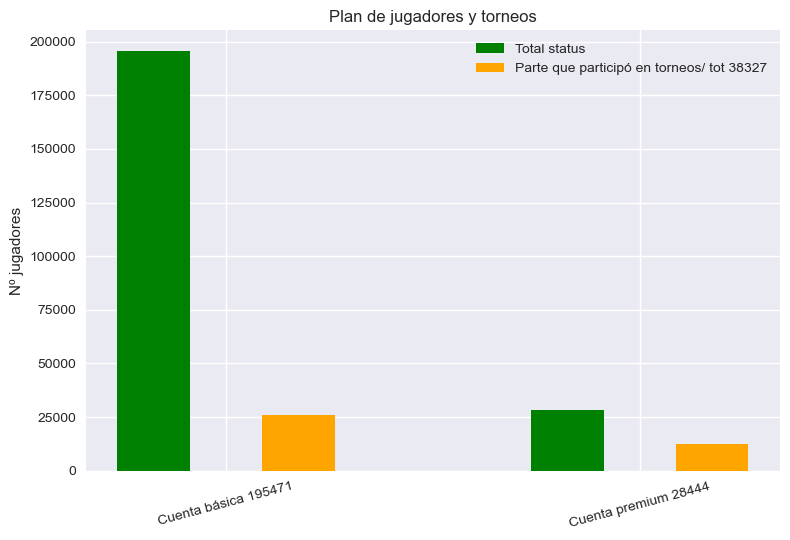

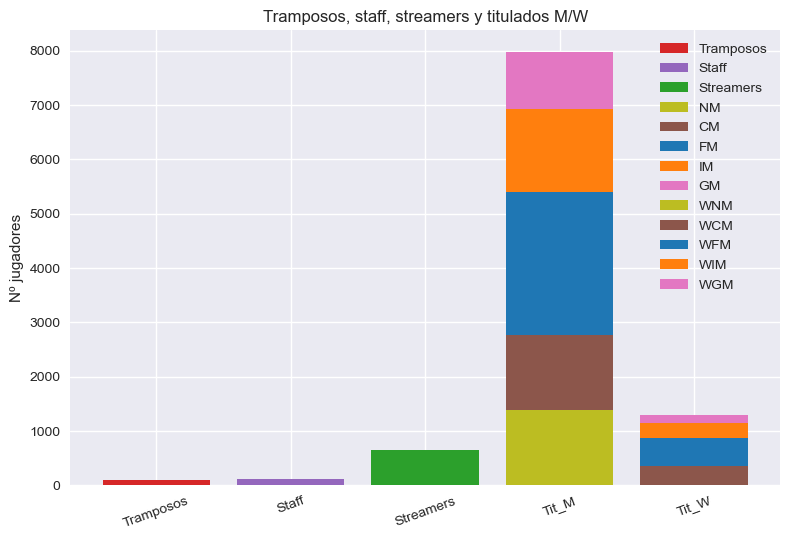

time: 438 ms (started: 2025-12-11 09:44:01 +01:00)


In [165]:
#G1
labels_status = [f"Cuenta básica {x_val}", f"Cuenta premium {y_val}"]
vals_status = [x_val, y_val]
x_pos = np.arange(len(labels_status))

#hugaron torneos
vals_tour = [conteos_status_tour.get("Cuenta básica", 0),conteos_status_tour.get("Cuenta premium", 0)]

plt.figure()
plt.bar(x_pos - 0.175, vals_status, width=0.175, color="green",  label="Total status")
plt.bar(x_pos + 0.175, vals_tour,   width=0.175, color="orange", label=f"Parte que participó en torneos/ tot {tournaments_val}")
plt.xticks(x_pos, labels_status, rotation=15)
plt.ylabel("Nº jugadores")
plt.title("Plan de jugadores y torneos")
plt.legend()
plt.tight_layout()
plt.show()

#G2

labels2 = ["Tramposos", "Staff", "Streamers", "Tit_M", "Tit_W"]
n2 = len(labels2)
x2 = np.arange(n2)#arange=array de 0-x=n2, [0,1,2,3...x]

vals_base = [tramposos_val, staffchesscom_val, streamers_val]
colors_base = ["tab:red", "tab:purple", "tab:green"]#si no muy vistoso

plt.figure()

for i in range(3):#primeros 3 de valores anteriores- pos,val,col,lab
    plt.bar(x2[i], vals_base[i], color=colors_base[i], label=labels2[i])

title_colors = {
    "FM": "tab:blue",
    "IM": "tab:orange",
    "NM": "tab:olive",
    "CM": "tab:brown",
    "GM": "tab:pink",
}

used_labels = set()  #leyenda final no repetir

#M
bottom_M = 0
for code in titles_M:
    v = titledM_val.get(code, 0)
    if v > 0:
        color = title_colors.get(code, "gray")  #default gris x si acaso
        lbl = code if code not in used_labels else None
        plt.bar(x2[3], v, bottom=bottom_M, color=color, label=lbl)
        bottom_M += v #bottom 0 abajo del to, x arriba del to
        used_labels.add(code)

#W
bottom_W = 0
for code in titles_W:
    v = titledW_val.get(code, 0)
    if v > 0:
        base = code[1:] if code.startswith("W") else code  #2 iniciales dsp de tit
        color = title_colors.get(base, "gray") 
        lbl = code if code not in used_labels else None
        plt.bar(x2[4], v, bottom=bottom_W, color=color, label=lbl)
        bottom_W += v #bottom 0 abajo del to, x arriba del to
        used_labels.add(code)


plt.xticks(x2, labels2, rotation=20)
plt.ylabel("Nº jugadores")
plt.title("Tramposos, staff, streamers y titulados M/W")
plt.legend()
plt.tight_layout()
plt.show()

Mayor proporción de fide mastrers (categoría intermedia) y existencia de tramposos, luego 12.7% de las cuentas son premium, el otro 87.3% son gratuitas, de las premium, la mitad participan en torneos y solo el 12% de gratuitas  participa en torneos.

#### **DISTRIBUCIÓN DE % WINS/LOSES/DRAWS DE UN PAÍS DE TODOS LOS MODOS AVG ~RD ~PARTIDAS**

In [168]:
dfwldg = (allmodes.groupby("country_name", as_index=False)[["total_wins", "total_losses", "total_draws", "total_games"]].sum())
dfwldg["winsp"] = 100* dfwldg["total_wins"] / dfwldg["total_games"]
dfwldg["lossp"] = 100* dfwldg["total_losses"] / dfwldg["total_games"]
dfwldg["drawsp"] = 100* dfwldg["total_draws"] / dfwldg["total_games"]

medw=dfwldg["winsp"].median()
medw=round(medw,2)

medl=dfwldg["lossp"].median()
medl=round(medl,2)

medd=dfwldg["drawsp"].median()
medd=round(medd,2)

dfwldg.describe()

,total_wins,total_losses,total_draws,total_games,winsp,lossp,drawsp
count,2.410000e+02,2.410000e+02,2.410000e+02,2.410000e+02,241.000000,241.000000,241.000000
mean,1.260328e+06,1.214034e+06,1.057820e+05,2.589258e+06,48.605045,47.110625,3.921865
std,1.227593e+06,1.153040e+06,1.149457e+05,2.500839e+06,0.409325,0.672218,0.437556
min,1.910600e+04,1.894100e+04,1.882000e+03,4.014800e+04,47.308600,43.565475,2.430993
25%,2.042210e+05,2.033950e+05,1.558800e+04,4.265080e+05,48.385829,46.813329,3.661541
50%,1.039399e+06,1.018680e+06,8.485700e+04,2.151306e+06,48.562032,47.210096,3.866529
75%,2.079282e+06,1.999351e+06,1.717380e+05,4.277782e+06,48.767481,47.526622,4.176922
max,1.022948e+07,8.818889e+06,1.119354e+06,2.024284e+07,50.706726,48.507424,5.825472


time: 94 ms (started: 2025-12-11 09:44:02 +01:00)


In [169]:
dfwldg_wins = (dfwldg.groupby(["country_name", "winsp"]).size().reset_index())
fig = px.choropleth(
    dfwldg_wins,
    locations="country_name",
    locationmode="country names",
    color="winsp",
    projection="natural earth",
    title=f"WINS POR PAÍS (Mediana: {medw}) (CUIDADO SESGO X BARRA)"
)

fig.update_layout(width=1000, height=800)
fig.show()

time: 47 ms (started: 2025-12-11 09:44:02 +01:00)


In [170]:
dfwldg_losses = (dfwldg.groupby(["country_name", "lossp"]).size().reset_index())
fig = px.choropleth(
    dfwldg_losses,
    locations="country_name",
    locationmode="country names",
    color="lossp",
    projection="natural earth",
    title=f"LOSSES POR PAÍS (Mediana: {medl}) (CUIDADO SESGO X BARRA)"
)

fig.update_layout(width=1000, height=800)
fig.show()

time: 47 ms (started: 2025-12-11 09:44:02 +01:00)


In [171]:
dfwldg_draws = (dfwldg.groupby(["country_name", "drawsp"]).size().reset_index())
fig = px.choropleth(
    dfwldg_draws,
    locations="country_name",
    locationmode="country names",
    color="drawsp",
    projection="natural earth",
    title=f"EMPATES POR PAÍS (Mediana: {medd}) (CUIDADO SESGO X BARRA)"
)

fig.update_layout(width=1000, height=800)
fig.show()

time: 47 ms (started: 2025-12-11 09:44:02 +01:00)


Estados Unidos es el país con mejor rendimiento medio, con muchas victorias y pocas derrotas, seguido sorprendentemente por la republica del congo y no por Rusia. España, por su parte, quedó algo por debajo de la media en victorias, algo por encima en derrotas, pero bastante encima en empates, lo que sugiere un estilo de juego sólido y prudente.


#### **ESTUDIO DE REGISTRO Y ÚLTIMA DESCONEXIÓN**

##### **DIFERENTES REGISTROS EN AÑOS Y MESES**

In [175]:
allmodes.dtypes

player_id                       int64
username                       object
gender                         object
country_code                   object
country_name                   object
title_code                     object
title_name                     object
status_code                    object
status_name                    object
is_cheater                      int64
is_streamer                     int64
in_club                         int64
in_tournament                   int64
followers                       int64
tournaments_played              int64
league                         object
registration_date      datetime64[ns]
last_seen              datetime64[ns]
total_games                   float64
total_wins                    float64
total_losses                  float64
total_draws                   float64
win_rate_overall              float64
loss_rate_overall             float64
draw_rate_overall             float64
overall_best_rating           float64
max_last_rat

time: 16 ms (started: 2025-12-11 09:44:05 +01:00)


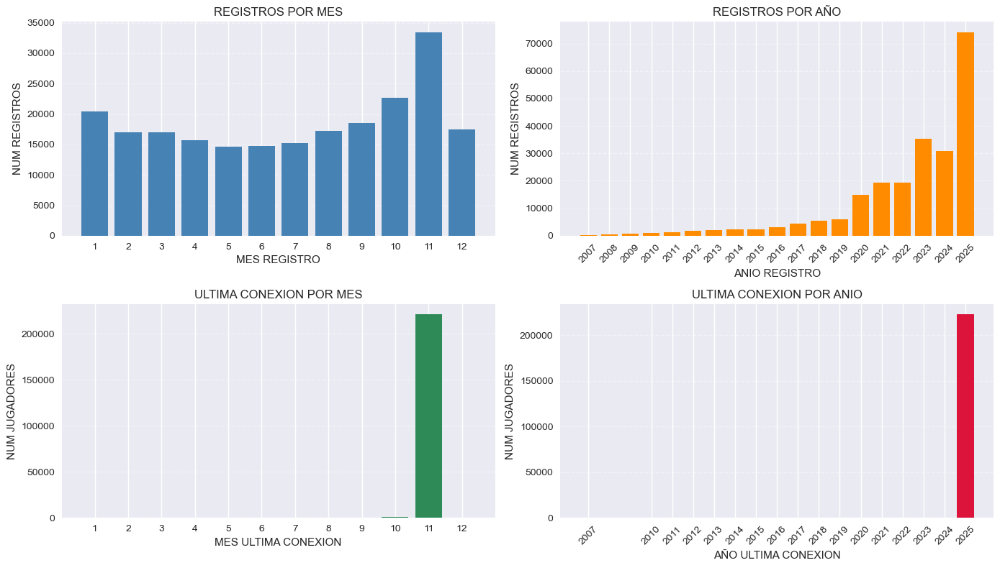

time: 968 ms (started: 2025-12-11 09:44:05 +01:00)


In [176]:
dfregmes = allmodes.groupby("reg_mes")["player_id"].count().reset_index(name="num_registros")
dfregyear = allmodes.groupby("reg_year")["player_id"].count().reset_index(name="num_registros")
dflastonmes=allmodes.groupby("seen_mes")["player_id"].count().reset_index(name="num_registros")
dflastonyear=allmodes.groupby("seen_year")["player_id"].count().reset_index(name="num_registros")

import matplotlib.pyplot as plt

#orden
dfregmes = dfregmes.sort_values("reg_mes")
dfregyear = dfregyear.sort_values("reg_year")
dflastonmes = dflastonmes.sort_values("seen_mes")
dflastonyear = dflastonyear.sort_values("seen_year")

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

#REG MES
axes[0, 0].bar(dfregmes["reg_mes"], dfregmes["num_registros"], color="steelblue")
axes[0, 0].set_xlabel("MES REGISTRO")
axes[0, 0].set_ylabel("NUM REGISTROS")
axes[0, 0].set_title("REGISTROS POR MES")
axes[0, 0].set_xticks(range(1, 13))

#REG AÑO
axes[0, 1].bar(dfregyear["reg_year"], dfregyear["num_registros"], color="darkorange")
axes[0, 1].set_xlabel("ANIO REGISTRO")
axes[0, 1].set_ylabel("NUM REGISTROS")
axes[0, 1].set_title("REGISTROS POR AÑO")
axes[0, 1].set_xticks(dfregyear["reg_year"])
axes[0, 1].tick_params(axis="x", rotation=45)

#SEEN MES
axes[1, 0].bar(dflastonmes["seen_mes"], dflastonmes["num_registros"], color="seagreen")
axes[1, 0].set_xlabel("MES ULTIMA CONEXION")
axes[1, 0].set_ylabel("NUM JUGADORES")
axes[1, 0].set_title("ULTIMA CONEXION POR MES")
axes[1, 0].set_xticks(range(1, 13))

#SEEN AÑO
axes[1, 1].bar(dflastonyear["seen_year"], dflastonyear["num_registros"], color="crimson")
axes[1, 1].set_xlabel("AÑO ULTIMA CONEXION")
axes[1, 1].set_ylabel("NUM JUGADORES")
axes[1, 1].set_title("ULTIMA CONEXION POR ANIO")
axes[1, 1].set_xticks(dflastonyear["seen_year"])
axes[1, 1].tick_params(axis="x", rotation=45)

for ax in axes.ravel():
    ax.grid(axis="y", linestyle="--", alpha=0.4)


plt.tight_layout()
plt.show()


#2020 EN ADELANTE PANDEMIA
#SPIKE 2023 https://www.chess.com/blog/CHESScom/chess-is-booming-and-our-servers-are-struggling
#webs aparte chess.com https://www.chess.com/forum/view/help-support/how-to-access-chess-com-if-its-blocked-at-school
# SEPT-NOV CLASES DIC Y JUN-AG VACACIONES,
#DATOS SESGADOS POR FETCHING SOLO DE JUGADORES RECIENTES DESCONECTADOS RANDOMS

#### **CONCLUSIÓN DE REGISTROS Y MARKETING**

##### Análisis de actividad y registros

La distribución de la última conexión por mes y por año está condicionada porque la API de Chess.com nos devuelve sobre todo cuentas **más recientes y más activas**, por tanto npc no nos interesa.

A partir de ahí miramos los **registros por mes y por año** (también se podría hacer lo mismo por horas y días de la semana, pero creo que es suficiente ver la distribución por mes y año para lo que quiero explicar).

##### Registros por mes

En la gráfica de registros por mes se observan dos picos y una zona con menos jugadores nuevos. Desde septiembre el número de registros aumenta, en octubre sube más, en noviembre alcanza el máximo y en diciembre baja. En enero vuelve a subir y, a partir de febrero, desciende de forma continuada. Este comportamiento indica que el interés por el ajedrez se concentra en septiembre, octubre, noviembre y enero, coincidiendo con el inicio del curso y las vacaciones de invierno y final de verano.

En épocas donde haya mayor actividad, podemos dirigirlo a estudiantes (colegios, institutos, universidades) y a trabajadores que vuelven de vacaciones buscando jugar en el trabajo, pero normalmente estos juegos se capan. Por lo tanto, el equipo de Chess.com ha intuido bien en realizar varios dominios alternativos para volver a Chess.com, como estos. 

https://www.schoolschoolschool.com/  
https://justdoinghomework.com  
https://www.pleasedontblockchess.com/  
https://www.superhardalgebraproblems.com/  
https://www.chezz.xyz  
https://C4355.com  

**url:** 
https://www.chess.com/forum/view/help-support/how-to-access-chess-com-if-its-blocked-at-school  

Luego tenemos las épocas con menos jugadores y menos registros, en meses como diciembre se pueden lanzar campañas de final de navidad o de año nuevo con torneos ligados a estas fechas o también asociadas a estudiar.

Desde febrero hasta junio se pueden hacer campañas tipo duolingo, donde el usuario tiene que conectarse para hacer una lección diaria. 

Y de junio a agosto se pueden lanzar campañas de verano, centradas en salir y jugar al aire libre, con lecciones personalizadas y ofertas de verano.

##### Registros por año

En el tramo 2007–2025 se ve una curva exponencial sobre todo en puntos clave como 2019–2020 (pandemia) y 2023, cuando Chess.com reconoce un pico muy alto de uso en su blog:  
https://www.chess.com/blog/CHESScom/chess-is-booming-and-our-servers-are-struggling  

A nivel de marketing, esto se traduce en dos líneas claras: incorporación de nuevos jugadores con procesos de entrada sencillos y sin presión, además de colar alguna oferta de premium, y retención de jugadores intermedios y avanzados mediante estadísticas, preparación de aperturas y ligas estructuradas a medio y largo plazo.

#### **ESTUDIO DE DISTRIBUCIÓN DE ELO X PAÍS Y RANGOS**

##### **MAX ELO Y MEDIANA COMPARISON DIF PAISES**

In [181]:
elop = allmodes.groupby("country_name", as_index=False)["max_last_rating"].agg(elomax="max", elomedian="median")
elopmed = elop[["country_name", "elomedian"]]
elopmax = elop[["country_name", "elomax"]]

meanmax_med = round(elopmed["elomedian"].mean(), 2)
meanmax_max = round(elopmax["elomax"].mean(), 2)

time: 78 ms (started: 2025-12-11 09:44:06 +01:00)


In [182]:
fig = px.choropleth(
    elopmax,
    locations="country_name",
    locationmode="country names",
    color="elomax",
    projection="natural earth",
    title=f"ELO MAXIMO POR PAIS (MEDIA: {meanmax_max}) (CUIDADO SESGO X BARRA)"
)

fig.update_layout(width=1000, height=800)
fig.show()

time: 47 ms (started: 2025-12-11 09:44:06 +01:00)


In [183]:
fig = px.choropleth(
    elopmed,
    locations="country_name",
    locationmode="country names",
    color="elomedian",
    projection="natural earth",
    title=f"ELO MEDIANA POR PAIS (MEDIA: {meanmax_med}) (CUIDADO SESGO X BARRA)"
)

fig.update_layout(width=1000, height=800)
fig.show()

time: 31 ms (started: 2025-12-11 09:44:06 +01:00)


Con los mapas de elomax y elomedian se vio que:

El Elo máximo por país fue muy alto en casi todo el mundo, indicando que los campeones mundiales estan distribuidos entre noruega, eeuu, rusia, india y francia. España (200pts detras del mejor)

La mediana de Elo sí diferenció países: la media global estuvo en ≈ 920, pero EEUU salió bastante por encima indicando un sesgo de campeones en eeuu repecto a otros paises y que hay sobre todo muchos jugadores principiantes.

##### **COMPARACIÓN DE ELO MÁX Y AVG ENTRE TITULADOS(M VS W) VS NO TITULADOS VS STREAMERS VS MEMBRESÍA**

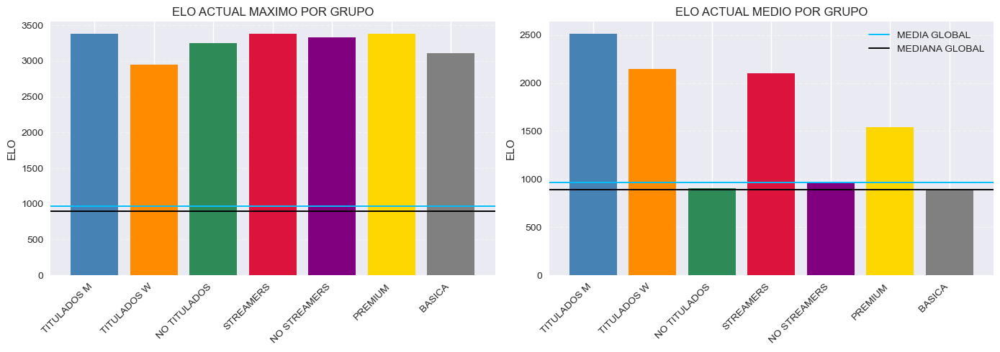

time: 687 ms (started: 2025-12-11 09:44:06 +01:00)


In [186]:
grupos = []  #lista grupos

media = allmodes["max_last_rating"].mean()
mediana = allmodes["max_last_rating"].median()

def add_grupo(nombre, filtro):
    data = allmodes[filtro]#filtra filas
    if data.empty:#sin jugadores
        return
    grupos.append({
        "grupo": nombre,
        "elo_last_max": data["max_last_rating"].max(),
        "elo_last_mean": data["max_last_rating"].mean()
    })

only_titled = allmodes["title_code"].notna()
starts_w = allmodes["title_code"].fillna("").str.startswith("W")#rellena nan y mira W, al reves da error ns pq
only_titled_w = only_titled & (starts_w == True)
only_titled_m = only_titled & (starts_w == False)
only_notitled = allmodes["title_code"].isna()

only_streamer = allmodes["is_streamer"] == 1
only_nostreamer = allmodes["is_streamer"] == 0

only_premium = allmodes["status_name"] == "Cuenta premium"
only_basica = allmodes["status_name"] == "Cuenta básica"

add_grupo("TITULADOS M", only_titled_m)
add_grupo("TITULADOS W", only_titled_w)
add_grupo("NO TITULADOS", only_notitled)
add_grupo("STREAMERS", only_streamer)
add_grupo("NO STREAMERS", only_nostreamer)
add_grupo("PREMIUM", only_premium)
add_grupo("BASICA", only_basica)

dfg = pd.DataFrame(grupos) #lista dicts-grupos

orden = ["TITULADOS M", "TITULADOS W", "NO TITULADOS",
         "STREAMERS", "NO STREAMERS", "PREMIUM", "BASICA"]

dfg = dfg.set_index("grupo")
dfg = dfg.loc[[g for g in orden if g in dfg.index]]#reordena
dfg = dfg.reset_index()

x = np.arange(len(dfg)) #long arr

colors = ["steelblue", "darkorange", "seagreen",
          "crimson", "purple", "gold", "gray"]
colors = colors[:len(dfg)]#ajusta longitud

fig, axes = plt.subplots(1, 2, figsize=(14, 5))#2 graficos

axes[0].bar(x, dfg["elo_last_max"], color=colors)#barras elo last max
axes[0].set_xticks(x)
axes[0].set_xticklabels(dfg["grupo"], rotation=45, ha="right")
axes[0].set_ylabel("ELO")
axes[0].set_title("ELO ACTUAL MAXIMO POR GRUPO")

axes[1].bar(x, dfg["elo_last_mean"], color=colors)#elo last medio
axes[1].set_xticks(x)
axes[1].set_xticklabels(dfg["grupo"], rotation=45, ha="right")
axes[1].set_ylabel("ELO")
axes[1].set_title("ELO ACTUAL MEDIO POR GRUPO")

axes[0].axhline(media,   color="deepskyblue", linestyle="-",  linewidth=1.4)#media sin label
axes[0].axhline(mediana, color="black",      linestyle="-", linewidth=1.4)#mediana sin label

axes[1].axhline(media,   color="deepskyblue", linestyle="-",  linewidth=1.4, label="MEDIA GLOBAL")
axes[1].axhline(mediana, color="black",      linestyle="-", linewidth=1.4, label="MEDIANA GLOBAL")
axes[1].legend()#solo segundo grafico

for ax in axes:#recorre ejesy (2 graficos)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout() #ajusta margenes xa que na se vea mal
plt.show()

titulados y basica mayoria de poblacion x eso tan cerca de la media
En los gráficos de Elo máximo y Elo medio por grupo se vio que:

Los titulados hombres y mujeres tuvieron los Elo máximos más altos 3400 aprox y medias muy por encima de la media global, aunque parece haber un hueco de elos medios y máximos entre hombres y mujeres. Y respecto los no titulados y no streamers, bajan mucho por los demás jugadores casuales.

Los jugadores premium tuvieron Elo medio mayor que los de cuenta básica: en torno a 1500 vs <1000. Eso reforzó la idea de que la suscripción se asoció a jugadores más serios y competitivos que llevan mucho mejor el juego.

Los streamers tuvieron Elo medio también alto, similar a titulados W o ligeramente inferior.

#### **CORRELACIÓN DE VARIABLES DE TODOS LOS MODOS AVG PEARSON, SPEARMAN****

In [189]:
allmodes[["league", "league_int"]].drop_duplicates().sort_values("league_int").head()

,league,league_int
18,None,-1
0,Legend,0
1,Champion,1
10,Elite,2
11,Crystal,3


time: 62 ms (started: 2025-12-11 09:44:07 +01:00)


In [190]:
corr_cols = allmodes.select_dtypes(include=[np.number]).columns#nums y bools
print(corr_cols)

Index(['player_id', 'is_cheater', 'is_streamer', 'in_club', 'in_tournament',
       'followers', 'tournaments_played', 'total_games', 'total_wins',
       'total_losses', 'total_draws', 'win_rate_overall', 'loss_rate_overall',
       'draw_rate_overall', 'overall_best_rating', 'max_last_rating', 'rd_avg',
       'gender_int', 'country_code_int', 'title_code_int', 'status_code_int',
       'league_int', 'reg_year', 'reg_mes', 'reg_sem', 'reg_hour', 'seen_year',
       'seen_mes', 'seen_sem', 'seen_hour', 'days_active'],
      dtype='object')
time: 32 ms (started: 2025-12-11 09:44:07 +01:00)


In [191]:
corr_pear = allmodes[corr_cols].corr(method="pearson")
corr_spear = allmodes[corr_cols].corr(method="spearman")
#el de keandall mejor no que muy comlicao y solo gana menormente en uno

abs_pear=corr_pear.abs()
abs_spear=corr_spear.abs()

#matriz
stack_vals = np.stack([corr_pear, corr_spear], axis=0)
stack_abs  = np.stack([abs_pear,  abs_spear],  axis=0)

best_idx = stack_abs.argmax(axis=0)#mejor método de medición 0=pearson,1=spearman, matriz de 0 y 1

methods = np.array(["pearson", "spearman"])

corr_max = np.take_along_axis(stack_vals, best_idx[None, :, :], axis=0)[0]#matriz más fuerte pone el de la matriz que gana

which_method = pd.DataFrame(methods[best_idx], index=corr_cols, columns=corr_cols)#método ganador ratón

time: 13.3 s (started: 2025-12-11 09:44:07 +01:00)


In [192]:
fig = px.imshow(
    corr_max,
    x=corr_cols,
    y=corr_cols,
    zmin=-1,
    zmax=1,
    color_continuous_scale="viridis"
)

fig.update_traces(customdata=which_method.values , hovertemplate="X: %{x}<br>Y: %{y}<br>método: %{customdata}<br>ρ = %{z:.3f}<extra></extra>")

fig.update_layout(width=1000, height=1000)
fig.show()

time: 78 ms (started: 2025-12-11 09:44:21 +01:00)


#### **VARIABLES IMPORTANTES Y LÓGICAS TB XA EDA**

- **Followers-streamers** poca hay muchos streamers pequeños sin followers

- **Wins+losses+draws ≈ total_games** por ello su relación de casí 1

- **Tournaments_played y total_games y clubes** cuanto más juegas más tiendes a descubrir donde jugar y relacionarte.

- No hay métodos fáciles de detección de **tramposos** si no es por analisis de partidas y tiempo constante de movimientos variables no disponibles.

- **Win_rate_overall** está relacionado inversamente con **loss_rate_overall y draw_rate_overall**

- **Overall_best_rating y max_last_rating** relacionados ya que uno llega a su máximo y aunque baja trata de superarse aumentando ambas (casi 1), estos a su vez son proporcionales al numero de victorias, derrotas y empates.

- **Rd_avg** suele estar negativamente correlacionado con **total_games, wins, loses draws etc** al jugar más, rd más estable se mueve menos.

- **Player_id y days_active** salen fuertemente correlacionados de forma negativas ya que chess.com asigna IDs autoincrement, los ids más bajos son cuentas más antiguas, **lo contrario con reg year** y un poco menos con **reg mes** ya que la relación es a más año más grande y se va disipando a más variables por año
algo parecido pasa con **dias activos y registro año y mes** ya que las demás se disipan y es **inversamente proporcional** y todo esto con el total de partidas elo y wins losses y draws por consecuencia ya que al estar más tiempo tienes capacidad de jugar más.

- **Genero y titulo** son inseparables ya que sacamos genero del titulo, lo mismo de **in tornament y torneos jugados**

- Los que estan en **clubs** tienen más oportunidades de  enterarse de torneos e interactuar con la gente dando **más followers, torneos jugados** y posibles invitaciones extra a jugar

- **La liga** esta relacionado con jugar cuantas **más partidas más avanzas de liga**, más partidas y por tanto **menos rd**, pero esta codificado como que la mayor liga es el menor número por eso es inversa proporcionalmente y por tanto es todo al revés.

### **ESTUDIO DE PARTIDAS DEL TOP 700 DE RÁPID (7-20 MIN~ APROX) + VARS QUE ANTES**

In [196]:
for col in gmr.columns:
    #print(col, "-", gmr[col].dtype)
    pass

time: 0 ns (started: 2025-12-11 09:44:21 +01:00)


#### **CORRELACIÓN DE VARIABLES DE TODOS LOS MODOS AVG PEARSON, SPEARMAN**

In [198]:
corr_base = gmr.select_dtypes(include=["number", "bool"]).columns #nums o bools

#quitar ids sin fondo analitico
cols_quitar = ["game_id", "list_id", "url_id","white_player_id", "black_player_id","mode_id","mode_name_int"]
corr_cols = [c for c in corr_base if c not in cols_quitar]

#coors
corr_pear  = gmr[corr_cols].corr(method="pearson")   # lineal, rápido
corr_spear = gmr[corr_cols].corr(method="spearman")  # orden/monótona
abs_pear  = corr_pear.abs()#abss
abs_spear = corr_spear.abs()

#matrices- [0]=pearson, [1]=spearman
stack_vals = np.stack([corr_pear,  corr_spear], axis=0)
stack_abs  = np.stack([abs_pear,   abs_spear],  axis=0)

#mjor metodo
best_idx = stack_abs.argmax(axis=0)
methods = np.array(["pearson", "spearman"])

#matriz ganadora
corr_max = np.take_along_axis(stack_vals, best_idx[None, :, :], axis=0)[0]
which_method = pd.DataFrame(methods[best_idx], index=corr_cols, columns=corr_cols)

time: 22.1 s (started: 2025-12-11 09:44:21 +01:00)


In [199]:
fig = px.imshow(
    corr_max,
    x=corr_cols,
    y=corr_cols,
    zmin=-1,
    zmax=1,
    color_continuous_scale="viridis"
)

fig.update_traces(
    customdata=which_method.values,
    hovertemplate=(
        "X: %{x}<br>"
        "Y: %{y}<br>"
        "método: %{customdata}<br>"
        "ρ = %{z:.3f}<extra></extra>"
    )
)
n = len(corr_cols)
fig.update_layout(width=1100, height=1100)
fig.show()

time: 93 ms (started: 2025-12-11 09:44:43 +01:00)


#### **VARIABLES DIFERENTES AL ANTERIOR ANÁLISIS**

- Se conforma un estilo de juego sólido con menos tonterías. las partidas donde el jugador blanco tiene un **%de empates mayor**, **el rival suele tenerlo tb** matchmaking parecido **drawrate 0.63 relacionado tb con best rating, mayor género, liga y membresía .46**, a mas alto el best rating más % tablas hay

- Ya sabiamos que más juegos implica descubrir cosas y por tanto más torneos / clubs / followers, pero en los tops descubrimos que **pertenecer a un club** no es del todo uniforme entre % hombres y mujeres **(gender)** y tipos de membresía **hombres + propensos al club/torneos/followers**

- al estar en el **top** es más probable estar en algún **club, tener más seguidores y de seguro jugar torneos** por tanto el % aumenta .48-.6 al estar más junto a una comunidad de apoyo, ya no es solo cuantas partidas, sino el nivel.

- Ratings cruzados **last y best** 0.63 aprox, buen matchmaking

- **los rds no se igualan mucho**, 0.2, lo que significa que **el matchmaking no disrtingue en expperiencia sino en tu másimo nivel** (no vol partidas sino máx elo)

- En **años recientes aparecen más jugadores con RD algo menor (experiencia)** (con más partidas jugadas) o simplemente el conjunto de activos tiene ya rating más estabilizado.

- Mucha relación entre **codigos, genero, mebresía, status, país, liga, y título**, no es random que te emparejen con tus stats parecidad, español con español, mujer vs mujer, premium vs premium etc, que este negativa solo es el orden de ints nada más

#### **DIAGRAMA DE BARRAS DE TITULADOS VS NO TITULADOS VS STREAMERS VS CLUBS VS TORNEOS**

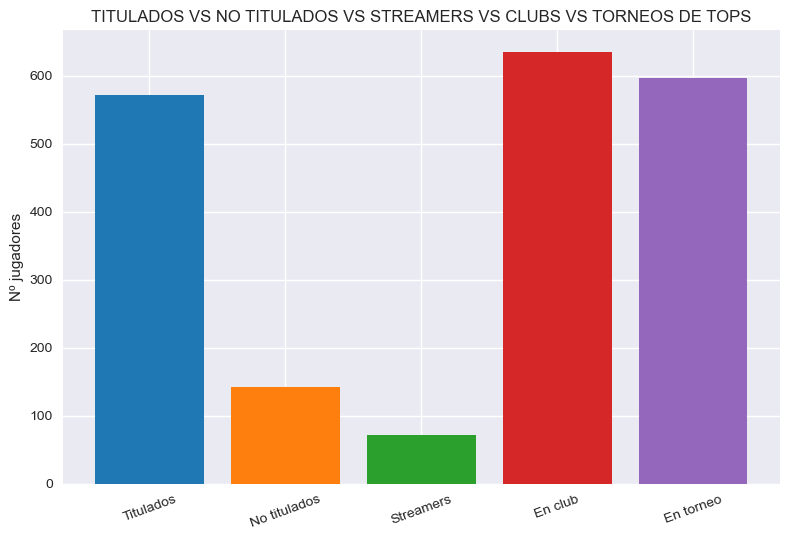

time: 562 ms (started: 2025-12-11 09:44:44 +01:00)


In [203]:
g = gmr.copy()
g = g[g["list_player_id"].notna()].copy()
g["is_white"] = g["white_player_id"] == g["list_player_id"]
g["is_black"] = g["black_player_id"] == g["list_player_id"]

g["player_title_code"]  = np.where(g["is_white"], g["white_title_code"],  g["black_title_code"])
g["player_is_streamer"] = np.where(g["is_white"], g["white_is_streamer"], g["black_is_streamer"])
g["player_in_club"]     = np.where(g["is_white"], g["white_in_club"],     g["black_in_club"])
g["player_in_tournament"] = np.where(g["is_white"], g["white_in_tournament"], g["black_in_tournament"])

#group
players = (
    g[["list_player_id",
       "player_title_code",
       "player_is_streamer",
       "player_in_club",
       "player_in_tournament"]]
    .drop_duplicates(subset=["list_player_id"])
)

players["is_titled"] = players["player_title_code"].notna() & (players["player_title_code"] != "")
n_titulados    = players["is_titled"].sum()
n_no_titulados = (~players["is_titled"]).sum()
n_streamers    = ((players["player_is_streamer"] == 1) | (players["player_is_streamer"] == "1")).sum()
n_club         = ((players["player_in_club"] == 1) | (players["player_in_club"] == "1")).sum()
n_torneos      = ((players["player_in_tournament"] == 1) | (players["player_in_tournament"] == "1")).sum()

labels = ["Titulados", "No titulados", "Streamers", "En club", "En torneo"]
vals   = [n_titulados, n_no_titulados, n_streamers, n_club, n_torneos]

x = np.arange(len(labels))
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]

plt.figure()
plt.bar(x, vals, color=colors)
plt.xticks(x, labels, rotation=20)
plt.ylabel("Nº jugadores")
plt.title("TITULADOS VS NO TITULADOS VS STREAMERS VS CLUBS VS TORNEOS DE TOPS")
plt.tight_layout()
plt.show()

De los tops 700, podemos observar que la mayoría están en un club, si no casi todos, han participado en torneos y son titulados. 
Un séptimo de ellos son streamers, y un sexto son no titulados.
Lo que significa que a nivel social tienen una gran comunidad y se relacionan con muchas personas, sobre todo los streamers, pero también hay gente no titulada suficientemente cualificada para entrar en el top mundial de cuentas de Chess.com.

#### **COMPARCIÓN EN EL MUNDO DEL TOP**

##### **TOP REPARTIDO X PAÍSES (parecido al otro gráfico)**

In [207]:
sql_sample_countries = """
        select 
        c.name as country_name,
        count(distinct p.id) as n_players
        from gamelist as lp
        inner join player as p 
        on p.id = lp.player_id
        join country as c 
        on c.code = p.country_code
        where lp.list_id is not null
        group by c.name
        order by n_players desc;
"""
dftops= pd.read_sql(sql_sample_countries, engine)

time: 16 ms (started: 2025-12-11 09:44:45 +01:00)


In [208]:
fig = px.choropleth(
    dftops,
    locations="country_name",
    locationmode="country names",
    color="n_players",
    hover_name="country_name",
    hover_data=["n_players"],
    projection="natural earth",
    title=f"TOPS REPARTIDOS POR EL MUNDO {len(dftops)} jugadores"
)

fig.update_layout(width=1000, height=800)
fig.show()

time: 62 ms (started: 2025-12-11 09:44:45 +01:00)


##### **APERTURAS PREFERIDAS POR PAISES (MAYORÍA)**

In [210]:
g = gmr.copy()#ASEGURO SI ES BLANCO O NEGRO
g["is_white"] = g["white_player_id"] == g["list_player_id"]
g["is_black"] = g["black_player_id"] == g["list_player_id"]
mask = g["is_white"] | g["is_black"]
g = g.loc[mask].copy()

g["player_country_name"] = np.where(g["is_white"],g["white_country_name"],g["black_country_name"])

g["eco_family"] = g["eco_code"].str[0]#primera letra

#A-E X SI ACASO
g_eco = g[g["eco_family"].isin(["A", "B", "C", "D", "E"])].copy()

#nº de partidas por país y familia ECO
eco_counts = (g_eco.groupby(["player_country_name", "eco_family"], as_index=False)["game_id"]
         .count().rename(columns={"player_country_name": "country_name","game_id": "n_games"}))

#país en filas, columnas = A,B,C,D,E con nº de partidas
eco_pivot = (eco_counts.pivot(index="country_name", columns="eco_family", values="n_games")
        .fillna(0).reset_index())

familias = ["A", "B", "C", "D", "E"]

# total partidas ECO por país
eco_pivot["total_games"] = eco_pivot[familias].sum(axis=1)#total eco x pais
eco_pivot["dominant_family"] = eco_pivot[familias].idxmax(axis=1)#max x pais


time: 1.08 s (started: 2025-12-11 09:44:45 +01:00)


In [211]:
fig = px.choropleth(
    eco_pivot,
    locations="country_name",
    locationmode="country names",
    color="dominant_family",
    hover_name="country_name",
    hover_data=["dominant_family", "total_games"] + familias,
    projection="natural earth",
    title="APERTURA PREFERIDA X MAYORÍA DE LOS TOPS"
)

fig.update_layout(width=1000, height=800)
fig.show()

time: 78 ms (started: 2025-12-11 09:44:46 +01:00)


LA FAMILIA DE E4 NO SEGUIDO DE E5/E3 ES LA APERTURA PREFERIDA POR LA MAYORÍA DE PARTIDAS SEGUIDA DE E4 Y E5/E6 Y D4. Esto nos puede dar una pista de que líneas son más sólidas y tienen mejores posibilidades de ganar yt por ende que hay que estudiar

In [213]:
#show_group("BG", None, dfeconum, gmr,max_plies=40, manual_patterns=C89_str, draw_forbiddens=True, nopeningsinfomax=5)

time: 0 ns (started: 2025-12-11 09:44:46 +01:00)


#### **DIFERENTES TIPOS DE RESULTADOS A NIVEL MUNDIAL CON HEATMAP**

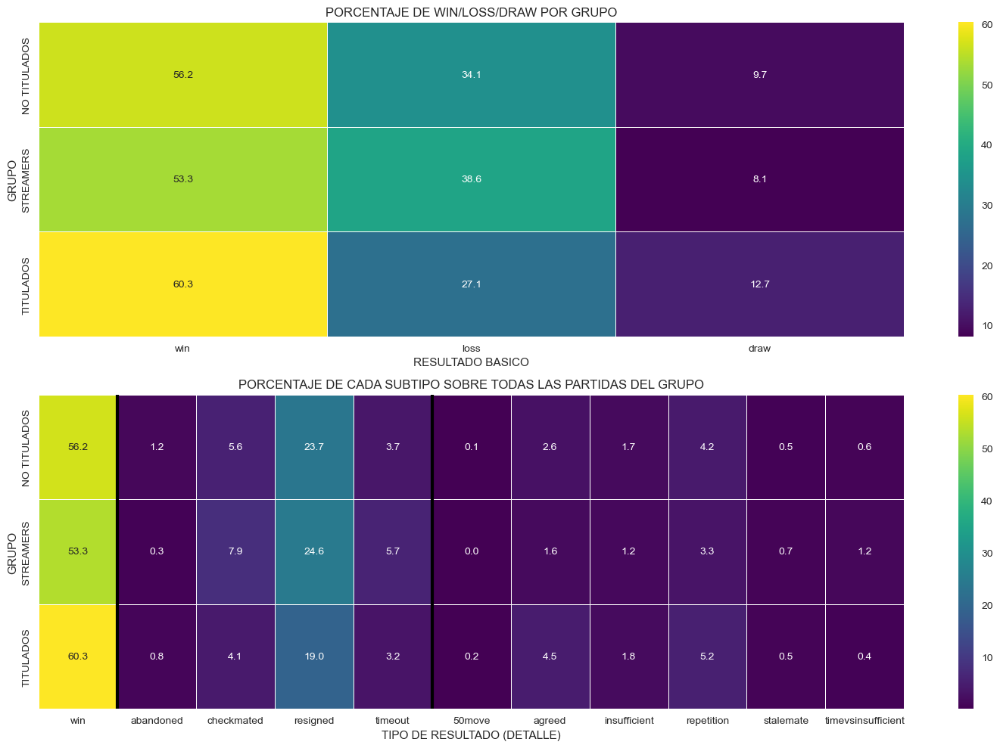

time: 1.12 s (started: 2025-12-11 09:44:46 +01:00)


In [215]:
g = gmr.copy()
g["is_white"] = g["white_player_id"] == g["list_player_id"]  #Comprobar si blanco o negro
g["is_black"] = g["black_player_id"] == g["list_player_id"]

#jug lista
mask = g["is_white"] | g["is_black"]
g = g.loc[mask].copy()

#segun lo que sea
g["player_elo"]         = np.where(g["is_white"], g["white_elo"],        g["black_elo"])
g["player_title_code"]  = np.where(g["is_white"], g["white_title_code"], g["black_title_code"])
g["player_is_streamer"] = np.where(g["is_white"], g["white_is_streamer"], g["black_is_streamer"])

#grupos
g["group"] = "NO TITULADOS"
g.loc[g["player_is_streamer"] == 1, "group"] = "STREAMERS"

mask_titled = g["player_title_code"].notna() & (g["player_title_code"] != "")
g.loc[mask_titled, "group"] = "TITULADOS"

result_map = {
    "win": "win",
    "lose": "loss",
    "checkmated": "loss",
    "resigned": "loss",
    "timeout": "loss",
    "abandoned": "loss",
    "agreed": "draw",
    "repetition": "draw",
    "stalemate": "draw",
    "insufficient": "draw",
    "50move": "draw",
    "timevsinsufficient": "draw"
}

g["result_basic"] = g["result"].map(result_map).fillna("unknown")#resultado win,loss,win etc (dict)

#1
tab_basic = (g.groupby(["group", "result_basic"])["game_id"].count().reset_index(name="n"))
tab_basic["pct"] = tab_basic.groupby("group")["n"].transform(lambda x: x / x.sum() * 100)#%
data_basic = (tab_basic.pivot(index="group", columns="result_basic", values="pct").fillna(0))
cols_order = ["win", "loss", "draw", "unknown"]
data_basic = data_basic[[c for c in cols_order if c in data_basic.columns]]

#2

tab_detail = (g.groupby(["group", "result_basic", "result"])["game_id"].count().reset_index(name="n"))
tab_detail["pct_total"] = (tab_detail["n"] /tab_detail.groupby("group")["n"].transform("sum") * 100)
data_detail = (tab_detail.pivot(index="group", columns="result", values="pct_total").fillna(0))
detail_cols = list(data_detail.columns)
detail_cols_sorted = ( #3 cols
    [c for c in detail_cols if result_map.get(c, "unknown") == "win"] +
    [c for c in detail_cols if result_map.get(c, "unknown") == "loss"] +
    [c for c in detail_cols if result_map.get(c, "unknown") == "draw"] +
    [c for c in detail_cols if result_map.get(c, "unknown") not in ["win", "loss", "draw"]]
)
data_detail = data_detail[detail_cols_sorted]

#ambos labels y otros
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), sharex=False)
#1
sns.heatmap(
    data=data_basic,
    annot=True,
    fmt=".1f",
    linewidths=.5,
    cmap="viridis",
    ax=ax1
)
ax1.set_xlabel("RESULTADO BASICO")
ax1.set_ylabel("GRUPO")
ax1.set_title("PORCENTAJE DE WIN/LOSS/DRAW POR GRUPO")

#2
sns.heatmap(
    data=data_detail,
    annot=True, #%
    fmt=".1f",
    linewidths=.5,
    cmap="viridis",
    ax=ax2
)
ax2.set_xlabel("TIPO DE RESULTADO (DETALLE)")
ax2.set_ylabel("GRUPO")
ax2.set_title("PORCENTAJE DE CADA SUBTIPO SOBRE TODAS LAS PARTIDAS DEL GRUPO")

basic_for_cols = [result_map.get(c, "unknown") for c in data_detail.columns]
#xa separar en 2 el de abajo
boundaries = []
current = basic_for_cols[0]
for idx, b in enumerate(basic_for_cols):
    if b != current:
        boundaries.append(idx)
        current = b

for b in boundaries:
    ax2.axvline(b, color="black", linewidth=3)

plt.tight_layout()
plt.show()

La mayoría de derrotas son serias abandono por resignacion y no por abandono (desconexión) ya que estos tienen un mayor control sobre los posibles mates y jugads interesantes y saben cuando algo esta perdido.

En titulados, el peso de repetition y agreed sobre el conjunto de tablas era mayor, lo que indica mucha técnica de defensa y acuerdos racionales en posiciones igualadas.

En no titulados y streamers, crecían más checkmated y abandoned (mates reales y desconexiones/abandono), encajando con un juego más caótico y distraido y menos concentrado y racional

Resigned = derrota por rendición explícita (apretar botón de rendirse)
Abandoned = derrota porque el jugador dejó la partida (desconexión / cierre / no vuelve / algoritmo)

#### **ELO COMPARACIÓN CON RIVAL, SI MAYOR/MENOR Y GANO/PERDIÓ**

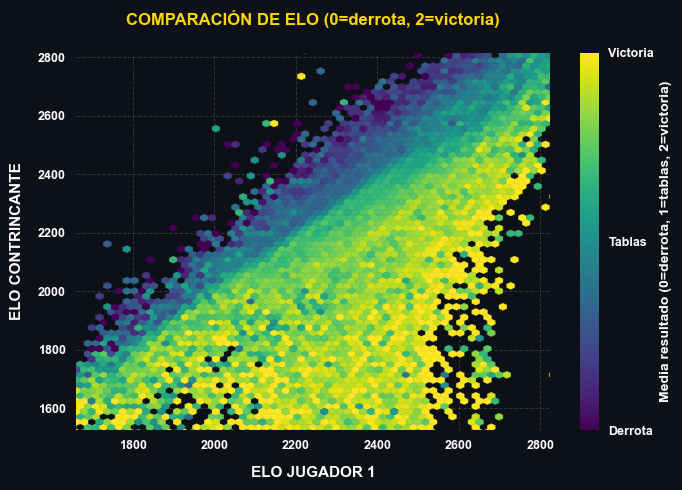

time: 1.55 s (started: 2025-12-11 09:44:48 +01:00)


In [219]:
g = gmr.copy()
g = g[g["list_player_id"].notna()].copy()  # solo partidas donde aparece la lista

g["is_white"] = g["white_player_id"] == g["list_player_id"]
g["is_black"] = g["black_player_id"] == g["list_player_id"]
g["player_elo"] = np.where(g["is_white"], g["white_elo"], g["black_elo"])#x
g["opp_elo"]    = np.where(g["is_white"], g["black_elo"], g["white_elo"])#x oponente

result_map = {
    "win": "win",
    "lose": "loss",
    "checkmated": "loss",
    "resigned": "loss",
    "timeout": "loss",
    "abandoned": "loss",
    "agreed": "draw",
    "repetition": "draw",
    "stalemate": "draw",
    "insufficient": "draw",
    "50move": "draw",
    "timevsinsufficient": "draw"
}

g["result_basic"] = g["result"].map(result_map).fillna("unknown")
g = g[g["result_basic"].isin(["win", "loss", "draw"])].copy()#solo win/loss/draw
g = g[(g["player_elo"] >= 1500) & (g["opp_elo"] >= 1500)].copy()#no partidas tontas cuentas sec o mias
res_code_map = {"loss": 0.0, "draw": 1.0, "win": 2.0}#0 loss 1 draw 2 win
g["result_code"] = g["result_basic"].map(res_code_map)
df_hr = g.dropna(subset=["player_elo", "opp_elo", "result_code"]).copy()#drop na

#quito valores demasiado afuera (percentiles)
x_lo, x_hi = np.percentile(df_hr["player_elo"], [0.5, 99.5])
y_lo, y_hi = np.percentile(df_hr["opp_elo"],   [0.5, 99.5])

plt.figure(figsize=(7, 5))
ax = plt.gca()
#me copio de gaiadr3
hb = ax.hexbin(
    df_hr["player_elo"],
    df_hr["opp_elo"],
    C=df_hr["result_code"],
    reduce_C_function=np.mean,
    gridsize=80,
    cmap="viridis",
    mincnt=3 #si no demasiadas
)

#tema oscuro si no no se ve
ax.set_facecolor("#0d1117")
plt.gcf().patch.set_facecolor("#0d1117")

ax.set_xlabel("ELO JUGADOR 1", fontsize=11, fontweight="bold",
              color="white", labelpad=10)
ax.set_ylabel("ELO CONTRINCANTE", fontsize=11, fontweight="bold",
              color="white", labelpad=10)
ax.set_title("COMPARACIÓN DE ELO (0=derrota, 2=victoria)",
             fontsize=12, fontweight="bold", color="gold", pad=20)


ax.set_xlim(x_lo, x_hi)
ax.set_ylim(y_lo, y_hi)

# rejilla y ticks blancos
ax.grid(alpha=0.3, linestyle="--", linewidth=0.7, color="gray")
ax.tick_params(axis="x", colors="white", labelsize=9)
ax.tick_params(axis="y", colors="white", labelsize=9)
for t in ax.get_xticklabels() + ax.get_yticklabels():
    t.set_color("white")
    t.set_fontweight("bold")

# colorbar: 0,1,2 → derrota, tablas, victoria
cb = plt.colorbar(hb)
cb.set_label("Media resultado (0=derrota, 1=tablas, 2=victoria)",
             fontsize=10, fontweight="bold", color="white")
cb.ax.yaxis.set_tick_params(color="white", labelsize=9)

cb.set_ticks([0, 1, 2])
cb.set_ticklabels(["Derrota", "Tablas", "Victoria"])
for t in cb.ax.get_yticklabels():
    t.set_color("white")
    t.set_fontweight("bold")

plt.tight_layout()
plt.show()

Zona de empate mas gorda en la punta por consolidación y juego mejor y menos aleatorio (una partida de ajedrez perfecta acaba en tablas) y por en medio, rival mucho mas elo pierdo seguro y viceversa aunque puede pasar que uno de bajo nivel le gane a otro de mucho eso es un despiste/valor atípico/error/etc

#### **RESULTADOS SEGÚN BLANCAS VS NEGRAS Y TITULADOS VS NO TITULADOS VS STREAMERS ORDENADOS X ELO**

##### **%WINS/PERDIDAS/EMPATES TITULADOS/NO TITULADOS/STREAMERS**

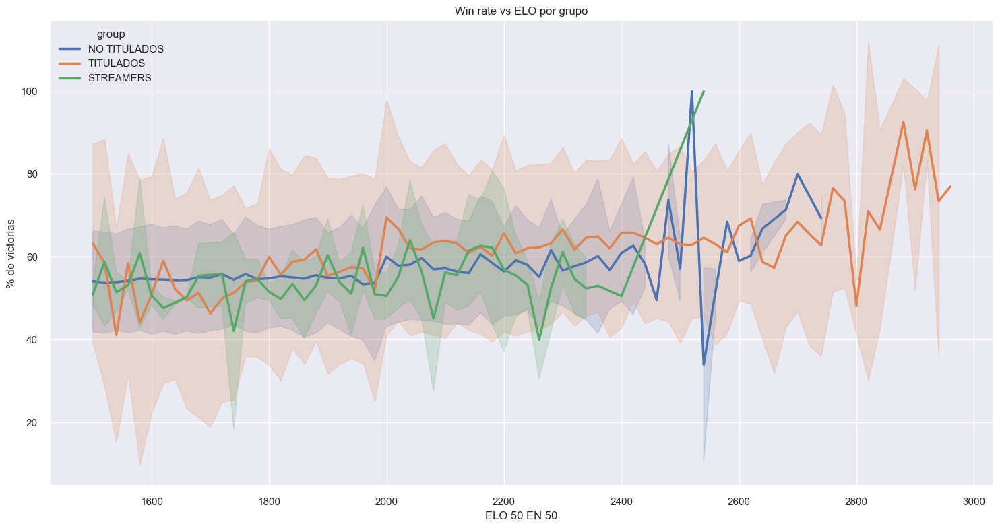

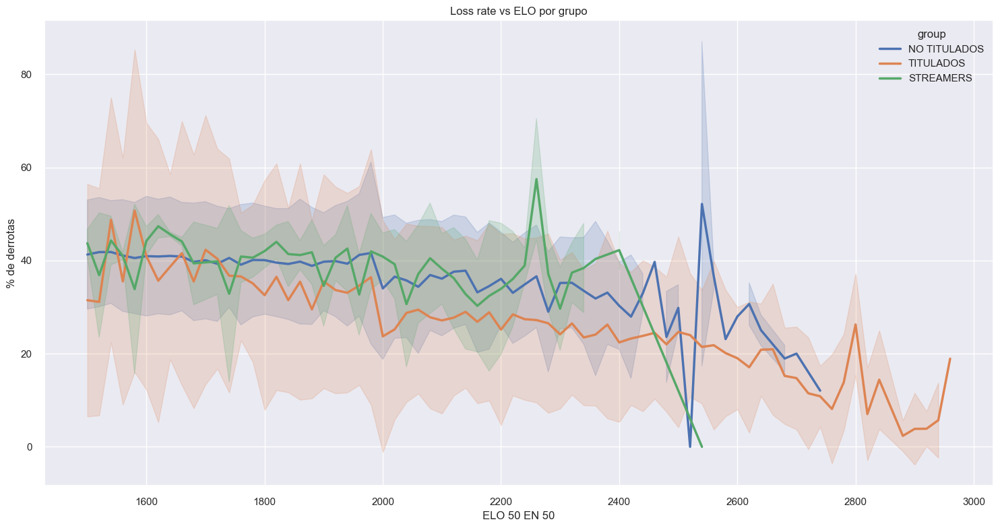

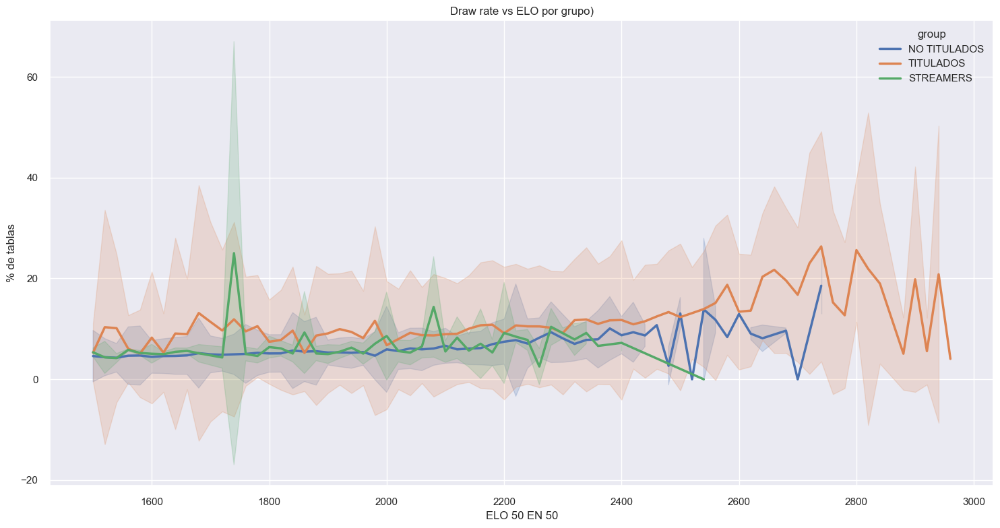

time: 1.45 s (started: 2025-12-11 09:44:49 +01:00)


In [223]:
dfp = onemode_rapid.copy() 
dfp = dfp[dfp["mode_last_rating"] > 1500].copy()
dfp["group"] = "NO TITULADOS"
dfp.loc[dfp["is_streamer"] == 1, "group"] = "STREAMERS"
mask_titled = dfp["title_code"].notna() & (dfp["title_code"] != "")
dfp.loc[mask_titled, "group"] = "TITULADOS"#VOY AÑADIENDO AL GRUPO COSAS

#% del modo
g_tot = dfp["mode_total_games"].replace(0, np.nan) #0/0!!!!
dfp["win_pct"]  = dfp["mode_total_wins"]   / g_tot * 100
dfp["loss_pct"] = dfp["mode_total_losses"] / g_tot * 100
dfp["draw_pct"] = dfp["mode_total_draws"]  / g_tot * 100

#bins de 50 ELOdel modo
dfp["elo_bin"] = (dfp["mode_last_rating"] // 20) * 20   #50pts bins
dfp = dfp.sort_values("elo_bin")

sns.set(rc={"figure.figsize": (15, 8)})

#WINS
plt.figure()
sns.lineplot(
    data=dfp,
    x="elo_bin",
    y="win_pct",
    hue="group",
    estimator="mean",#MEDIA DE LOS QUE CAIGAN AHI
    errorbar="sd",#DESVIACION ESTANDAR
    linewidth=2.5
)
plt.xlabel("ELO 50 EN 50")
plt.ylabel("% de victorias")
plt.title("Win rate vs ELO por grupo")
plt.tight_layout()
plt.show()

#LOSES
plt.figure()
sns.lineplot(
    data=dfp,
    x="elo_bin",
    y="loss_pct",
    hue="group",
    estimator="mean",
    errorbar="sd",
    linewidth=2.5
)
plt.xlabel("ELO 50 EN 50")
plt.ylabel("% de derrotas")
plt.title("Loss rate vs ELO por grupo")
plt.tight_layout()
plt.show()

#DRAWS
plt.figure()
sns.lineplot(
    data=dfp,
    x="elo_bin",
    y="draw_pct",
    hue="group",
    estimator="mean",
    errorbar="sd",
    linewidth=2.5
)
plt.xlabel("ELO 50 EN 50")
plt.ylabel("% de tablas")
plt.title("Draw rate vs ELO por grupo)")
plt.tight_layout()
plt.show()

Los picos nos enseñan que no hay muchos datos con los que traabjar y sobre todo se encuentran al final, copn + elo, al ser pocos los streamers, los no titulados y muchas sus distracciones, no hay muchas partidas, hay mucho más ruido y por eso tanto pico, en general la tasa de victorias con desviacion incluida suele ir pa arriba >50% a más rating, al igual que la de empates rozando de media el 10% y subiendo, y la tasa e derrotas para abajo

##### **VICTORIAS/DERROTAS/EMPATES Y VENTAJA SEGÚN BLANCAS O NEGRAS**

% victorias blancas: 61.35
% victorias negras:  57.43
% empate ratio:  -0.30
DIF% (blancas - negras): 3.91% ventaja blancas
Puntuación media blancas: 0.673
Puntuación media negras:  0.635
Ventaja de blancas: 0.038 centipeones


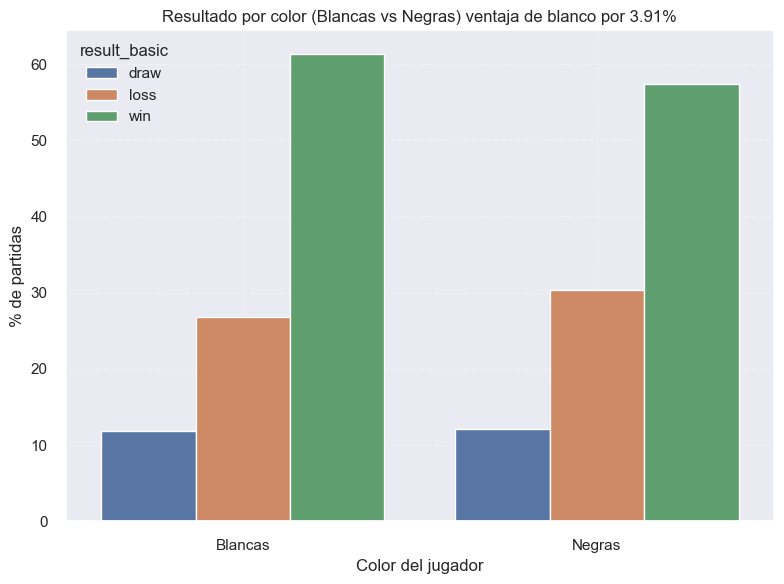

time: 719 ms (started: 2025-12-11 09:44:51 +01:00)


In [226]:
g = gmr.copy()
g["is_white"] = g["white_player_id"] == g["list_player_id"]
g["is_black"] = g["black_player_id"] == g["list_player_id"]
mask = g["is_white"] | g["is_black"]
g = g.loc[mask].copy()
result_map = {
    "win": "win",
    "lose": "loss",
    "checkmated": "loss",
    "resigned": "loss",
    "timeout": "loss",
    "abandoned": "loss",
    "agreed": "draw",
    "repetition": "draw",
    "stalemate": "draw",
    "insufficient": "draw",
    "50move": "draw",
    "timevsinsufficient": "draw"
}
g["result_basic"] = g["result"].map(result_map).fillna("unknown")

# color desde el punto de vista del jugador de la lista
g["color"] = np.where(g["is_white"], "Blancas", "Negras")

# tabla de % por color y resultado
tab = (
    g.groupby(["color", "result_basic"])["game_id"]
     .count()
     .reset_index(name="n")
)
tab["pct"] = tab.groupby("color")["n"].transform(lambda x: x / x.sum() * 100)

tab_p = (
    tab.pivot(index="color", columns="result_basic", values="pct")
       .fillna(0)
)
win_white  = tab_p.loc["Blancas", "win"]
win_black  = tab_p.loc["Negras", "win"]
draw_white = tab_p.loc["Blancas", "draw"]
draw_black = tab_p.loc["Negras", "draw"]
loss_white = tab_p.loc["Blancas", "loss"]
loss_black = tab_p.loc["Negras", "loss"]

diff_win  = win_white  - win_black
diff_loss = loss_black - loss_white  #“ventaja” adicional porque pierden menos
diff_draw = draw_white - draw_black  # aquí debería ser ~0

print(f"% victorias blancas: {win_white:.2f}")
print(f"% victorias negras:  {win_black:.2f}")
print(f"% empate ratio:  {diff_draw:.2f}")
print(f"DIF% (blancas - negras): {diff_win:.2f}% ventaja blancas")

score_white = (win_white + 0.5 * draw_white) / 100 #1win 1/2 draw 0lose
score_black = (win_black + 0.5 * draw_black) / 100 
adv_score   = score_white - score_black 

print(f"Puntuación media blancas: {score_white:.3f}")
print(f"Puntuación media negras:  {score_black:.3f}")
print(f"Ventaja de blancas: {adv_score:.3f} centipeones") #1 peón=100 centipeones

sns.set(rc={"figure.figsize": (8, 6)})
plt.figure()
sns.barplot(data=tab, x="color", y="pct", hue="result_basic")
plt.ylabel("% de partidas")
plt.xlabel("Color del jugador")
plt.title(f"Resultado por color (Blancas vs Negras) ventaja de blanco por {diff_win/100:.2%}")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

#### **DEMOSTRACIÓN VENTAJA INICIAL BLANCAS**

Sveshnikov ya lo resumió muy bien en 1994: «Los jugadores que conducen las negras no pueden permitirse ni el más ligero error... desde un punto de vista teórico, las tareas de las blancas y las negras en ajedrez son diferentes: las blancas van a por la victoria, las negras a por las tablas». A lo largo del siglo XX, la idea de “White to Play and Win” con autores como Adams defendían que 1.e4 era el movimiento más fuerte precisamente porque era el que aprovechaba más la ventaja inicial al dar paso a piezas como la dama y alfil al tiempo que controlas el centro. 

Cuando se mira a los números de millones de partidas sobre todo de expertos, aproximandose al nivel computacional, esa sospecha se confirma. En una base de datos formada por partidas entre jugadores expertos (top 700 mundial), las blancas ganan aproximadamente un 3,8 % más que las negras, y por tanto el puntaje de media, las blancas suman unos 0,04 puntos más por partida que las negras. Con una media de 10 partidas: alrededor de 0,38 puntos extra, encajado casi milimétricamente con lo que dicen los motores modernos como stockfish o torch: ellos valoran la posición inicial en torno a +0,3 peones para el blanco. La unidad es distinta (peones en el motor vs puntos en el marcador), hablamos de “un tercio de peón” frente a “un tercio de punto cada diez partidas”.Al acercar al poder computacional como ocurre con la élite, los datos humanos y la evaluación de los engines confirman que el blanco no solo mueve primero; parte con una pequeña ventaja inicial QED.

##### **VENTAJA SEGÚN MOTOR /FOTO/ (STOCKFISH 17.1)**

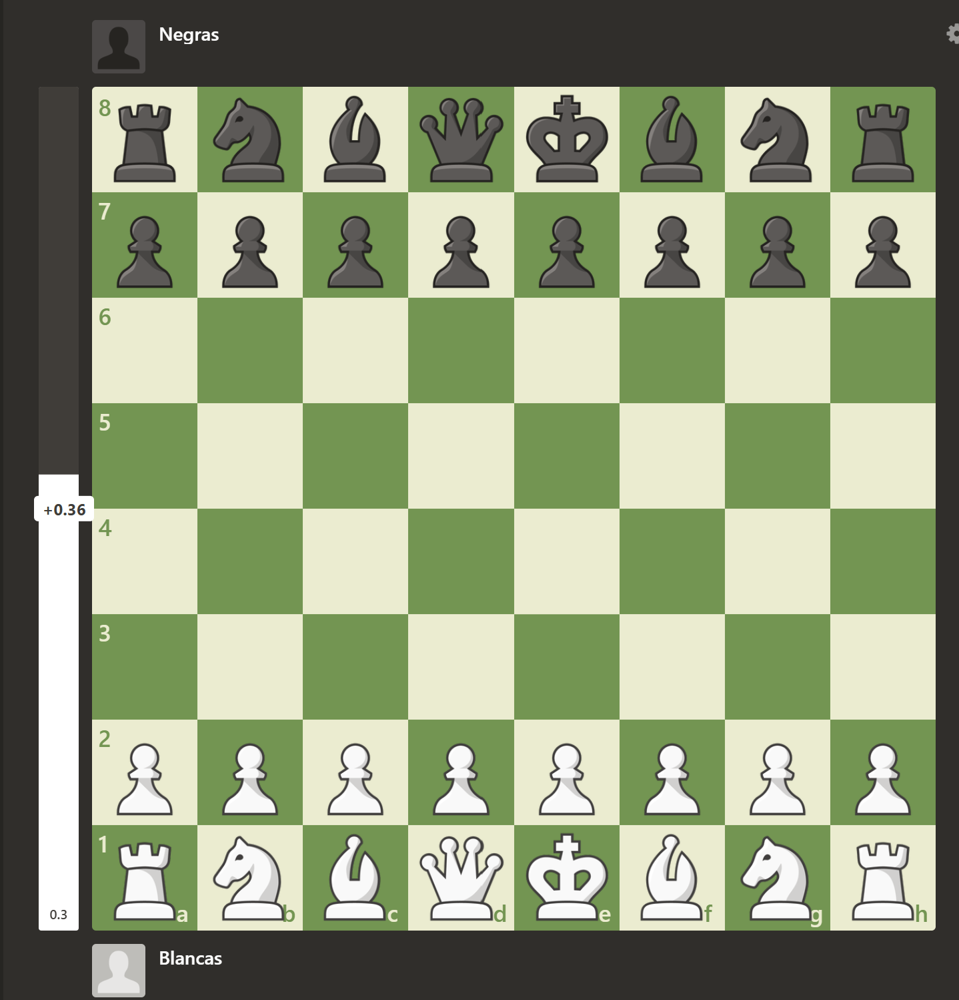

#### **APERTURA PROBABILIDAD TABLERO**

##### **TABLERO DISPLAY + EJEMPLOS**

###### **APERTURA DETALLES SEGÚN PATRONES DE ECO_CODE DENTRO DE LIBRERIA PATTERNS**

In [234]:
def find_patterns_for_code(eco_code, eco_patterns):
    if eco_patterns is None or not isinstance(eco_code, str):
        return []
        
    #cosas raras
    if any(ch in eco_code for ch in "[]{}#+@$&"): #or de todos
        return []

    #ojo esta
    if eco_code in eco_patterns:
        return eco_patterns[eco_code]

    #x prefijo
    matches = [
        k for k in eco_patterns.keys()
        if isinstance(k, str) and k.startswith(eco_code)
    ]

    if not matches:
        return []

    raw = []
    for k in matches:
        v = eco_patterns[k]
        if not v: #espacios quitar
            continue
        if isinstance(v[0], str): #un arr
            raw.append(v)
        else: #varios arrs
            raw.extend(v)

    return raw

time: 16 ms (started: 2025-12-11 09:44:53 +01:00)


###### **PGN A PATERN LEIBLE**

In [236]:
#color normal y prohibido
SIMPLE_COLOR=PLY_COLOR = "#0080ff"       # flecha azul para el movimiento actual
FORBIDDEN_COLOR = "#ff0000" # flecha roja = movimiento prohibido

#PGN-SAN
#pgn/chess.com/pub ó formato mio
def pgn_to_pattern(mismovs):

    text = str(mismovs)
    m_json = re.search(r'"pgn"\s*:\s*"(.*)"', text, re.DOTALL) #LO MISMO QUE WEBSCRAPING (DOTALL XA QUE \n ocurra
    if m_json:
        raw_pgn = m_json.group(1)
        text = bytes(raw_pgn, "utf-8").decode("unicode_escape") #de binaroi a normal xa que cosas como \n funcionen

    m_moves = re.search(r'\b1\.', text)#primer 1 donde esta 1. Nf3 ns
    if m_moves:
        text = text[m_moves.start():]

    #Conjunto de caracteres que pueden aparecer en un movimiento SAN
    allowed = set("abcdefgh12345678KQRBNx#+=O-")

    board = chess.Board()
    san_list = []

    i = 0
    n = len(text)

    while i < n: #dentro dde las jugadas limpio cosas que no lo son como clks etc
        ch = text[i]

        #Espacios y saltos de línea
        if ch.isspace():
            i += 1
            continue

        #comentarios entre llaves { ... } (incluye clocks {[%clk ...]})
        if ch == "{":
            i += 1
            while i < n and text[i] != "}":
                i += 1
            if i < n:
                i += 1
            continue

        #Cabeceras PGN con [Event ...] por si no recortamos bien antes
        if ch == "[":
            i += 1
            while i < n and text[i] not in ["]", "\n"]:
                i += 1
            if i < n:
                i += 1
            continue

        #Resultados finales 1-0, 0-1, 1/2-1/2
        if text.startswith("1-0", i) or text.startswith("0-1", i) or text.startswith("1/2-1/2", i):
            break

        #Números de jugada: "1." o "1..." sin importar espacios
        if ch.isdigit():
            k = i
            while k < n and text[k].isdigit():
                k += 1
            if k < n and text[k] == ".":
                k += 1
                while k < n and text[k] == ".":
                    k += 1
                i = k
                continue

        # Caracteres que no forman parte de SAN (comas, paréntesis, etc.)
        if ch not in allowed:
            i += 1
            continue

        #Intentamos encontrar el movimiento SAN más largo posible desde esta posición, si se encuentra otra dsp se sobreescribe
        max_len = min(n, i + 12)
        best = None
        best_end = None
        j = i

        while j < max_len and text[j] in allowed:#aumento j hasta encontrar algo valido desde anterior end, si lo es lo guardo en best
            cand = text[i:j + 1]
            try:
                board.parse_san(cand)#si eto no da error (jugadas validas)
                best = cand
                best_end = j + 1
            except Exception:
                pass
            j += 1

        #ningun san valido +1caracter
        if best is None:
            i += 1
            continue

        #san + largo
        try:
            move = board.parse_san(best)
        except ValueError:
            print(f"Mov incorrecto!: {move}")
            break
        else:
            board.push(move)
            san_list.append(best)
            i = best_end

    return san_list

time: 0 ns (started: 2025-12-11 09:44:53 +01:00)


###### **JUGADAS PERMITIDAS VS PROHIBÍDAS soporta varios =! separados por un mov cada uno**

In [238]:
def extract_moves_and_forbidden(pat):
    #NO =!
    if "!=" not in pat:
        return list(pat), []

    #!= >=1
    n_bang = pat.count("!=")

    #TODO DSP ES PROHIBIDO si 1
    if n_bang == 1:
        idx = pat.index("!=")
        moves = [tok for tok in pat[:idx] if tok != "!="]#antes
        forbiddens = [tok for tok in pat[idx + 1:] if tok != "!="]#dsp
        return moves, forbiddens

    #!=>=2
    moves = []
    forbiddens = []
    i = 0

    while i < len(pat):
        token = pat[i]
        if token == "!=":
            if i + 1 < len(pat):
                forbiddens.append(pat[i + 1])
                i += 2 #salto al sig mov que haya prohibido
            else:
                i += 1
        else:
            moves.append(token)
            i += 1
            
    """
      Formato antiguo:
         ["d4","Nf6","!=","c4","!=","e4"]
         moves      = ["d4","Nf6"]
         forbiddens = ["c4","e4"]
         Cada '!=' marca solo la siguiente jugada como prohibida.

      Formato nuevo:
         ["d4","Nf6","!=","c4","e4","g3"]
         moves      = ["d4","Nf6"]
         forbiddens = ["c4","e4","g3"]
         Un solo '!=' marca todo lo que viene después como prohibido.

      Si no hay '!=', todas las jugadas son normales.
    """
    return moves, forbiddens


time: 0 ns (started: 2025-12-11 09:44:53 +01:00)


###### **CUALQUIER MIERDA A LISTA DE LISTAS X USUARIO(RAW_OVERDRIVE/ECOS (CODE Y PATTERNS DEL DICT)**

In [240]:
def normalize_patterns(eco_code=None, eco_patterns=None, raw_override=None):

    if raw_override is not None:
        raw = raw_override
    else:
        if eco_code is None or eco_patterns is None:
            return []
        raw = find_patterns_for_code(eco_code, eco_patterns)

    if not raw:
        return []

    if isinstance(raw[0], str): #PRIMER ELEM STR, ASUMO QUE ES UNA LISTA CON MOVS NORMAL SIN NADA MAS COSAS RARAS
        return [raw]

    return raw

time: 0 ns (started: 2025-12-11 09:44:53 +01:00)


###### **BOARD ARROWS HIGHLIGHT (EN UN FUTURO PUEDO AÑADIR CONSTRUIR DIRECTO DESDE FEN)**

In [242]:
def build_states_for_pattern(moves, forbiddens=None, max_plies=None, draw_forbiddens=True):

    if forbiddens is None:
        forbiddens = []

    board = chess.Board()
    states = []

    if max_plies is not None: #hasta el final
        moves = moves[:max_plies]

    last_move = None

    #estados por cada jugada permitida
    for san in moves: #jugada permitida
        move = board.parse_san(san)
        board.push(move)
        last_move = move

        arrows = [(move.from_square, move.to_square, PLY_COLOR)]#azul
        highlight = [move.to_square]

        states.append({
            "board_fen": board.fen(),
            "arrows": arrows,
            "highlight": highlight,
        })

    if last_move is None:
        return states

    if forbiddens and draw_forbiddens: #prohibidos al final
        arrows = [(last_move.from_square, last_move.to_square, PLY_COLOR)]
        highlight = {last_move.to_square}

        for san_forb in forbiddens:
            forbid_move = board.parse_san(san_forb)
            arrows.append((forbid_move.from_square, forbid_move.to_square, FORBIDDEN_COLOR))
            highlight.add(forbid_move.to_square)

        states.append({
            "board_fen": board.fen(),
            "arrows": arrows,
            "highlight": list(highlight),
        })

    """
      - Cada estado intermedio:
          solo la flecha del ÚLTIMO movimiento permitido, en azul.
      - Último estado:
          si draw_forbiddens es True y hay prohibidos:
            flecha azul del último movimiento
            más todas las flechas rojas de movimientos prohibidos.
            
      state = {
        "board_fen": str,
        "arrows": [(from_sq, to_sq, color), ...],
        "highlight": [sq_int, ...],
      }
    """

    return states

time: 0 ns (started: 2025-12-11 09:44:53 +01:00)


###### **ECO CODE VER (UN MOV VARIOS SIN =!/MUCHOS MOVS + PROHIBIDOS build_states_pattern (group data = muchos distintos (!=) o de 1**

In [244]:
def build_group_data(eco_code, eco_patterns=None, max_plies=None, patterns_override=None, draw_forbiddens=True):
    """
    Prepara para eco_code (o para un array manual de patrones):
      - data["simple"]:
          jugadas de 1 mov
      - data["patterns"]:
          normales + tablero final ultima azul + rojas prohibidas
    """
    patterns_raw = normalize_patterns(
        eco_code=eco_code,
        eco_patterns=eco_patterns,
        raw_override=patterns_override,
    ) # a lista

    simple_moves = []
    prefix_map = {}   #{"moves": [...], "forbiddens": set([...])}

    for pat in patterns_raw:
        moves, forbiddens = extract_moves_and_forbidden(pat) #moves y forbidens
        if not moves:
            continue

        if max_plies is not None:
            moves = moves[:max_plies] #hasta el final
            if not moves:
                continue

        if len(moves) == 1 and not forbiddens: #solo 1
            simple_moves.append(moves[0])
            continue

        key = tuple(moves) #hash map/dict con tupla (hashable, noo como la lista
        if key not in prefix_map:
            prefix_map[key] = {"moves": moves, "forbiddens": set()}
        prefix_map[key]["forbiddens"].update(forbiddens)

    simple_state = None
    if simple_moves:
        start_board = chess.Board()
        arrows = []
        highlight = set()

        for san in simple_moves:
            board_tmp = start_board.copy()
            move = board_tmp.parse_san(san)#mov str a chess.mov (2 posiciones, inicio y fin)
            arrows.append((move.from_square, move.to_square, SIMPLE_COLOR))
            highlight.add(move.to_square)

        simple_state = {
            "board_fen": start_board.fen(),
            "arrows": arrows,
            "highlight": list(highlight),
        }

    pattern_list = [] #recorro prefijo lista de dicts y voy indice por indice  (movs), con moves y forbidens
    for idx, (key, info) in enumerate(prefix_map.items(), start=1):
        moves = info["moves"]
        forbiddens = sorted(info["forbiddens"]) if info["forbiddens"] else []
        
        #(("d4", "Nf6"), {"moves": ["d4","Nf6"], "forbiddens": {"c4"}})
        
        states = build_states_for_pattern(
            moves,
            forbiddens=forbiddens,
            max_plies=max_plies,
            draw_forbiddens=draw_forbiddens
        )

        pattern_list.append({
            "label": f"{eco_code} #{idx}",
            "moves": moves,
            "forbiddens": forbiddens,
            "states": states,
        })

    return {
        "simple": simple_state, #movs 1 varios
        "patterns": pattern_list, #movs dsp del grupo de 1 principal
    }

time: 0 ns (started: 2025-12-11 09:44:53 +01:00)


###### **APERTURAS MÁS FRECUENTES TOPS E INFO GRUPO/VARIANTES POR %**

In [246]:
#MUESTRA LAS APERTURAS MÁS FRECUENTES PARA UN CÓDIGO ECO O GRUPO
def describe_openings_for_code(eco_code, gmr, top_n=5, n_games=0, pctdec=0):
    """
    Soporta:
      - 'AG', 'BG', ... (agrupa por letra A/B/C/D/E)
      - 'A0'..'E9'      (agrupa por prefijo de 2 caracteres)
      - 'A00'..'E99'    (ECO específico)
    """

    if top_n is None or top_n <= 0:
        return

    if "eco_code" not in gmr.columns:
        print("gmr debe tener columna 'eco_code'.")
        return

    name_col = None
    if "opening_name" in gmr.columns:
        name_col = "opening_name"
    elif "eco_name" in gmr.columns:
        name_col = "eco_name"

    if name_col is None:
        print("No encuentro ni 'opening_name' ni 'eco_name' en gmr.")
        return

    eco_series = gmr["eco_code"].astype(str)

    if len(eco_code) == 2 and eco_code.endswith("G") and eco_code[0] in "ABCDE":
        letter = eco_code[0]
        mask = eco_series.str.startswith(letter)
    elif len(eco_code) == 2 and eco_code[0] in "ABCDE" and eco_code[1].isdigit():
        prefix = eco_code
        mask = eco_series.str.startswith(prefix)
    else:
        mask = (eco_series == eco_code)

    sub = gmr.loc[mask, ["eco_code", name_col]].dropna(subset=[name_col])

    if sub.empty:
        print("No tengo partidas con nombre de apertura para este código o grupo.")
        return

    grp = (
        sub.groupby(["eco_code", name_col])
           .size()
           .reset_index(name="n_games")
           .sort_values("n_games", ascending=False)
    )

    print("Top aperturas o líneas en este código o grupo:")
    for _, row in grp.head(top_n).iterrows():  # iterrows itera en grp devolviendo idx (no me interesa, por eso _) y row
        eco = row["eco_code"]
        name = row[name_col]
        n = int(row["n_games"])
        print(f"  {eco}: {name} ({n} partidas)")
        if n_games > 0 or pctdec >0:
            print(f"({(100 * pctdec*(n/n_games)):.2f} % de partidas totales)")


time: 0 ns (started: 2025-12-11 09:44:53 +01:00)


###### **DIBUJA UN TABLERO CON FLECHAS/CASILLAS/ETC**

In [248]:
def _render_state(state, size=400):
    board = chess.Board(state["board_fen"])
    arrows = [
        chess.svg.Arrow(from_sq, to_sq, color=color) #desde a hasta b en todos los arrows
        for (from_sq, to_sq, color) in state["arrows"]
    ]
    squares = chess.SquareSet(state["highlight"]) #las x o resaltaer que no se como se hace
    svg = chess.svg.board(
        board=board,
        arrows=arrows,
        #squares=squares, #ESTO XA LA X QUE NO QUIERO
        size=size,
    )
    #state["board_fen"] como posición
    #state["arrows"] como lista (from, to, color)
    #state["highlight"] como lista de casillas a resaltar si quiero

    display(SVG(svg))

time: 0 ns (started: 2025-12-11 09:44:53 +01:00)


###### **FUNCION A LLAMAR QUE LLAMA LAS DEMÁS**

In [250]:
def show_group(eco_code, eco_patterns, dfeconum, gmr, max_plies=None, size=400,
               manual_patterns=None, draw_forbiddens=True, nopeningsinfomax=5):

    if "code" not in dfeconum.columns or "n_games" not in dfeconum.columns:
        raise ValueError("dfeconum debe tener columnas 'code' y 'n_games'.")

    #nogames
    fila = dfeconum.loc[dfeconum["code"] == eco_code]
    if fila.empty:
        n_games = 0
    else:
        n_games = int(fila["n_games"].iloc[0])

    total_games = int(dfeconum["n_games"].sum())
    pct = (n_games / total_games * 100) if total_games > 0 else 0.0

    print(f"Código {eco_code}: {n_games} partidas ({pct:.2f}%)      Total partidas: {total_games}")

    #print aperturas
    pctdec=pct/100
    describe_openings_for_code(eco_code, gmr, top_n=nopeningsinfomax, n_games=n_games, pctdec=pctdec)

    # Adaptar manual_patterns a lo que espera build_group_data
    patterns_override = None

    if manual_patterns is not None: #str 1.d4 2.d5... (pgt/txt)
        if isinstance(manual_patterns, str):
            san_list = pgn_to_pattern(manual_patterns)
            patterns_override = [san_list]

        elif manual_patterns and isinstance(manual_patterns[0], str): #lista san: dos corchetes[]
            patterns_override = [manual_patterns]

        else:
            patterns_override = manual_patterns

    data = build_group_data(
        eco_code,
        eco_patterns,
        max_plies=max_plies,
        patterns_override=patterns_override,
        draw_forbiddens=draw_forbiddens
    )#arrows highlights movs

    if data["simple"] is not None: #un solo mov varios
        print("\nMovimientos de un solo movimiento sin '!=' (todas las flechas en el mismo tablero):")
        _render_state(data["simple"], size=size)

    patterns = data["patterns"] #varios movs
    if not patterns:
        if data["simple"] is None:
            print(f"\nNo hay patrones definidos para {eco_code}") #no hay na
        return

    print("\nPatrones con uno o más movimientos o con '!=':")
    for p in patterns:
        label = p["label"]
        moves = p["moves"]
        forbiddens = p["forbiddens"]
        states = p["states"]

        txt_moves = " ".join(moves)
        if forbiddens:
            txt_forb = ", ".join(forbiddens)
            print(f"\n{label} — línea: {txt_moves}   (prohibidos: {txt_forb})")
        else:
            print(f"\n{label} — línea: {txt_moves}")

        n_states = len(states)
        n_moves = len(moves)

        for i, state in enumerate(states, start=1): #bucle doble i start 1
            # índice de ply dentro de la línea (0 = 1.b, 1 = 1.n, etc.)
            if n_moves > 0:
                ply_index = min(i - 1, n_moves - 1)#duplico nums 0,1,22,...
                move_number = ply_index // 2 + 1 #0,1 en 1,1
                side = "b" if ply_index % 2 == 0 else "n" #par
                mov_label = f"{move_number}.{side}"
                print(f"  Pantalla {i}/{n_states}  MOV {mov_label}")
            else:
                print(f"  Pantalla {i}/{n_states}")

            _render_state(state, size=size)

time: 0 ns (started: 2025-12-11 09:44:53 +01:00)


##### **INSTRUCCIONES DE USO Y EJEMPLOS + URL ANALISIS CHESS.COM XA VER STOCKFISH**

In [252]:
print(eco_patterns['AG'])

[['Nf3'], ['f4'], ['b3'], ['a3'], ['a4'], ['b4'], ['c3'], ['c4'], ['d3'], ['e3'], ['f3'], ['g3'], ['g4'], ['h3'], ['h4'], ['Nc3'], ['Nh3'], ['Na3'], ['d4', '!=', 'd5'], ['d4', '!=', 'Nf6']]
time: 0 ns (started: 2025-12-11 09:44:54 +01:00)


In [253]:
#EJEMPLOS DE USO E INSTRUCCIONES GENERALES DE SHOW_GROUP Y PGN_TO_PATTERN

# - eco_patterns: dict o array con patrones de aperturas por código ECO
# - eco_code: puede ser un ECO real ("D35"), un grupo ("AG","A0") o una etiqueta inventada ("D0","XX","MI_LINEA")
# - manual_patterns: JSON con clocks y basura (se limpia con pgn_to_pattern), lista de jugadas SAN ["e4","c5","Nf3",...]
#   o lista de listas de patrones [["e4"],["e4","c5"],["e4","c5","!=","Nf3"]]
# - draw_forbiddens: True dibuja flechas rojas para los '!=' en el último estado de cada patrón, False no dibuja rojas
# - max_plies: número máximo de jugadas a enseñar (por ejemplo 18, o no poner para mostrar todas)
# - nopeningsinfomax: máximo de aperturas/variantes a mostrar en el resumen de describe_openings_for_code (0 o menos = no mostrar)
# - dfeconum: DataFrame con número de partidas por código ("code","n_games")


#show_group("ECO/XX", eco_patterns/None, dfeconum, gmr, max_plies=18/(no poner=todas),
#manual_patterns=pgn_to_pattern(PGN/basura/clocks)/lista/opc,
#draw_forbiddens=True/False/opc,
#nopeningsinfomax=5/(0=no mostrar aperturas))

#LISTA DE PATRONES
#show_group("C2/D35/XX", eco_patterns, dfeconum, gmr)
#show_group("C2/D35/XX", eco_patterns, dfeconum, gmr, max_plies=18)
#show_group("C2/D35/XX", eco_patterns, dfeconum, gmr, max_plies=18, draw_forbiddens=True, nopeningsinfomax=3)


#PATRONES MANUALES COMO LISTA DE LISTAS
patrones_c2 = [
    ["e4"],  # un movimiento simple
    ["e4", "c5"],  # dos jugadas permitidas
    ["e4", "c5", "!=", "Nf3", "!=", "Nc3"],  # flechas rojas para recalcar prohibidos
    ["e4", "c5", "!=", "Nf3", "h3", "Nc3"]  # o solo con un '!=' y el resto prohibidos
]
#show_group("C2", None, dfeconum, gmr, manual_patterns=patrones_c2)
#show_group("C2", None, dfeconum, gmr, manual_patterns=patrones_c2, draw_forbiddens=True, nopeningsinfomax=2)


#TEXTO PGN NORMAL O DE CHESS.COM COMO STRING DIRECTO
mismovs_pgn = """
[Event "Live Chess"]
[Site "Chess.com"]
[Date "2025.09.12"]

1.d4 d5 2.c4Nf6 3.Nc3 e6 4.Bg5 Be7 5.Nf3 O-O
"""
#show_group("D35", None, dfeconum, gmr, manual_patterns=mismovs_pgn, nopeningsinfomax=5)
#patron_desde_pgn = pgn_to_pattern(mismovs_pgn)
#show_group("D35", None, dfeconum, gmr, manual_patterns=patron_desde_pgn, nopeningsinfomax=3)


#TEXTO PGN SIN CABECERAS, ECO_CODE LIBRE
x = '''
1. d4 Nc6 2. e3 d5 3. Bd3 Nf6 4. Nf3 e6 5. c3 Bd6 6. Nbd2 O-O 7. O-O h6 8. Re1
a6 9. e4 dxe4 10. Nxe4 b5 11. Nxd6 Qxd6 12. Ne5 Bb7 13. Qf3 g6 14. Qxf6 b4 15.
Bxh6 1-0
'''
#show_group("D0", None, dfeconum, gmr, manual_patterns=x, nopeningsinfomax=0)
#show_group("MI_LINEA", None, dfeconum, gmr, manual_patterns=x, nopeningsinfomax=5)

#show_group("XX", None, dfeconum, gmr, manual_patterns=x, draw_forbiddens=True, nopeningsinfomax=2)


#TEXTO COMPLETO DE CHESS.COM/PUB CON "pgn": Y CLOCKS MEZCLADOS
# ... "pgn": "... 1. d4 {[%clk 0:00:58.3]} 1... g6 {[%clk ...]} ... 47... Qe1# {[%clk ...]} 0-1" ...
#patron_json = pgn_to_pattern(mismovs_json)
#show_group("B06", None, dfeconum, gmr, manual_patterns=patron_json, nopeningsinfomax=4)

time: 0 ns (started: 2025-12-11 09:44:54 +01:00)


In [254]:
ENSEÑAR= '''
[Event "Olympiad"]
[Site "Buenos Aires (Argentina)"]
[Date "1941.??.??"]
[Round "?"]
[White "Jose Raul Capablanca"]
[Black "Villegas Benito H"]
[Result "1-0"]
[TimeControl ""]
[Link "https://www.chess.com/es/games/view/35410"]

1. d4 d5 2. Nf3 Nf6 3. e3 c6 4. Bd3 Bg4 5. c4 e6 6. Nbd2 Nbd7 7. O-O Be7 8. Qc2
Bh5 9. b3 Bg6 10. Bb2 Bxd3 11. Qxd3 O-O 12. Rae1 Qc7 13. e4 dxe4 14. Nxe4 Nxe4
15. Rxe4 Bf6 16. Qe3 c5 17. Ne5 cxd4 18. Nxd7 dxe3 19. Nxf6 gxf6 20. Rg4+ Kh8 21. Bxf6#

'''
#show_group("C2/D35/XX", eco_patterns, dfeconum, gmr, max_plies=18, draw_forbiddens=True, nopeningsinfomax=3)
#show_group("AG", None, dfeconum, gmr, manual_patterns=ENSEÑAR,nopeningsinfomax=6)

time: 0 ns (started: 2025-12-11 09:44:54 +01:00)


ANÁLISIS AJEDREZ: https://www.chess.com/analysis
disable scrolling for outputs!!!! clk der
no sirve si no es con mi notación no tiene game analisis!! y no ipwodget

##### **EJEMPLO GENERALES TODAS Y VARIANTE MAS LARGA AJEDREZ**

In [257]:
for i in "ABCDE":
    #show_group(i+"G", eco_patterns, dfeconum, gmr, max_plies=18,nopeningsinfomax=30)
    pass

time: 0 ns (started: 2025-12-11 09:44:54 +01:00)


Código C8: 822 partidas (0.30%)      Total partidas: 270520
Top aperturas o líneas en este código o grupo:
  C88: Española, cerrada (238 partidas)
(0.09 % de partidas totales)
  C84: Española, Defensa cerrada (212 partidas)
(0.08 % de partidas totales)
  C80: Española, Defensa abierta (Tarrasch) (110 partidas)
(0.04 % de partidas totales)
  C89: Española, Contraataque Marshall (98 partidas)
(0.04 % de partidas totales)
  C87: Española, cerrada, variante Averbach (41 partidas)
(0.02 % de partidas totales)

Patrones con uno o más movimientos o con '!=':

C8 #1 — línea: e4 e5 Nf3 Nc6 Bb5 a6 Ba4 Nf6 O-O Be7 Re1 b5 Bb3 O-O c3 d5 exd5 Nxd5 Nxe5 Nxe5 Rxe5 c6 d4 Bd6 Re1 Qh4 g3 Qh3 Be3 Bg4 Qd3 Rae8 Nd2 Re6 a4 Qh5
  Pantalla 1/36  MOV 1.b


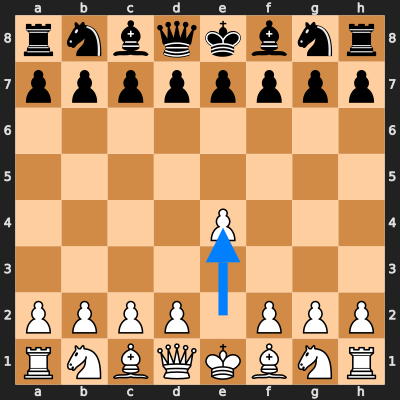

  Pantalla 2/36  MOV 1.n


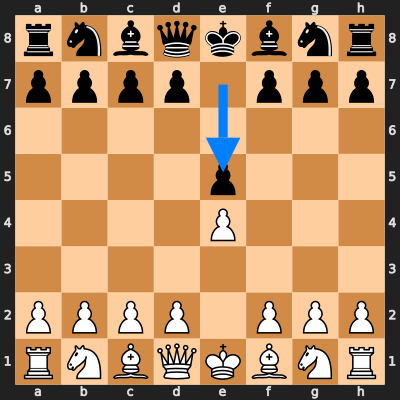

  Pantalla 3/36  MOV 2.b


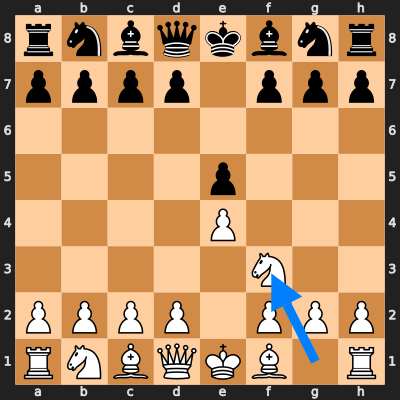

  Pantalla 4/36  MOV 2.n


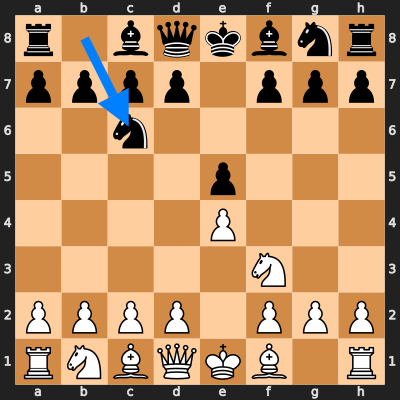

  Pantalla 5/36  MOV 3.b


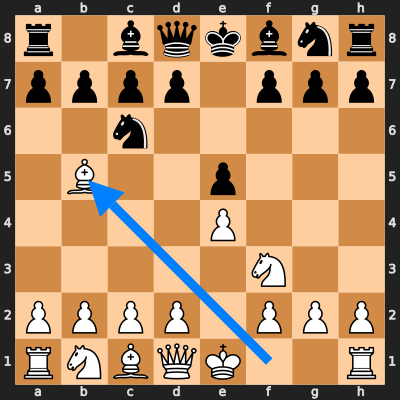

  Pantalla 6/36  MOV 3.n


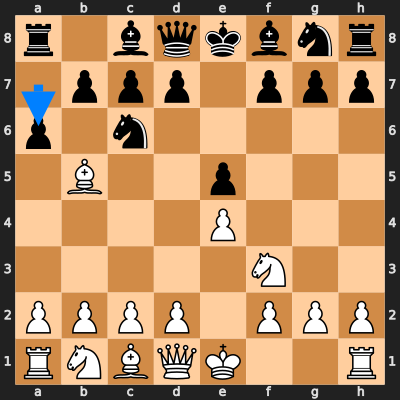

  Pantalla 7/36  MOV 4.b


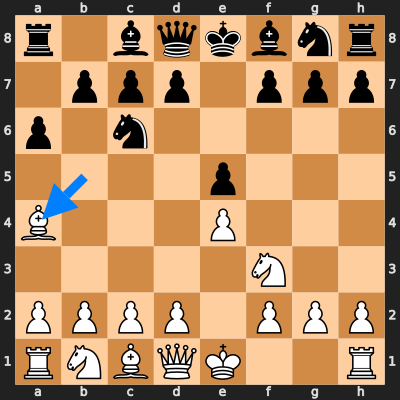

  Pantalla 8/36  MOV 4.n


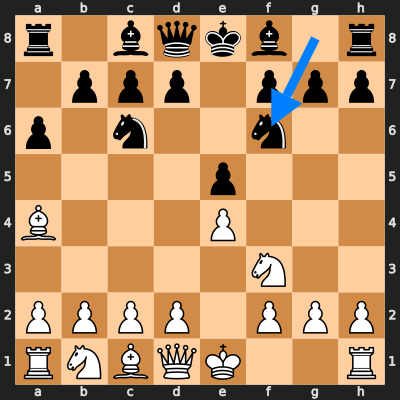

  Pantalla 9/36  MOV 5.b


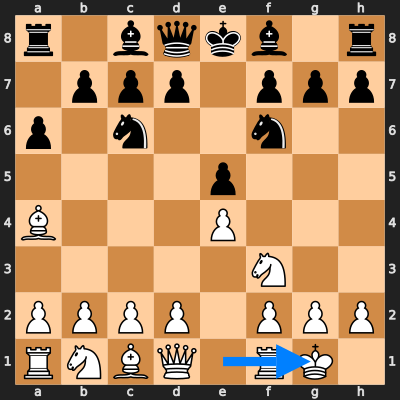

  Pantalla 10/36  MOV 5.n


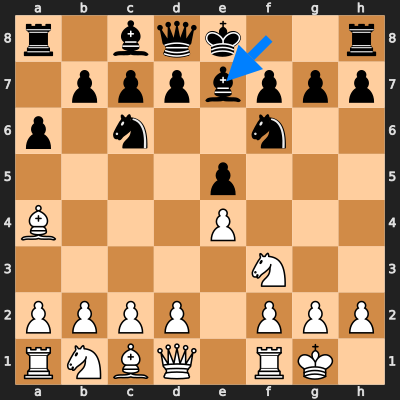

  Pantalla 11/36  MOV 6.b


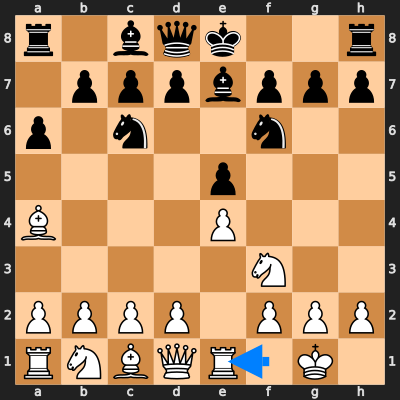

  Pantalla 12/36  MOV 6.n


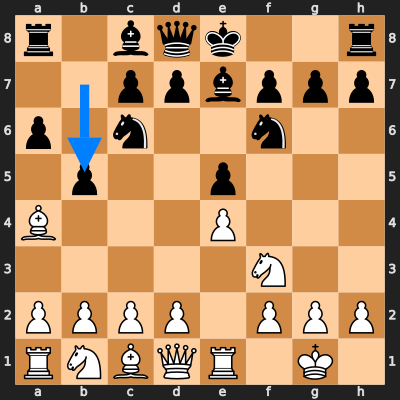

  Pantalla 13/36  MOV 7.b


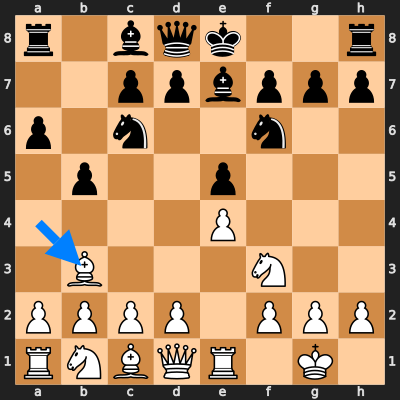

  Pantalla 14/36  MOV 7.n


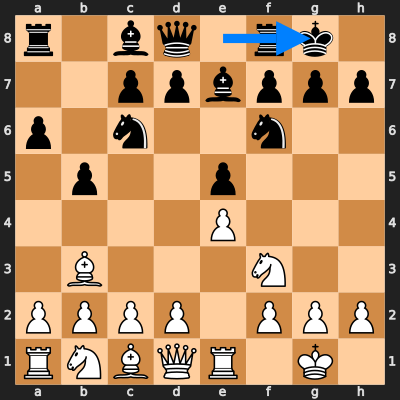

  Pantalla 15/36  MOV 8.b


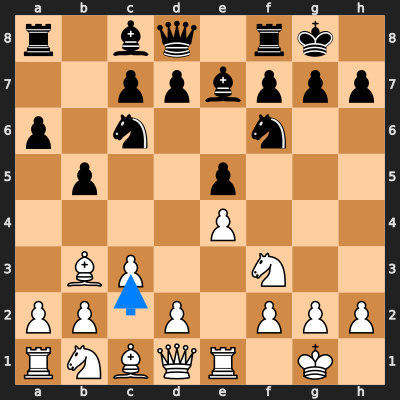

  Pantalla 16/36  MOV 8.n


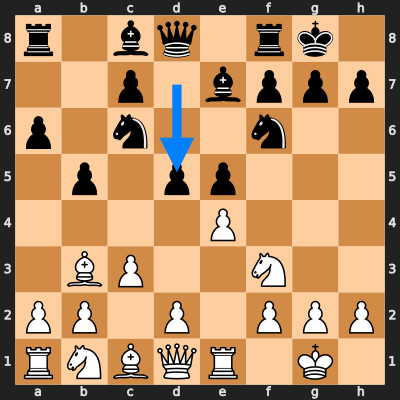

  Pantalla 17/36  MOV 9.b


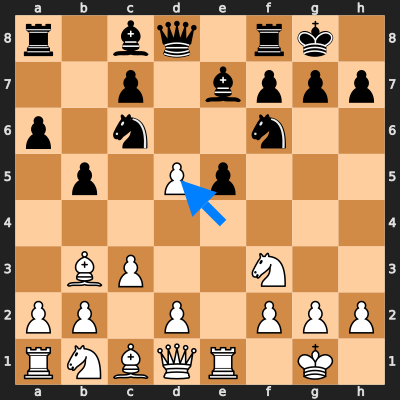

  Pantalla 18/36  MOV 9.n


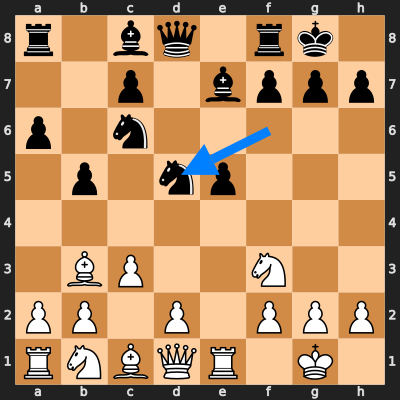

  Pantalla 19/36  MOV 10.b


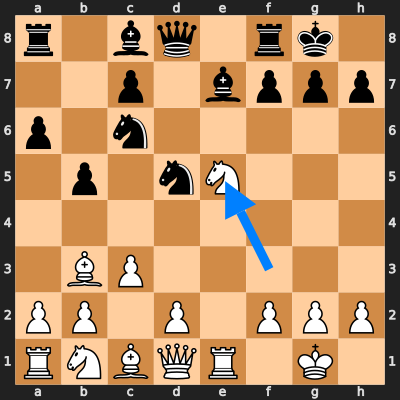

  Pantalla 20/36  MOV 10.n


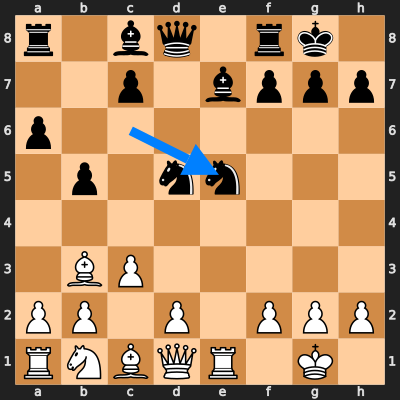

  Pantalla 21/36  MOV 11.b


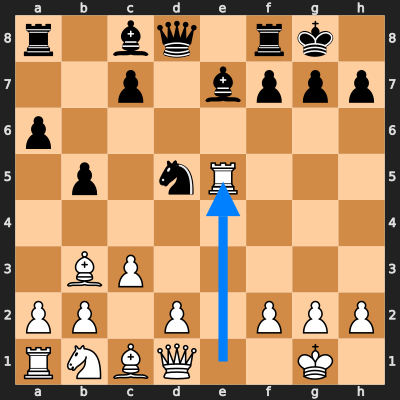

  Pantalla 22/36  MOV 11.n


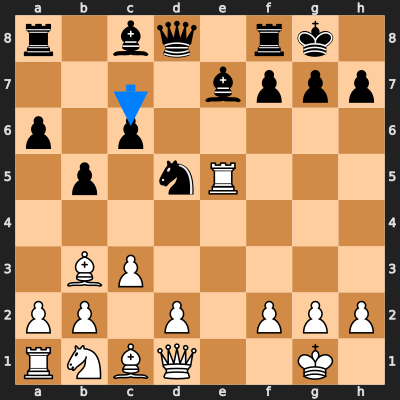

  Pantalla 23/36  MOV 12.b


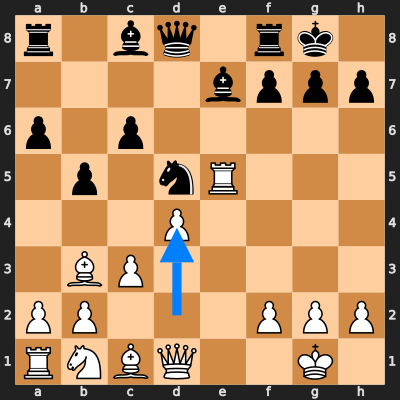

  Pantalla 24/36  MOV 12.n


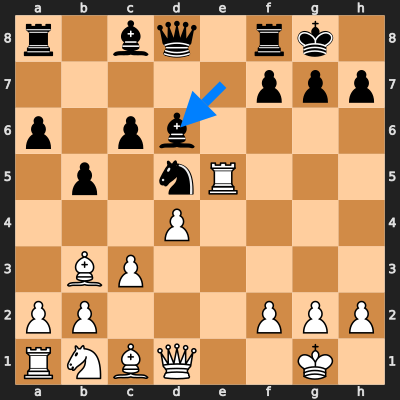

  Pantalla 25/36  MOV 13.b


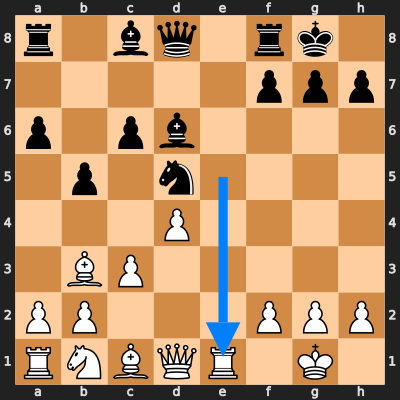

  Pantalla 26/36  MOV 13.n


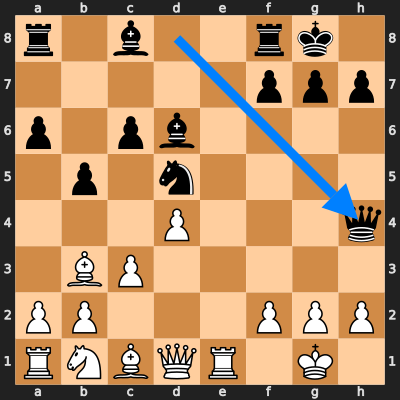

  Pantalla 27/36  MOV 14.b


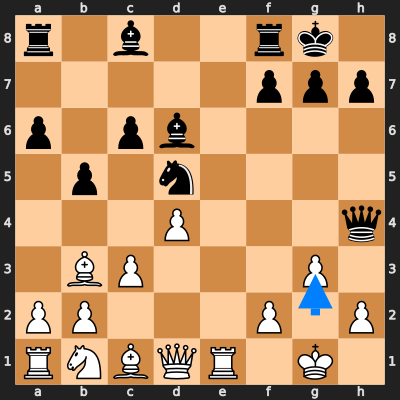

  Pantalla 28/36  MOV 14.n


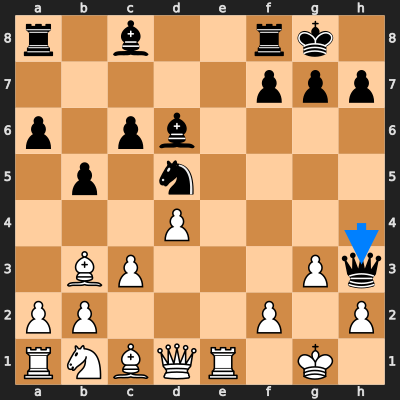

  Pantalla 29/36  MOV 15.b


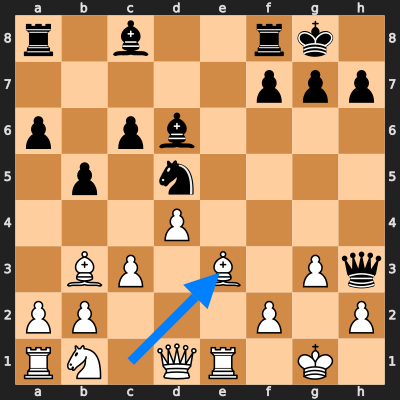

  Pantalla 30/36  MOV 15.n


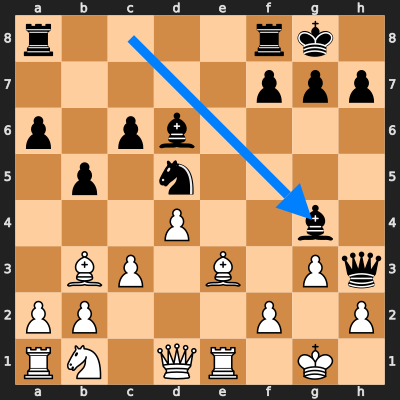

  Pantalla 31/36  MOV 16.b


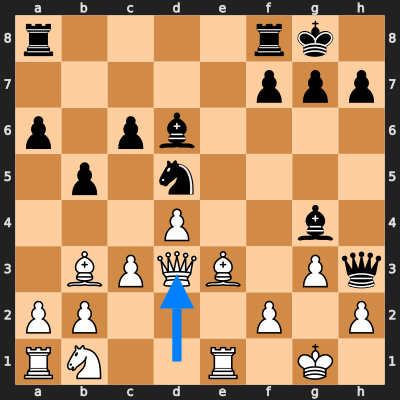

  Pantalla 32/36  MOV 16.n


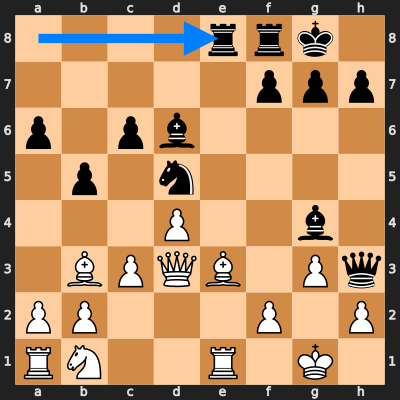

  Pantalla 33/36  MOV 17.b


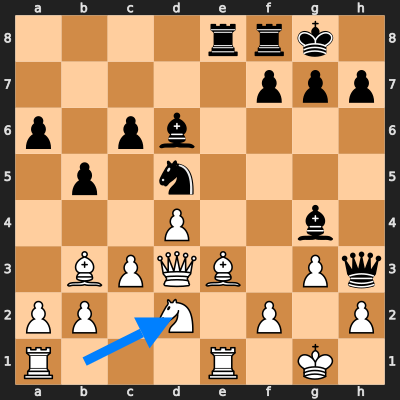

  Pantalla 34/36  MOV 17.n


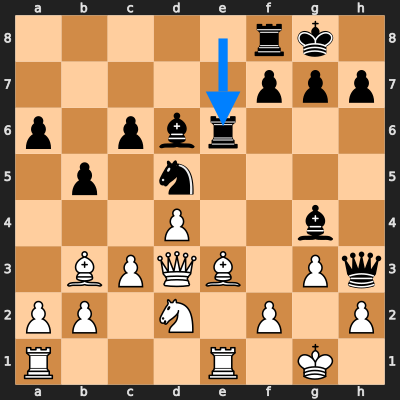

  Pantalla 35/36  MOV 18.b


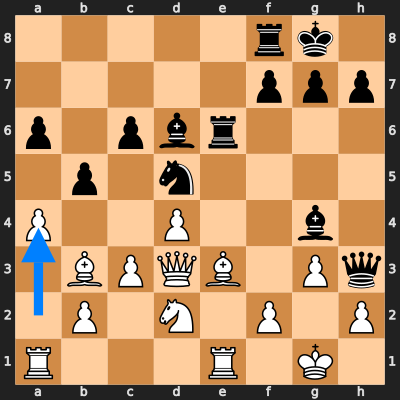

  Pantalla 36/36  MOV 18.n


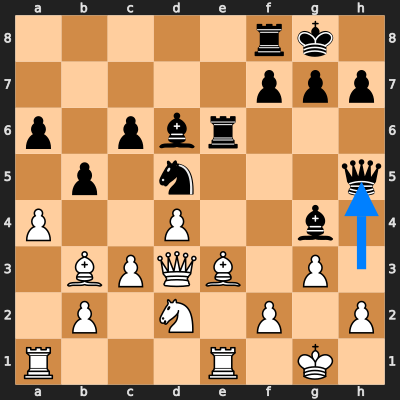

time: 937 ms (started: 2025-12-11 09:44:54 +01:00)


In [258]:
#C89 SPASSKY
C89_str = "1 e4 e5 2 Nf3 Nc6 3 Bb5 a6 4 Ba4 Nf6 5 O-O-O Be7 6 Re1 b5 7 Bb3 O-O 8 c3 d5 9 exd5 Nxd5 10 Nxe5 Nxe5 11 Rxe5 c6 12 d4 Bd6 13 Re1 Qh4 14 g3 Qh3 15 Be3 Bg4 16 Qd3 Rae8 17 Nd2 Re6 18 a4 Qh5"

#LISTA DE LISTAS C89 SPASSKY
C89 = [["e4", "e5", "Nf3", "Nc6", "Bb5", "a6", "Ba4", "Nf6", "O-O", "Be7", "Re1", "b5", "Bb3", "O-O", "c3", "d5", "exd5",
"Nxd5", "Nxe5", "Nxe5", "Rxe5", "c6", "d4", "Bd6", "Re1", "Qh4", "g3", "Qh3", "Be3", "Bg4", "Qd3", "Rae8", "Nd2", "Re6", "a4", "Qh5"]]

#18 MOVS=36 MAX PLIERS
show_group("C8", None, dfeconum, gmr,max_plies=40, manual_patterns=C89_str, draw_forbiddens=True, nopeningsinfomax=5)

In [259]:
pat = pgn_to_pattern(C89_str)
#print(pat)
#print(len(pat))

time: 0 ns (started: 2025-12-11 09:44:55 +01:00)


##### **HEATMAP PARTIDAS Y APERTURAS POPULARES!**

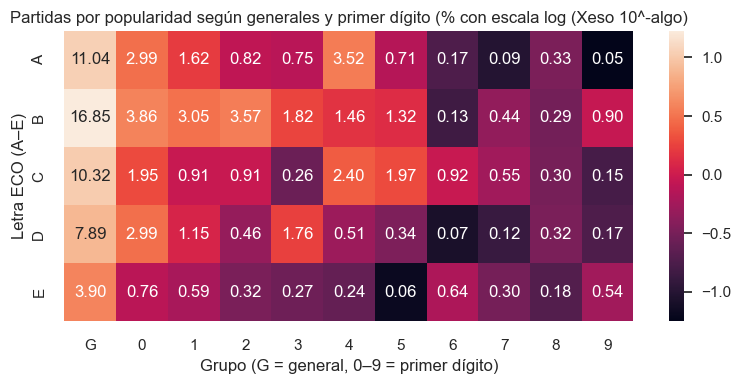

time: 375 ms (started: 2025-12-11 09:44:55 +01:00)


In [261]:
df2 = dfeconum[dfeconum["code"].str.len() == 2].copy()#ASEGURO 2
df2["letter"] = df2["code"].str[0]
df2["group"] = df2["code"].str[1]

cols = ["G"] + [str(i) for i in range(10)]
idx = list("ABCDE")

mat = (df2.pivot(index="letter", columns="group", values="n_games").reindex(index=idx, columns=cols).fillna(0))
# x pivote a tabla

total = mat.values.sum()#toto xa %
mat_pct = mat / total * 100  #%

#log
mat_log = np.log10(mat_pct + 0.01)  #+0.01 para evitar log(0)

plt.figure(figsize=(8, 4))

#colores log, % real
sns.heatmap(
    mat_log,
    annot=mat_pct,  #texto = % real
    fmt=".2f",
)

plt.xlabel("Grupo (G = general, 0–9 = primer dígito)")
plt.ylabel("Letra ECO (A–E)")
plt.title("Partidas por popularidad según generales y primer dígito (% con escala log (Xeso 10^-algo)")
plt.tight_layout()
plt.show()

###### **EJEMPLOS DE USO DE GENERADOR VISUAL CHESS 1**

Código B0: 10442 partidas (3.86%)      Total partidas: 270520
Top aperturas o líneas en este código o grupo:
  B01: Defensa Escandinava (2771 partidas)
(1.02 % de partidas totales)
  B00: Apertura de peón de rey sin 1... e5, 1... d5, 1... Cf6, 1... g6, 1... d6, 1... c6, 1... c5 (incluye Defensa Nimzowitsch, Defensa St. George, Defensa Owen, Defensa hipopótamo, Defensa Fred y otras) (1913 partidas)
(0.71 % de partidas totales)
  B07: Defensa Pirc (1768 partidas)
(0.65 % de partidas totales)
  B06: Defensa Robatsch (Moderna), incluye Monkey's Bum (1628 partidas)
(0.60 % de partidas totales)
  B02: Defensa Alekhine (820 partidas)
(0.30 % de partidas totales)

Patrones con uno o más movimientos o con '!=':

B0 #1 — línea: e4 d5
  Pantalla 1/2  MOV 1.b


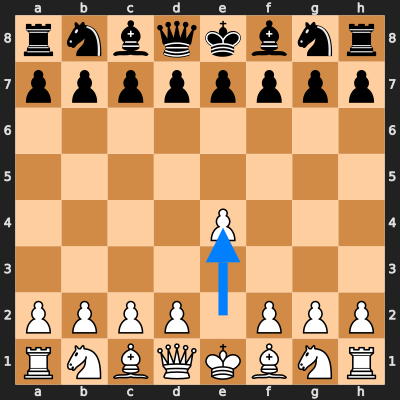

  Pantalla 2/2  MOV 1.n


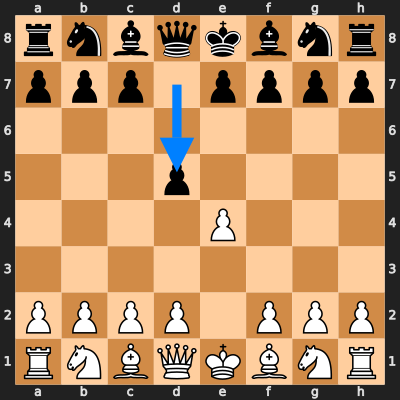


B0 #2 — línea: e4 Nf6
  Pantalla 1/2  MOV 1.b


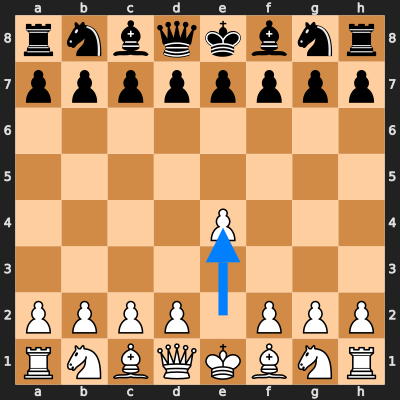

  Pantalla 2/2  MOV 1.n


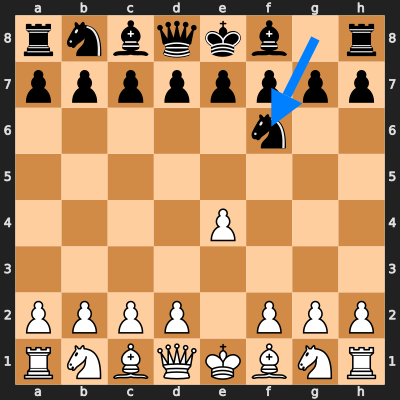


B0 #3 — línea: e4 d6
  Pantalla 1/2  MOV 1.b


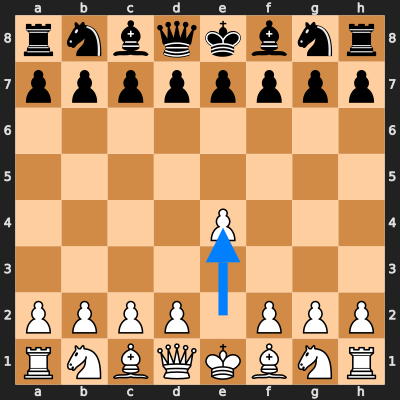

  Pantalla 2/2  MOV 1.n


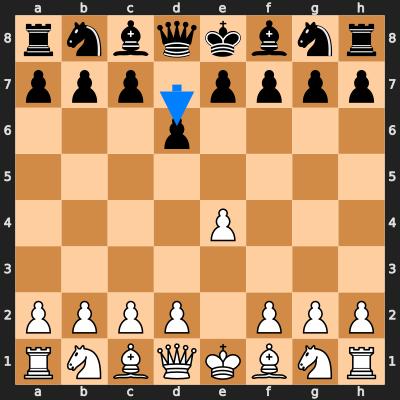


B0 #4 — línea: e4 g6
  Pantalla 1/2  MOV 1.b


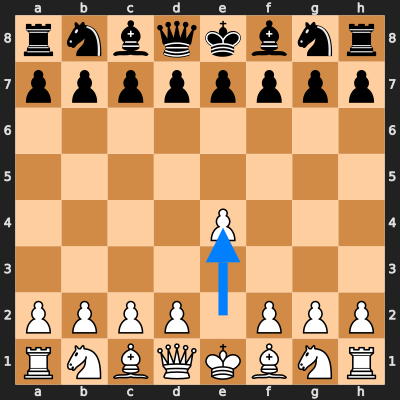

  Pantalla 2/2  MOV 1.n


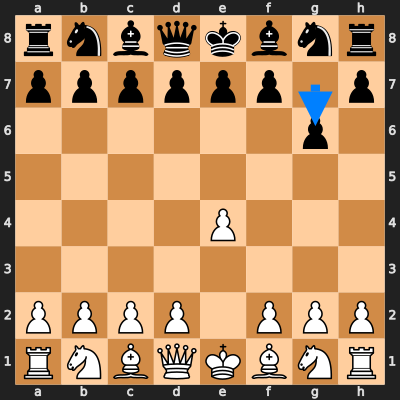

time: 203 ms (started: 2025-12-11 09:44:55 +01:00)


In [263]:
#p1=[["e4", "c5"],["e4", "c5", "!=", "Nf3", "Nc3"], ["e4", "c5", "!=", "Nf3", "Nc3"]]#o solo con un =!
#show_group("XX", None, dfeconum, gmr, manual_patterns=p1)
show_group("B0", eco_patterns, dfeconum, gmr)#max movs mas que la max apertura c89, 18

###### **EJEMPLOS DE USO DE GENERADOR VISUAL CHESS 2**

In [265]:
#EJEMPLOS DE USO E INSTRUCCIONES GENERALES DE SHOW_GROUP Y PGN_TO_PATTERN

# - eco_patterns: dict o array con patrones de aperturas por código ECO
# - eco_code: puede ser un ECO real ("D35"), un grupo ("AG","A0") o una etiqueta inventada ("D0","XX","MI_LINEA")
# - manual_patterns: JSON con clocks y basura (se limpia con pgn_to_pattern), lista de jugadas SAN ["e4","c5","Nf3",...]
#   o lista de listas de patrones [["e4"],["e4","c5"],["e4","c5","!=","Nf3"]]
# - draw_forbiddens: True dibuja flechas rojas para los '!=' en el último estado de cada patrón, False no dibuja rojas
# - max_plies: número máximo de jugadas a enseñar (por ejemplo 18, o no poner para mostrar todas)
# - nopeningsinfomax: máximo de aperturas/variantes a mostrar en el resumen de describe_openings_for_code (0 o menos = no mostrar)
# - dfeconum: DataFrame con número de partidas por código ("code","n_games")


#show_group("ECO/XX", eco_patterns/None, dfeconum, gmr, max_plies=18/(no poner=todas),
#manual_patterns=pgn_to_pattern(PGN/basura/clocks)/lista/opc,
#draw_forbiddens=True/False/opc,
#nopeningsinfomax=5/(0=no mostrar aperturas))

#LISTA DE PATRONES
#show_group("C2/D35/XX", eco_patterns, dfeconum, gmr)
#show_group("C2/D35/XX", eco_patterns, dfeconum, gmr, max_plies=18)
#show_group("C2/D35/XX", eco_patterns, dfeconum, gmr, max_plies=18, draw_forbiddens=True, nopeningsinfomax=3)


#PATRONES MANUALES COMO LISTA DE LISTAS
patrones_c2 = [
    ["e4"],  # un movimiento simple
    ["e4", "c5"],  # dos jugadas permitidas
    ["e4", "c5", "!=", "Nf3", "!=", "Nc3"],  # flechas rojas para recalcar prohibidos
    ["e4", "c5", "!=", "Nf3", "h3", "Nc3"]  # o solo con un '!=' y el resto prohibidos
]
#show_group("C2", None, dfeconum, gmr, manual_patterns=patrones_c2)
#show_group("C2", None, dfeconum, gmr, manual_patterns=patrones_c2, draw_forbiddens=True, nopeningsinfomax=2)


#TEXTO PGN NORMAL O DE CHESS.COM COMO STRING DIRECTO
mismovs_pgn = """
[Event "Live Chess"]
[Site "Chess.com"]
[Date "2025.09.12"]

1.d4 d5 2.c4Nf6 3.Nc3 e6 4.Bg5 Be7 5.Nf3 O-O
"""
#show_group("D35", None, dfeconum, gmr, manual_patterns=mismovs_pgn, nopeningsinfomax=5)
#patron_desde_pgn = pgn_to_pattern(mismovs_pgn)
#show_group("D35", None, dfeconum, gmr, manual_patterns=patron_desde_pgn, nopeningsinfomax=3)


#TEXTO PGN SIN CABECERAS, ECO_CODE LIBRE
x = '''
1. d4 Nc6 2. e3 d5 3. Bd3 Nf6 4. Nf3 e6 5. c3 Bd6 6. Nbd2 O-O 7. O-O h6 8. Re1
a6 9. e4 dxe4 10. Nxe4 b5 11. Nxd6 Qxd6 12. Ne5 Bb7 13. Qf3 g6 14. Qxf6 b4 15.
Bxh6 1-0
'''
#show_group("D0", None, dfeconum, gmr, manual_patterns=x, nopeningsinfomax=0)
#show_group("MI_LINEA", None, dfeconum, gmr, manual_patterns=x, nopeningsinfomax=5)

#show_group("XX", None, dfeconum, gmr, manual_patterns=x, draw_forbiddens=True, nopeningsinfomax=2)


#TEXTO COMPLETO DE CHESS.COM/PUB CON "pgn": Y CLOCKS MEZCLADOS
# ... "pgn": "... 1. d4 {[%clk 0:00:58.3]} 1... g6 {[%clk ...]} ... 47... Qe1# {[%clk ...]} 0-1" ...
#patron_json = pgn_to_pattern(mismovs_json)
#show_group("B06", None, dfeconum, gmr, manual_patterns=patron_json, nopeningsinfomax=4)

time: 0 ns (started: 2025-12-11 09:44:56 +01:00)


##### **HEATMAP WINS, LOSES Y EMPATES Y APERTURAS OPTIMAS XA GANAR SEGÚN TOPS!**

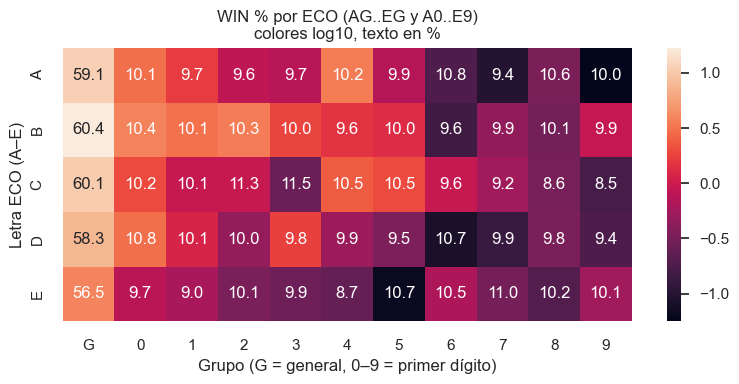

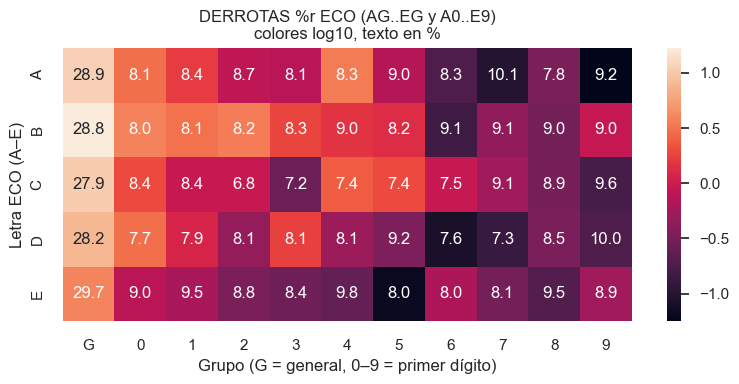

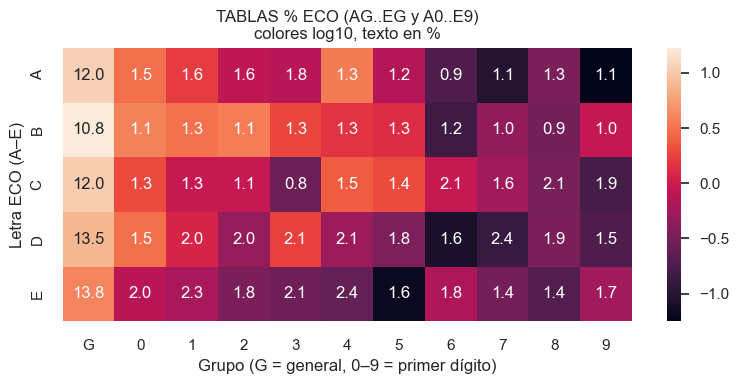

time: 1.17 s (started: 2025-12-11 09:44:56 +01:00)


In [267]:
df2 = dfres[dfres["code"].str.len() == 2].copy()
df2["letter"] = df2["code"].str[0]  #A..E
df2["group"] = df2["code"].str[1]   #G,0..9
df2["total"] = df2["win"] + df2["loss"] + df2["draw"]

#INICIALIZO % A 0.0
df2["win_pct"] = 0.0
df2["loss_pct"] = 0.0
df2["draw_pct"] = 0.0
mask_total = df2["total"] > 0


#% WIN
df2.loc[mask_total, "win_pct"] = (df2.loc[mask_total, "win"] / df2.loc[mask_total, "total"] * 100) #SOLO SI MASKTOTAL TRUE

#% LOSS
df2.loc[mask_total, "loss_pct"] = (df2.loc[mask_total, "loss"] / df2.loc[mask_total, "total"] * 100)

#% DRAW
df2.loc[mask_total, "draw_pct"] = (df2.loc[mask_total, "draw"] / df2.loc[mask_total, "total"] * 100)

for col_pct in ["win_pct", "loss_pct", "draw_pct"]:
    for letra in idx:  # A..E
        mask_g = (df2["letter"] == letra) & (df2["group"] == "G")
        if not df2.loc[mask_g, col_pct].empty:
            g_val = df2.loc[mask_g, col_pct].iloc[0]  # % de AG, BG, etc.
            factor = g_val / 100.0   #lo paso a [0,1]
            mask_digitos = (df2["letter"] == letra) & (df2["group"] != "G")
            df2.loc[mask_digitos, col_pct] = df2.loc[mask_digitos, col_pct] * factor
            

#ORDEN FILAS Y COLUMNAS (IGUAL QUE EL HEATMAP ANTERIOR)
cols = ["G"] + [str(i) for i in range(10)]  #G,0..9
idx = list("ABCDE") #A..E


def plot_wld_heatmap(df2, col_pct, titulo): #XA NO REPETIR
    mat = (df2.pivot(index="letter", columns="group", values=col_pct)
           .reindex(index=idx, columns=cols).fillna(0)) 

    if col_pct == "win_pct": #SOLO XA WIN QUE SE ME BUGEA NPI DE PQ
        digit_cols = [c for c in mat.columns if c != "G"]  # 0..9
        row_sum = mat[digit_cols].sum(axis=1)
        mask_rows = row_sum > 0
        mat.loc[mask_rows, digit_cols] = (
            mat.loc[mask_rows, digit_cols]
            .div(row_sum[mask_rows], axis=0) * 100
        )
    
    plt.figure(figsize=(8, 4))
    sns.heatmap(
        mat_log, #COLORES = ESCALA LOG
        annot=mat.round(1), #TEXTO = % REAL (ahora si redondeo a 1 DECIMAL)
        fmt=".1f",
    )
    plt.xlabel("Grupo (G = general, 0–9 = primer dígito)")
    plt.ylabel("Letra ECO (A–E)")
    plt.title(titulo)
    plt.tight_layout()
    plt.show()

#HEATMAPS
plot_wld_heatmap(df2, "win_pct","WIN % por ECO (AG..EG y A0..E9)\ncolores log10, texto en %")
plot_wld_heatmap(df2, "loss_pct", "DERROTAS %r ECO (AG..EG y A0..E9)\ncolores log10, texto en %")
plot_wld_heatmap(df2, "draw_pct", "TABLAS % ECO (AG..EG y A0..E9)\ncolores log10, texto en %")

###### **EJEMPLOS DE USO DE GENERADOR VISUAL CHESS 1**

Código C6: 2476 partidas (0.92%)      Total partidas: 270520
Top aperturas o líneas en este código o grupo:
  C65: Española, Defensa Berlín incluyendo Celada Mortimer (560 partidas)
(0.21 % de partidas totales)
  C67: Española, Defensa Berlín, variante abierta (454 partidas)
(0.17 % de partidas totales)
  C60: Apertura española (Ruy López) (389 partidas)
(0.14 % de partidas totales)
  C68: Española, variante del cambio (234 partidas)
(0.09 % de partidas totales)
  C63: Española, Defensa Schliemann (228 partidas)
(0.08 % de partidas totales)

Patrones con uno o más movimientos o con '!=':

C6 #1 — línea: e4 e5 Nf3 Nc6 Bb5
  Pantalla 1/5  MOV 1.b


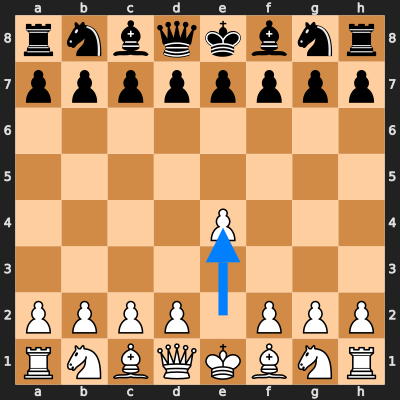

  Pantalla 2/5  MOV 1.n


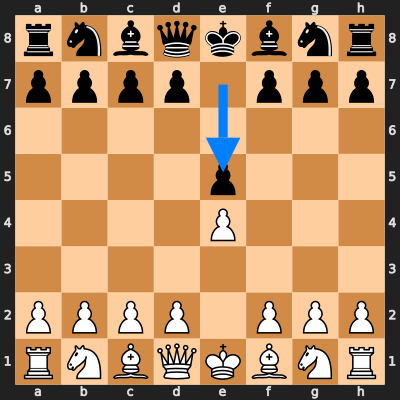

  Pantalla 3/5  MOV 2.b


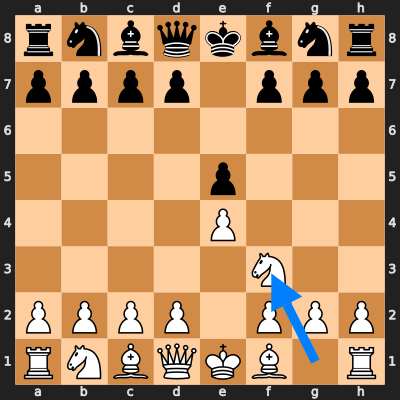

  Pantalla 4/5  MOV 2.n


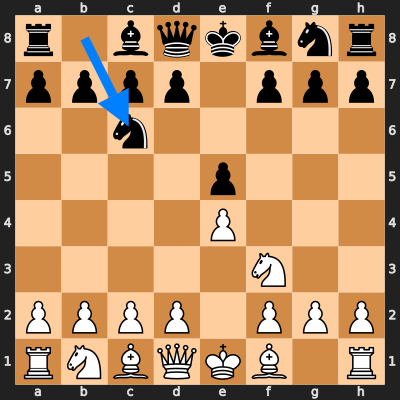

  Pantalla 5/5  MOV 3.b


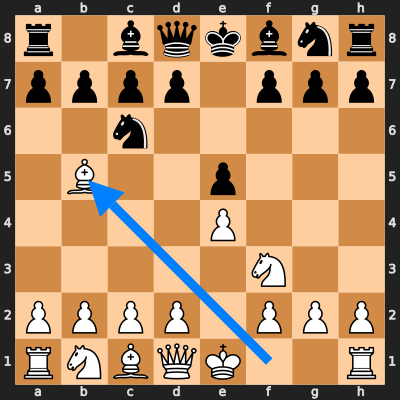

time: 172 ms (started: 2025-12-11 09:44:57 +01:00)


In [269]:
#p1=[["e4", "c5"],["e4", "c5", "!=", "Nf3", "!=", "Nc3"], ["e4", "c5", "!=", "Nf3", "Nc3"]]#o solo con un =!
#show_group("XX", None, dfeconum, gmr, manual_patterns=p1)
show_group("C6", eco_patterns, dfeconum, gmr)#max movs mas que la max apertura c89, 18

###### **EJEMPLOS DE USO DE GENERADOR VISUAL CHESS 2**

In [271]:
#EJEMPLOS DE USO E INSTRUCCIONES GENERALES DE SHOW_GROUP Y PGN_TO_PATTERN

# - eco_patterns: dict o array con patrones de aperturas por código ECO
# - eco_code: puede ser un ECO real ("D35"), un grupo ("AG","A0") o una etiqueta inventada ("D0","XX","MI_LINEA")
# - manual_patterns: JSON con clocks y basura (se limpia con pgn_to_pattern), lista de jugadas SAN ["e4","c5","Nf3",...]
#   o lista de listas de patrones [["e4"],["e4","c5"],["e4","c5","!=","Nf3"]]
# - draw_forbiddens: True dibuja flechas rojas para los '!=' en el último estado de cada patrón, False no dibuja rojas
# - max_plies: número máximo de jugadas a enseñar (por ejemplo 18, o no poner para mostrar todas)
# - nopeningsinfomax: máximo de aperturas/variantes a mostrar en el resumen de describe_openings_for_code (0 o menos = no mostrar)
# - dfeconum: DataFrame con número de partidas por código ("code","n_games")


#show_group("ECO/XX", eco_patterns/None, dfeconum, gmr, max_plies=18/(no poner=todas),
#manual_patterns=pgn_to_pattern(PGN/basura/clocks)/lista/opc,
#draw_forbiddens=True/False/opc,
#nopeningsinfomax=5/(0=no mostrar aperturas))

#LISTA DE PATRONES
#show_group("C2/D35/XX", eco_patterns, dfeconum, gmr)
#show_group("C2/D35/XX", eco_patterns, dfeconum, gmr, max_plies=18)
#show_group("C2/D35/XX", eco_patterns, dfeconum, gmr, max_plies=18, draw_forbiddens=True, nopeningsinfomax=3)


#PATRONES MANUALES COMO LISTA DE LISTAS
patrones_c2 = [
    ["e4"],  # un movimiento simple
    ["e4", "c5"],  # dos jugadas permitidas
    ["e4", "c5", "!=", "Nf3", "!=", "Nc3"],  # flechas rojas para recalcar prohibidos
    ["e4", "c5", "!=", "Nf3", "h3", "Nc3"]  # o solo con un '!=' y el resto prohibidos
]
#show_group("C2", None, dfeconum, gmr, manual_patterns=patrones_c2)
#show_group("C2", None, dfeconum, gmr, manual_patterns=patrones_c2, draw_forbiddens=True, nopeningsinfomax=2)


#TEXTO PGN NORMAL O DE CHESS.COM COMO STRING DIRECTO
mismovs_pgn = """
[Event "Live Chess"]
[Site "Chess.com"]
[Date "2025.09.12"]

1.d4 d5 2.c4Nf6 3.Nc3 e6 4.Bg5 Be7 5.Nf3 O-O
"""
#show_group("D35", None, dfeconum, gmr, manual_patterns=mismovs_pgn, nopeningsinfomax=5)
#patron_desde_pgn = pgn_to_pattern(mismovs_pgn)
#show_group("D35", None, dfeconum, gmr, manual_patterns=patron_desde_pgn, nopeningsinfomax=3)


#TEXTO PGN SIN CABECERAS, ECO_CODE LIBRE
x = '''
1. d4 Nc6 2. e3 d5 3. Bd3 Nf6 4. Nf3 e6 5. c3 Bd6 6. Nbd2 O-O 7. O-O h6 8. Re1
a6 9. e4 dxe4 10. Nxe4 b5 11. Nxd6 Qxd6 12. Ne5 Bb7 13. Qf3 g6 14. Qxf6 b4 15.
Bxh6 1-0
'''
#show_group("D0", None, dfeconum, gmr, manual_patterns=x, nopeningsinfomax=0)
#show_group("MI_LINEA", None, dfeconum, gmr, manual_patterns=x, nopeningsinfomax=5)

#show_group("XX", None, dfeconum, gmr, manual_patterns=x, draw_forbiddens=True, nopeningsinfomax=2)


#TEXTO COMPLETO DE CHESS.COM/PUB CON "pgn": Y CLOCKS MEZCLADOS
# ... "pgn": "... 1. d4 {[%clk 0:00:58.3]} 1... g6 {[%clk ...]} ... 47... Qe1# {[%clk ...]} 0-1" ...
#patron_json = pgn_to_pattern(mismovs_json)
#show_group("B06", None, dfeconum, gmr, manual_patterns=patron_json, nopeningsinfomax=4)

time: 0 ns (started: 2025-12-11 09:44:57 +01:00)


##### **ENSEÑAR TOP APERTURAS SEGÚN POPULARIDAAD, WINS, LOSES Y EMPATES SEGÚN APERTURA CON DOS DÍGITOSS! /+LARGA Y CUALQUIERA**

###### **BACKEND**

In [274]:
def op_tbl(gmr: pd.DataFrame) -> pd.DataFrame:
    #n_games (total partidas)
    #gmr["result_int"] (1 = win, 0 = draw, -1 = loss).

    if "eco_code" not in gmr.columns:
        raise ValueError("gmr debe tener columna 'eco_code'.")
    if "result_int" not in gmr.columns:
        raise ValueError("gmr debe tener columna 'result_int' (1/0/-1).")

    df = gmr[["eco_code", "result_int"]].dropna().copy()
    df["eco_code"] = df["eco_code"].astype(str)

    #PRIMER DÍGITO: A0..E9 (A00..A09 -> A0, etc.)
    df["eco_fd"] = df["eco_code"].str[:2]

    #letra A–E + dígito 0–9
    mask = (
        (df["eco_fd"].str.len() == 2)
        & (df["eco_fd"].str[0].isin(list("ABCDE")))
        & (df["eco_fd"].str[1].str.isdigit())
    )
    df = df[mask].copy()

    if df.empty:
        return pd.DataFrame(columns=["wins", "draws", "losses", "n_games"])

    # INDICADORES BOOLEANOS 0/1
    df["is_win"]   = (df["result_int"] == 1).astype(int)
    df["is_draw"]  = (df["result_int"] == 0).astype(int)
    df["is_loss"]  = (df["result_int"] == -1).astype(int)

    grp = (df.groupby("eco_fd")[["is_win", "is_draw", "is_loss"]].sum()
          .rename(columns={
              "is_win": "wins",
              "is_draw": "draws",
              "is_loss": "losses"
          })
    )

    grp["n_games"] = grp["wins"] + grp["draws"] + grp["losses"] #todos los res de uin opening=numero de partidas
    grp = grp.sort_index()  #orden

    return grp


def op_top_d(gmr: pd.DataFrame, n: int = 5) -> list[str]:
    tbl = op_tbl(gmr)
    if tbl.empty:
        return []
    tbl_sorted = tbl.sort_values("draws", ascending=False)
    return tbl_sorted.index[:n].tolist()


def op_top_l(gmr: pd.DataFrame, n: int = 5) -> list[str]:
    tbl = op_tbl(gmr)
    if tbl.empty:
        return []
    tbl_sorted = tbl.sort_values("losses", ascending=False)
    return tbl_sorted.index[:n].tolist()


def op_top_w(gmr: pd.DataFrame, n: int = 5) -> list[str]:
    tbl = op_tbl(gmr)
    if tbl.empty:
        return []
    tbl_sorted = tbl.sort_values("wins", ascending=False)
    return tbl_sorted.index[:n].tolist()


def op_top_pop(gmr: pd.DataFrame, n: int = 5) -> list[str]:
    tbl = op_tbl(gmr)
    if tbl.empty:
        return []
    tbl_sorted = tbl.sort_values("n_games", ascending=False)
    return tbl_sorted.index[:n].tolist()

time: 0 ns (started: 2025-12-11 09:44:58 +01:00)


In [275]:
# TOP X(3) (WINS/LOSES/DRAWS/POPULARES)
codes_pop    = op_top_pop(gmr, n=3)
codes_wins   = op_top_w(gmr, n=3)
codes_losses = op_top_l(gmr, n=3)
codes_draws  = op_top_d(gmr, n=3)

time: 1.12 s (started: 2025-12-11 09:44:58 +01:00)


In [276]:
def imprimirop(n=5, pop=1, win=0, lose=0, draw=0, max_plies=20, size=400, nopeningsinfomax=5, draw_forbiddens=True):
    #codigos A0..E9.
    #n: nº de códigos por categoría (pop, win, lose, draw)
    #pop/win/lose/draw: 1 = mostrar, 0 = no mostrar
    
    #0 o 1
    flags = [("pop", pop), ("win", win), ("lose", lose), ("draw", draw)]
    for name, val in flags:
        if val not in (0, 1):
            raise ValueError(f"{name} debe ser 0 o 1 (has puesto {val}).")

    if n is None or n <= 0:
        print("n <= 0, no se muestra nada.")
        return

    #xa todo 0
    if all(val == 0 for _, val in flags):
        print("Todos los flags están a 0, no hay nada que mostrar.")
        return

    #POPULARES
    if pop == 1:
        codes_pop = op_top_pop(gmr, n=n)
        if codes_pop:
            print(f"\nTOP POPULARES n={n}:")
            for code in codes_pop:
                print(" ", code)
            for code in codes_pop:
                show_group(code, eco_patterns, dfeconum, gmr, max_plies=max_plies, size=size, manual_patterns=None, draw_forbiddens=draw_forbiddens, nopeningsinfomax=nopeningsinfomax)

    #MÁS WINS
    if win == 1:
        codes_w = op_top_w(gmr, n=n)
        if codes_w:
            print(f"\nTOP WINS n={n}:")
            for code in codes_w:
                print(" ", code)
            for code in codes_w:
                show_group(code, eco_patterns, dfeconum, gmr, max_plies=max_plies, size=size, manual_patterns=None, draw_forbiddens=draw_forbiddens, nopeningsinfomax=nopeningsinfomax)

    #MÁS LOSSES
    if lose == 1:
        codes_l = op_top_l(gmr, n=n)
        if codes_l:
            print(f"\nTOP LOSSES n={n}:")
            for code in codes_l:
                print(" ", code)
            for code in codes_l:
                show_group(code, eco_patterns, dfeconum, gmr, max_plies=max_plies, size=size, manual_patterns=None, draw_forbiddens=draw_forbiddens, nopeningsinfomax=nopeningsinfomax)

    #MÁS DRAWS
    if draw == 1:
        codes_d = op_top_d(gmr, n=n)
        if codes_d:
            print(f"\nTOP DRAWS n={n}:")
            for code in codes_d:
                print(" ", code)
            for code in codes_d:
                show_group(code, eco_patterns, dfeconum, gmr, max_plies=max_plies, size=size, manual_patterns=None, draw_forbiddens=draw_forbiddens, nopeningsinfomax=nopeningsinfomax)

time: 0 ns (started: 2025-12-11 09:44:59 +01:00)


###### **IMPRIMIR**


TOP POPULARES n=5:
  B0
  B2
  A4
  B1
  D0
Código B0: 10442 partidas (3.86%)      Total partidas: 270520
Top aperturas o líneas en este código o grupo:
  B01: Defensa Escandinava (2771 partidas)
(1.02 % de partidas totales)
  B00: Apertura de peón de rey sin 1... e5, 1... d5, 1... Cf6, 1... g6, 1... d6, 1... c6, 1... c5 (incluye Defensa Nimzowitsch, Defensa St. George, Defensa Owen, Defensa hipopótamo, Defensa Fred y otras) (1913 partidas)
(0.71 % de partidas totales)
  B07: Defensa Pirc (1768 partidas)
(0.65 % de partidas totales)
  B06: Defensa Robatsch (Moderna), incluye Monkey's Bum (1628 partidas)
(0.60 % de partidas totales)
  B02: Defensa Alekhine (820 partidas)
(0.30 % de partidas totales)

Patrones con uno o más movimientos o con '!=':

B0 #1 — línea: e4 d5
  Pantalla 1/2  MOV 1.b


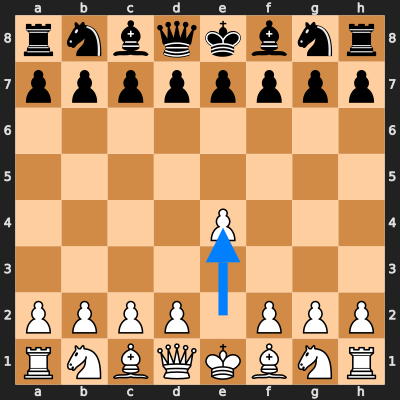

  Pantalla 2/2  MOV 1.n


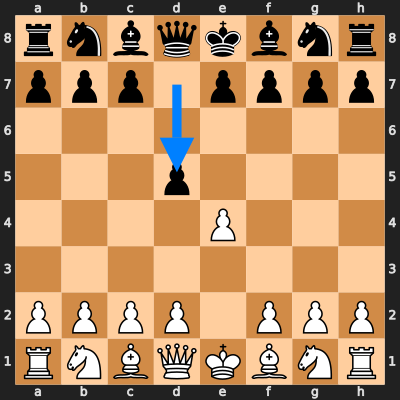


B0 #2 — línea: e4 Nf6
  Pantalla 1/2  MOV 1.b


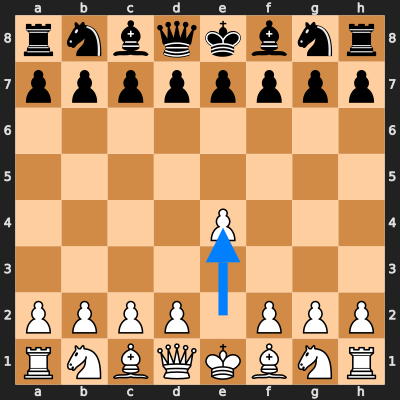

  Pantalla 2/2  MOV 1.n


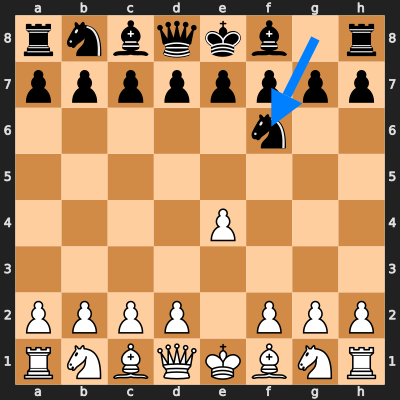


B0 #3 — línea: e4 d6
  Pantalla 1/2  MOV 1.b


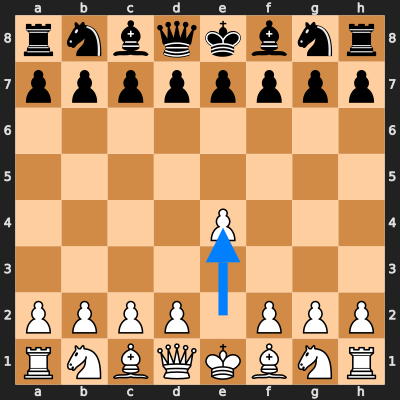

  Pantalla 2/2  MOV 1.n


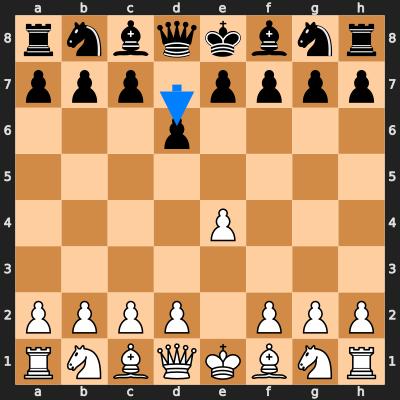


B0 #4 — línea: e4 g6
  Pantalla 1/2  MOV 1.b


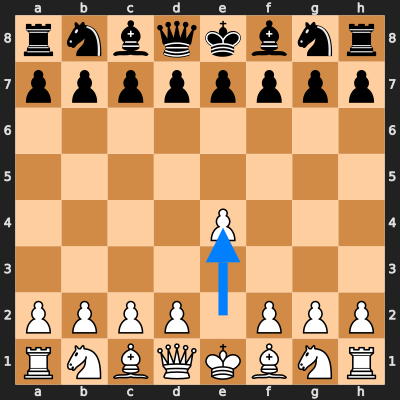

  Pantalla 2/2  MOV 1.n


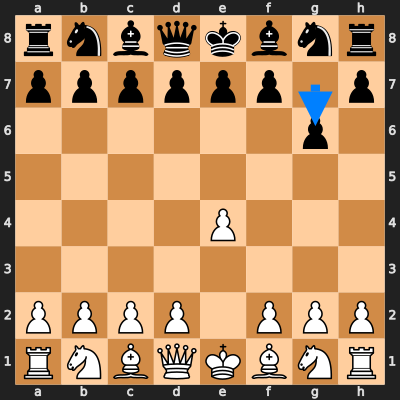

Código B2: 9669 partidas (3.57%)      Total partidas: 270520
Top aperturas o líneas en este código o grupo:
  B22: Defensa siciliana, variante Alapin (2.c3) (3000 partidas)
(1.11 % de partidas totales)
  B23: Siciliana, cerrada (2191 partidas)
(0.81 % de partidas totales)
  B20: Defensa siciliana (1509 partidas)
(0.56 % de partidas totales)
  B21: Siciliana, ataque Grand Prix y Gambito Smith-Morra, incluyendo la Trampa Siberiana (1066 partidas)
(0.39 % de partidas totales)
  B27: Defensa Siciliana (695 partidas)
(0.26 % de partidas totales)

Patrones con uno o más movimientos o con '!=':

B2 #1 — línea: e4 c5   (prohibidos: Nf3)
  Pantalla 1/3  MOV 1.b


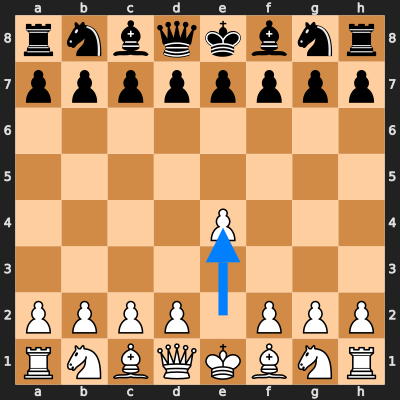

  Pantalla 2/3  MOV 1.n


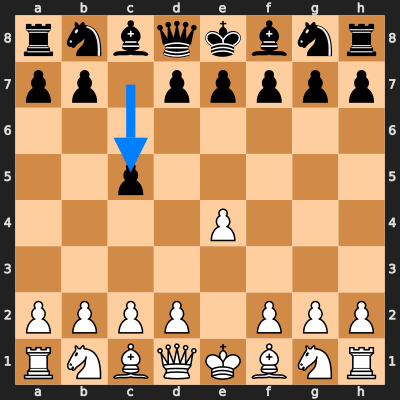

  Pantalla 3/3  MOV 1.n


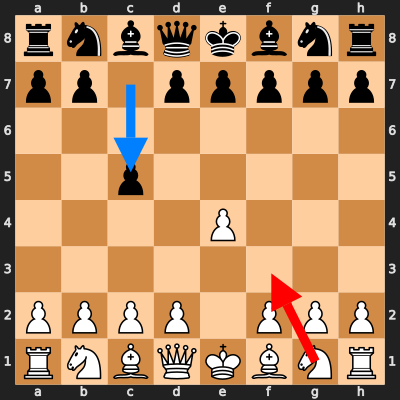

Código A4: 9520 partidas (3.52%)      Total partidas: 270520
Top aperturas o líneas en este código o grupo:
  A45: Apertura de peón de dama (3355 partidas)
(1.24 % de partidas totales)
  A40: Apertura de peón de dama (incluyendo Defensa inglesa, Gambito Englund, Defensa del caballo de dama, Defensa polaca y Defensa Keres) (1830 partidas)
(0.68 % de partidas totales)
  A46: Apertura de peón de dama (1479 partidas)
(0.55 % de partidas totales)
  A48: India de rey, Defensa india de este (1112 partidas)
(0.41 % de partidas totales)
  A41: Apertura de peón de dama, Defensa Wade (628 partidas)
(0.23 % de partidas totales)

Patrones con uno o más movimientos o con '!=':

A4 #1 — línea: d4 e6
  Pantalla 1/2  MOV 1.b


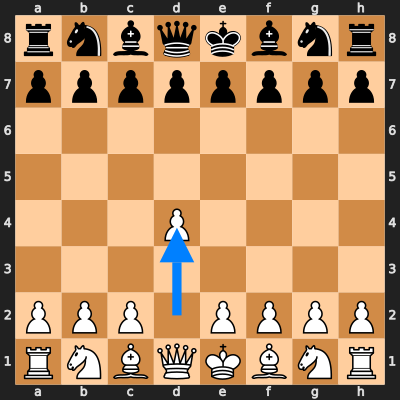

  Pantalla 2/2  MOV 1.n


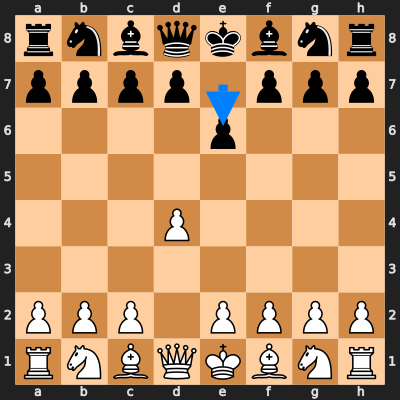


A4 #2 — línea: d4 d6
  Pantalla 1/2  MOV 1.b


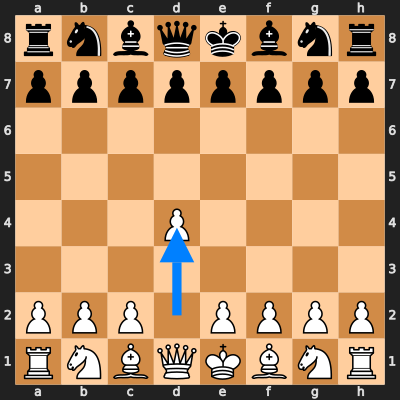

  Pantalla 2/2  MOV 1.n


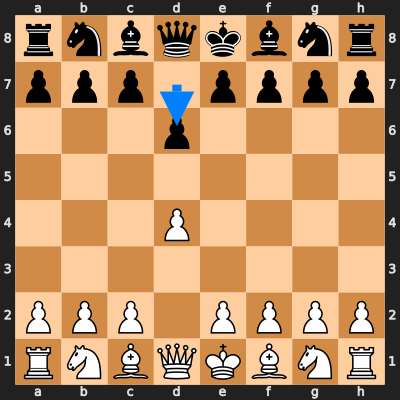


A4 #3 — línea: d4 g6
  Pantalla 1/2  MOV 1.b


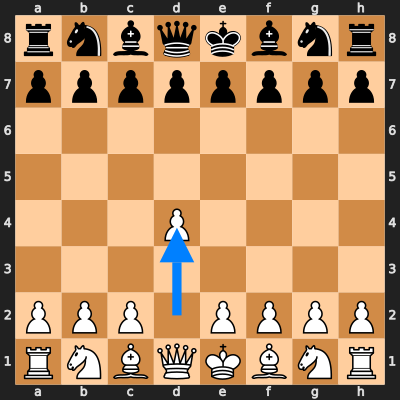

  Pantalla 2/2  MOV 1.n


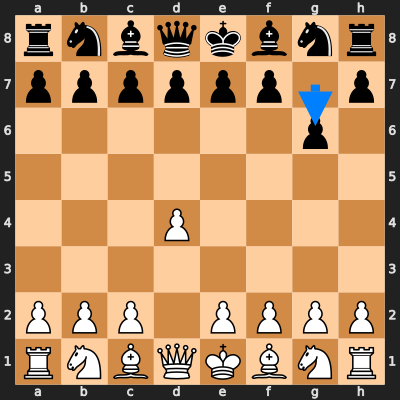


A4 #4 — línea: d4 c6
  Pantalla 1/2  MOV 1.b


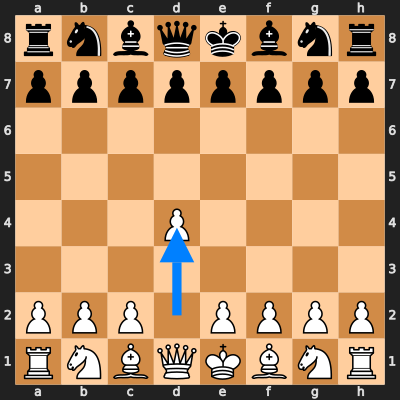

  Pantalla 2/2  MOV 1.n


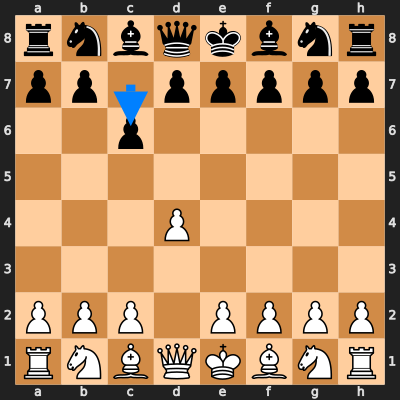


A4 #5 — línea: d4 Nc6
  Pantalla 1/2  MOV 1.b


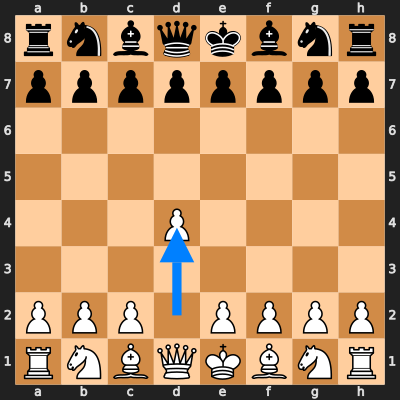

  Pantalla 2/2  MOV 1.n


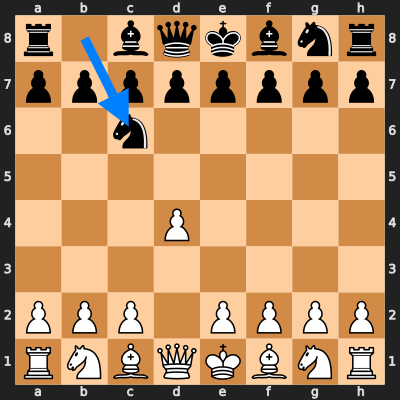


A4 #6 — línea: d4 c5
  Pantalla 1/2  MOV 1.b


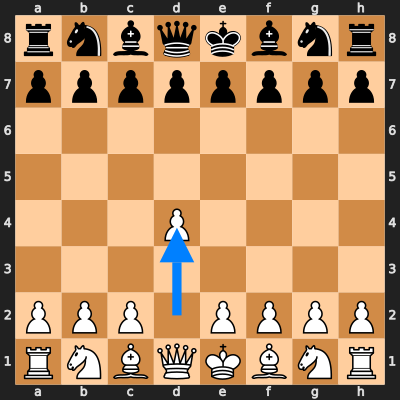

  Pantalla 2/2  MOV 1.n


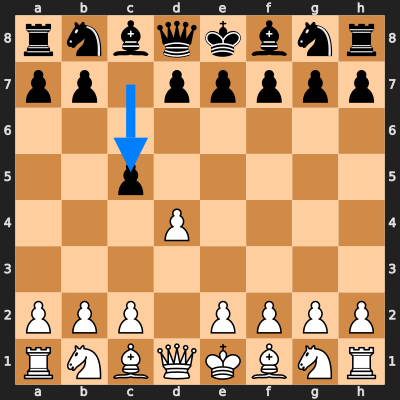


A4 #7 — línea: d4 e5
  Pantalla 1/2  MOV 1.b


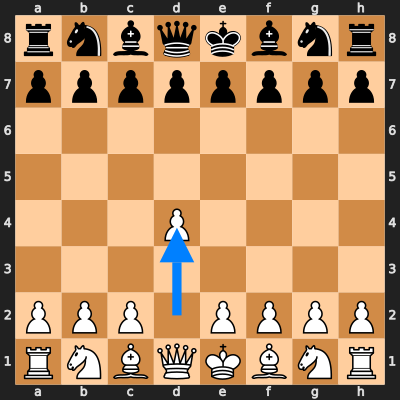

  Pantalla 2/2  MOV 1.n


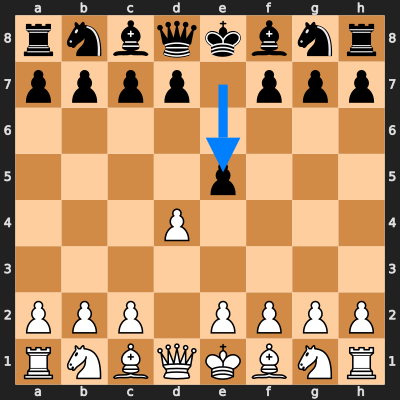


A4 #8 — línea: d4 a6
  Pantalla 1/2  MOV 1.b


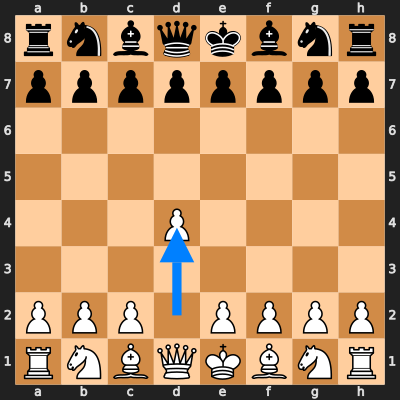

  Pantalla 2/2  MOV 1.n


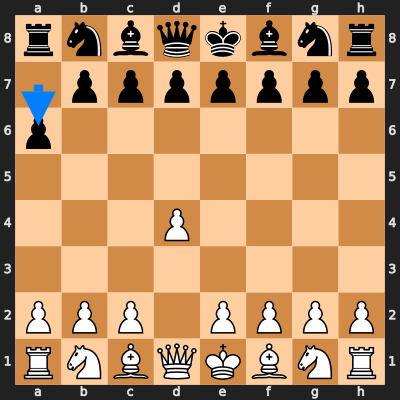


A4 #9 — línea: d4 Na6
  Pantalla 1/2  MOV 1.b


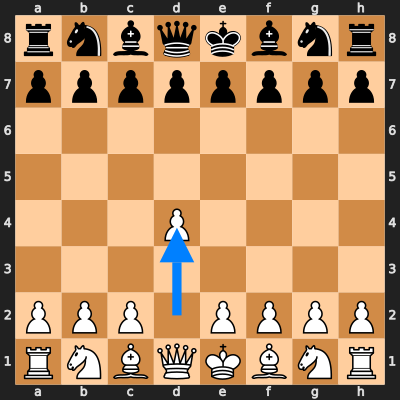

  Pantalla 2/2  MOV 1.n


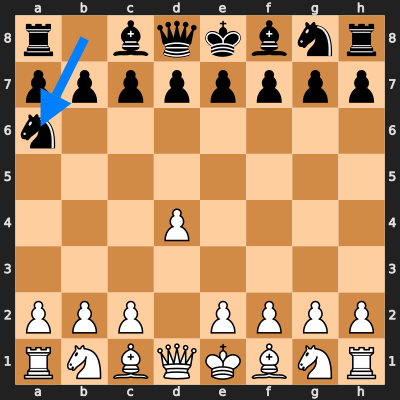

Código B1: 8239 partidas (3.05%)      Total partidas: 270520
Top aperturas o líneas en este código o grupo:
  B12: Defensa Caro-Kann (2398 partidas)
(0.89 % de partidas totales)
  B10: Defensa Caro-Kann (1696 partidas)
(0.63 % de partidas totales)
  B13: Caro-Kann, variante del cambio (1589 partidas)
(0.59 % de partidas totales)
  B15: Defensa Caro-Kann (1051 partidas)
(0.39 % de partidas totales)
  B14: Caro-Kann, atque Panov-Botvinnik, 5...e6 (354 partidas)
(0.13 % de partidas totales)

Patrones con uno o más movimientos o con '!=':

B1 #1 — línea: e4 c6 d4 d5
  Pantalla 1/4  MOV 1.b


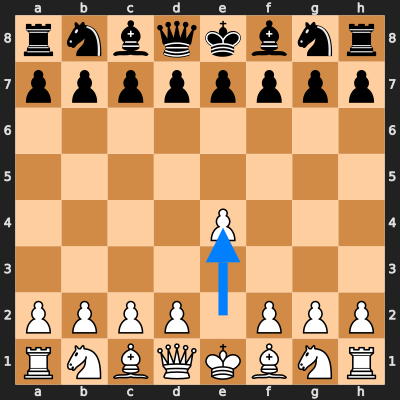

  Pantalla 2/4  MOV 1.n


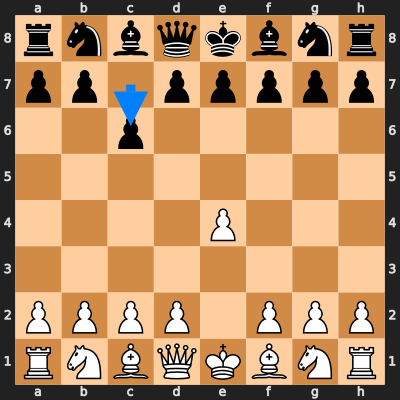

  Pantalla 3/4  MOV 2.b


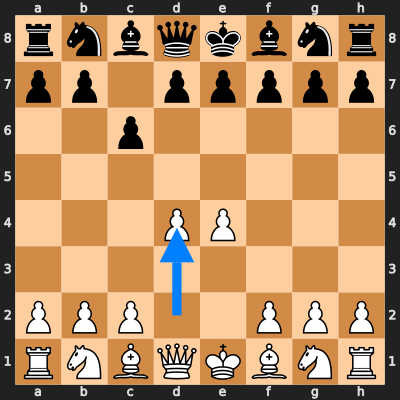

  Pantalla 4/4  MOV 2.n


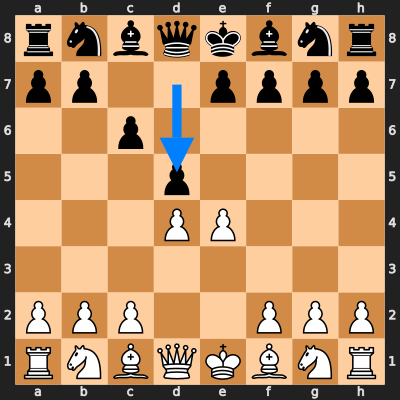

Código D0: 8082 partidas (2.99%)      Total partidas: 270520
Top aperturas o líneas en este código o grupo:
  D00: Apertura de peón de dama (incluyendo Gambito Blackmar-Diemer, Celada Halosar y otras) (3428 partidas)
(1.27 % de partidas totales)
  D02: Apertura Grünfeld invertida (Apertura de peón de dama, 2.Cf3) (3159 partidas)
(1.17 % de partidas totales)
  D06: Gambito de dama declinado (incluyendo la Defensa Báltica, Defensa Marshall y Defensa Simétrica) (403 partidas)
(0.15 % de partidas totales)
  D07: Gambito de dama declinado, variante Chigorin (290 partidas)
(0.11 % de partidas totales)
  D03: Ataque Torre, variante Tartakower (230 partidas)
(0.09 % de partidas totales)

Patrones con uno o más movimientos o con '!=':

D0 #1 — línea: d4 d5   (prohibidos: c4)
  Pantalla 1/3  MOV 1.b


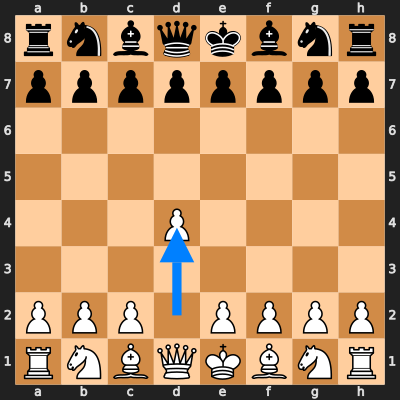

  Pantalla 2/3  MOV 1.n


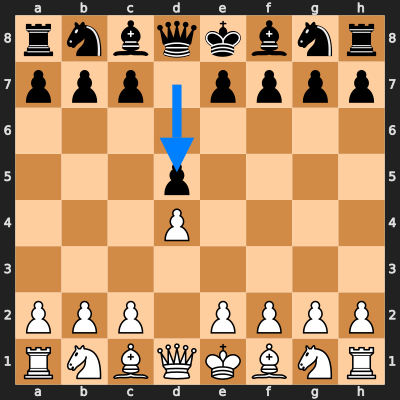

  Pantalla 3/3  MOV 1.n


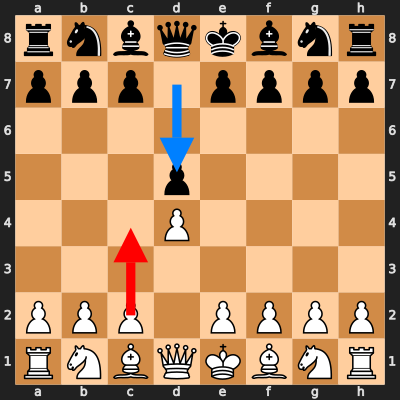

time: 1.72 s (started: 2025-12-11 09:44:59 +01:00)


In [278]:
#pop 5
#imprimirop()
#imprimirop(n=5, pop=1, win=0, lose=0, draw=0, max_plies=20, size=400, nopeningsinfomax=5, draw_forbiddens=True)

imprimirop(n=5, pop=1, win=0, lose=0, draw=0, nopeningsinfomax=5)

In [279]:
#C89 SPASSKY
C89_str = "1 e4 e5 2 Nf3 Nc6 3 Bb5 a6 4 Ba4 Nf6 5 O-O-O Be7 6 Re1 b5 7 Bb3 O-O 8 c3 d5 9 exd5 Nxd5 10 Nxe5 Nxe5 11 Rxe5 c6 12 d4 Bd6 13 Re1 Qh4 14 g3 Qh3 15 Be3 Bg4 16 Qd3 Rae8 17 Nd2 Re6 18 a4 Qh5"

#LISTA DE LISTAS C89 SPASSKY
C89 = [["e4", "e5", "Nf3", "Nc6", "Bb5", "a6", "Ba4", "Nf6", "O-O", "Be7", "Re1", "b5", "Bb3", "O-O", "c3", "d5", "exd5",
"Nxd5", "Nxe5", "Nxe5", "Rxe5", "c6", "d4", "Bd6", "Re1", "Qh4", "g3", "Qh3", "Be3", "Bg4", "Qd3", "Rae8", "Nd2", "Re6", "a4", "Qh5"]]

#18 MOVS=36 MAX PLIERS
#show_group("C8", None, dfeconum, gmr,max_plies=40, manual_patterns=C89_str, draw_forbiddens=True, nopeningsinfomax=5)

time: 0 ns (started: 2025-12-11 09:45:01 +01:00)


##### **INTRODUCCIÓN A APERTURAS Y CONCLUSIONES**

**A:**  Aperturas irregulares o de flanco: primeras jugadas con el peón de (a, b, c, f, g o h) o con caballos, o con d3 / e3 y algunas líneas de c4 y d4 que no son de D ó E.

**B:**  Aperturas semiabiertas: 1.e4 y cualquier respuesta negra que **no** sea e5 ni e6. es decir, todas las líneas donde el blanco juega e4 y las negras responden con otra cosa distinta a e5/e6.

**C:** Aperturas abiertas y francesa: 1.e4 seguido de e5 o de e6 la apertura más ganada (y casi más popular).

**D:** Aperturas cerradas y semicerradas: 1.d4 y luego jugadas negras del tipo d5 o Cf6 (y sus continuaciones normales)

**E:** Defensas Indias: catalanas y anti-marshall, u otras, posiciones que salen de secuencias tipo d4, Cf6, c4 y luego e6 o g6

**TOPS 5**

**Top 5 aperturas con más wins**  
En el top 1, 2 y 4 quedaron semiabiertas (B0, B2, B1) y en el 3 y 5 irregulares de flanco (A4, A0): gana sobre todo lo semiabierto y creativo. Aquí las B son líneas más seguras y conocidas, mientras que las A son ideas más creativas para buscar posiciones nuevas.

**Top 5 aperturas con más loses**  
En derrotas mandó una irregular de flanco (top 1: A0), seguida de una d4 cerrada (top 2: D7) y tres abiertas/francesa (top 3–5: C7, C8, C9). Las A muestran el lado arriesgado de esa creatividad, mientras que en C y D si no conoces bien la teoría, la “seguridad” se te vuelve en contra.

**Top 5 aperturas con más draws**  
En tablas dominaron otra vez las semiabiertas (top 1, 2 y 5: B0, B2, B1), con una irregular (top 3: A4) y una d4 sólida (top 4: D0), donde las B tienden a posiciones sólidas y seguras, y las A intentan creatividad, pero si el rival está preparado, se iguala.

**Top 5 aperturas más populares**  
En popularidad, casi todo el top fue semiabierto (top 1, 2 y 4: B0, B2, B1), con una irregular de flanco (top 3: A4) y una d4 clásica (top 5: D0) como alternativas principales, siendo B opción segura y estándar, D la segunda opción respecto de seguridad y popularidad (mi caso) y A como arma creativa para salirse de la teoría y buscar posiciones nuevas.

## **PREDICCIÓN DE QUIÉN VA A GANAR UNA PARTIDA**

### **POSIBLES ANÁLISIS EDA SEGÚN ESTUDIO**

Con la conclusión del estudio podemos intentar extraer patrones y aplicar técnicas de *clustering* sobre diferentes secciones, por ejemplo:

- Distribución entre países de los diferentes jugadores
- Tipos de jugadores que compran el rango premium.
- Jugadores que tienen un rango social mayor (más amigos/seguidores/clubs/torneos
- Jugadores que estudian o no teoría y cómo se refleja en su progreso.
- Épocas de registro de las cuentas (picos de creación de cuentas).
- Tipos de jugadores más propensos a hacer trampas
- Tipos de plataformas de *streaming* más populares entre los jugadores
- Distribución por meses/días de la semana/horas de juego para incentivar o captar jugadores.
- Tipos de jugadores que dejan de conectarse después de jugar durante poco tiempo o leales durante años, para diseñar un tipo de marketing u otro
- Predicción de la decadencia o ascenso del Elo de un jugador
- Sistema de aprendizaje controlado según fallos y aperturas favoritas.
- Ventaja después de cierto tiempo ó quién ganaría según posición vs stockfish o torch

**Y, la idea por la que me decanté: dado un enfrentamiento entre dos personas con cierto elo, piezas(blancas/negras), historial, rd, una apertura y un modo de juego, estimar quién tiene más probabilidades de ganar.**

### **VARIABLES A USAR XA PREDECIR QUIEN VA A GANAR UNA PARTIDA**

In [286]:
for col in gmr.columns:
    print(col, "-", gmr[col].dtype)
    pass

game_id - int64
list_id - int64
mode_id - int64
mode_name - object
date - datetime64[ns]
result - object
pgn - object
url_id - object
eco_code - object
opening_name - object
white_player_id - float64
white_username - object
white_elo - int64
white_accuracy - float64
white_gender - object
white_country_code - object
white_country_name - object
white_title_code - object
white_title_name - object
white_status_code - object
white_status_name - object
white_is_cheater - float64
white_is_streamer - float64
white_in_club - float64
white_in_tournament - float64
white_league - object
white_followers - float64
white_tournaments_played - float64
white_registration_date - datetime64[ns]
white_last_seen - datetime64[ns]
white_games_played - float64
white_wins - float64
white_losses - float64
white_draws - float64
white_win_rate - float64
white_loss_rate - float64
white_draw_rate - float64
white_best_rating - float64
white_last_rating - float64
white_rd - float64
list_player_id - int64
black_player_

In [287]:
ncodes = (gmr.groupby("eco_code")["eco_code"].count().sort_values(ascending=False).copy())
print(ncodes)

resumen_result = (gmr.groupby(["result_int", "result"], dropna=False)
                  .agg(n_partidas=("game_id", "count"),).reset_index().sort_values("n_partidas", ascending=False))

#%
resumen_result["pct"] = resumen_result["n_partidas"]/len(gmr)
print(resumen_result)

eco_code
D00    3428
A45    3355
D02    3159
B22    3000
B01    2771
       ... 
E89       1
D77       1
A98       1
B64       1
D99       1
Name: eco_code, Length: 481, dtype: int64
    result_int              result  n_partidas       pct
0            0                 win       80537  0.593786
1            1            resigned       27115  0.199914
4            4          repetition        6782  0.050003
2            2          checkmated        5992  0.044178
6            6              agreed        5588  0.041199
7            7             timeout        4552  0.033561
8            8        insufficient        2392  0.017636
5            5           abandoned        1128  0.008317
3            3           stalemate         731  0.005390
9            9  timevsinsufficient         625  0.004608
10          10              50move         191  0.001408
time: 109 ms (started: 2025-12-11 09:45:01 +01:00)


titled, eco_code, title_code si ambos, league, wins loses draws, rates, followers, couontry_code, elo, accuracy, ngames, reg_year
top aperturas fav-winrate lose rate draw rate

### **XBOOST Y ENTRENO SEGÚN TARGET=WIN(1) LO DEMÁS (0) LOG BINARIA**

In [290]:
def elo_expected_white(white_elo, black_elo):#wiki formula elo de chess.com
    diff = white_elo - black_elo
    return 1.0 / (1.0 + 10.0 ** (-(diff) / 400.0))

def map_list_outcome(code: int) -> str:#win(cod 0) 1 lo demas 0 cods(1257 loss, 3468910 draw)
    if code == 0:
        return "win"
    elif code in {1, 2, 5, 7}:
        return "loss"
    elif code in {3, 4, 6, 8, 9, 10}:
        return "draw"
    else:
        return "other"

gmr["list_outcome"] = gmr["result_int"].map(map_list_outcome)#funcion con col result int
gmr["list_is_white"] = gmr["list_player_id"] == gmr["white_player_id"]#true si es white

def compute_white_win(row) -> int:#ret 1 win otro no win 0

    outcome = row["list_outcome"]# 0 o 1 
    is_white = row["list_is_white"]# T(white) F(blacky)

    if outcome == "draw":
        return 0
    if outcome == "win":
        return 1 if is_white else 0
    if outcome == "loss":
        return 0 if is_white else 1
    return 0

gmr["white_win"] = gmr.apply(compute_white_win, axis=1).astype(int)

print("n white wins (da igual player):")
print(gmr["white_win"].value_counts())
print("wins white %:")
print(gmr["white_win"].value_counts(normalize=True))#normalizar 0-1

#eco y fecha
mask_valid = (gmr["white_elo"].notna() & gmr["black_elo"].notna()
    & np.isfinite(gmr["white_elo"]) & np.isfinite(gmr["black_elo"]))#inf y nan solo loc no quiero eliminarlos

df = gmr.loc[mask_valid, ["white_elo", "black_elo", "eco_code_int", "white_win", "date"]].copy()

df["elo_diff"] = df["white_elo"] - df["black_elo"]
df["elo_expected_white"] = elo_expected_white(df["white_elo"], df["black_elo"])#wiki
feature_cols=["elo_diff", "elo_expected_white", "eco_code_int"]

df_model = (df[feature_cols + ["white_win", "date"]].replace([np.inf, -np.inf], np.nan).dropna().copy())


#DFS POR LEN DE 0.2 Y 0.8
df_model = df_model.sort_values("date").reset_index(drop=True)
n_total = len(df_model)
cut = int(n_total * 0.8)

df_train = df_model.iloc[:cut].copy()#esto es nuevo ni idea de que funcionase
df_test  = df_model.iloc[cut:].copy()#20% restante

X_train = df_train[feature_cols]
y_train = df_train["white_win"]
X_test  = df_test[feature_cols]
y_test  = df_test["white_win"]

print(f"\nTamaño train: {X_train.shape}, tamaño test (último 20%): {X_test.shape}")

#XBOOST ENTRENO 
xgb_model = XGBClassifier(
    objective="binary:logistic",   #probabilidad del 0-1 (binaria) win o no win %
    eval_metric="logloss", #log loss castigo x error en probaboilidad calidasd, tb hay error(de forma bin) cuanto acierta y auc libreria (prob de win y lose al azar + proib win que lose 0.8 casi god)
    n_estimators=300, #arboles/preguntas de correccion de prob (elo dif>200- si p=0.8, nop-sig preg...) entre200-500 xa q no memorice num arboles cada uno corrige errores del anterior
    max_depth=4, #4pregs (profundidad arbol)
    learning_rate=0.05, #+arboles -peso de aprender de cada uno (muchos datos tb no aumentar mucho)
    subsample=0.9, #90% de filas de train
    colsample_bytree=0.9, #% columnas por árbol de train =subsample pero con cols
    reg_lambda=1.0, #pérdida total = logloss + λ × (suma de pesos²), lambda grande(10-5) pesos grandes 0.99 0.5 xa pocos datos, lambda pequeña (0-1) penaliza pesos grandes
    n_jobs=-1, #ncores usa(vel), todos mis cores xq no
    random_state=None, #seed modelo no quiero (42 num universo antes)
)

#aprendizaje 
xgb_model.fit(X_train, y_train)#train cols y target cols bins/ ajusta arboles xa q probabilidad se acerque a white_win=p

df_train["p_pred"] = xgb_model.predict_proba(X_train)[:, 1]#arr de % de no ganar y ganar, calse 0,calse1[0.3,0.7],[0.8,0.2]
df_test["p_pred"]  = xgb_model.predict_proba(X_test)[:, 1]

print("MÉTRICAS TRAIN 80%:")
print("AUC (train/prob de win y lose al azar + proib win que lose):    ", roc_auc_score(y_train, df_train["p_pred"]))
print("Log-loss (train):", log_loss(y_train, df_train["p_pred"]))

print("MÉTRICAS TEST 20% final:")
print("AUC (test):     ", roc_auc_score(y_test, df_test["p_pred"]))
print("Log-loss (test):", log_loss(y_test, df_test["p_pred"]))

resumen_result = (
    gmr.groupby(["result_int", "result"], dropna=False, observed=False)
      .agg(n_partidas=("game_id", "count"))#xa cada result couts games id(ngames)
      .reset_index()
      .sort_values("n_partidas", ascending=False)
)
resumen_result["pct"] = resumen_result["n_partidas"] / len(gmr)
print("\nResumen de result_int / result (segun jugador no color):")
print(resumen_result)


# LOG-LOSS (calidad de probas)

# Referencia: un modelo tonto que siempre dice p=0.5 tiene log_loss ≈ 0.693.
#
# ≈ 0.69 o más alto  casi no mejoras a tirar una moneda.
# 0.65 – 0.60  empieza a aprender algo, pero muy justito.
# 0.60 – 0.55  está aprendiendo algo de verdad.(tpy aqui)
# 0.55 – 0.50 bastante bien, probas razonables.
# < 0.50  muy bien calibrado para un problema real.
#
# ¡+bajo mejor!



# AUC (capacidad de ORDENAR las partidas)

# 0.50   como tirar una moneda (no distingue ganadas de perdidas).
# 0.55 – 0.60   ve algo de señal, pero flojito.
# 0.60 – 0.70    modelo decente, ya ordena razonablemente.
# 0.70 – 0.80    bastante bueno, distingue bien quién es favorito. (toy aqui)
# 0.80 – 0.90   muy bueno (difícil de conseguir en problemas reales).
# > 0.90   brutal; sospecha de overfitting si los datos no son enormes.
#+alto mejor

#p blancas win >50% mascara
y_train_pred = (df_train["p_pred"] >= 0.5).astype(int)
y_test_pred  = (df_test["p_pred"]  >= 0.5).astype(int)

n_train = len(y_train)
n_test  = len(y_test)

train_aciertos= int((y_train_pred == y_train).sum())
test_aciertos = int((y_test_pred == y_test).sum())

train_accuracy= train_aciertos /n_train
test_accuracy= test_aciertos /n_test

print("\nAciertos TRAIN:", train_aciertos, "de", n_train, "→ accuracy =", train_accuracy)
print("Aciertos TEST :", test_aciertos,  "de", n_test,  "→ accuracy =", test_accuracy)

n white wins (da igual player):
white_win
0    73534
1    62099
Name: count, dtype: int64
wins white %:
white_win
0    0.542154
1    0.457846
Name: proportion, dtype: float64

Tamaño train: (108506, 3), tamaño test (último 20%): (27127, 3)
MÉTRICAS TRAIN 80%:
AUC (train/prob de win y lose al azar + proib win que lose):     0.8024945966089336
Log-loss (train): 0.5382473149392747
MÉTRICAS TEST 20% final:
AUC (test):      0.7663992011357852
Log-loss (test): 0.5775215904787714

Resumen de result_int / result (segun jugador no color):
    result_int              result  n_partidas       pct
0            0                 win       80537  0.593786
1            1            resigned       27115  0.199914
4            4          repetition        6782  0.050003
2            2          checkmated        5992  0.044178
6            6              agreed        5588  0.041199
7            7             timeout        4552  0.033561
8            8        insufficient        2392  0.017636
5       

### **GRÁFICOS Y ENTRENOS**

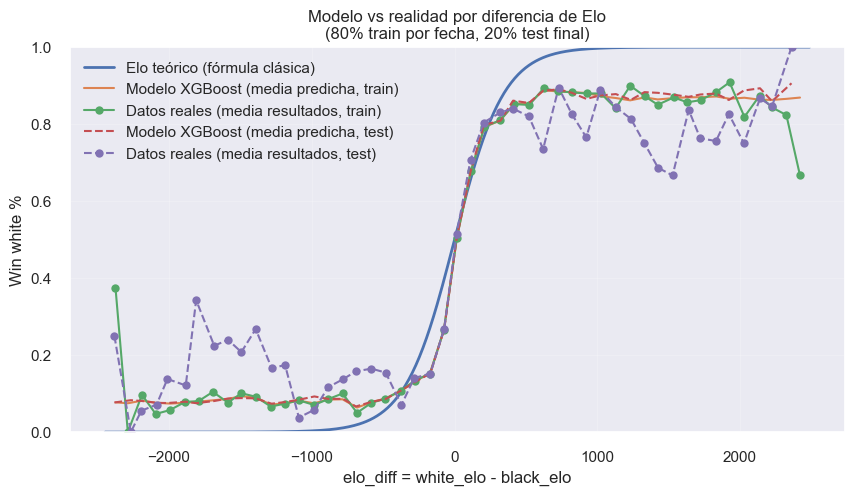

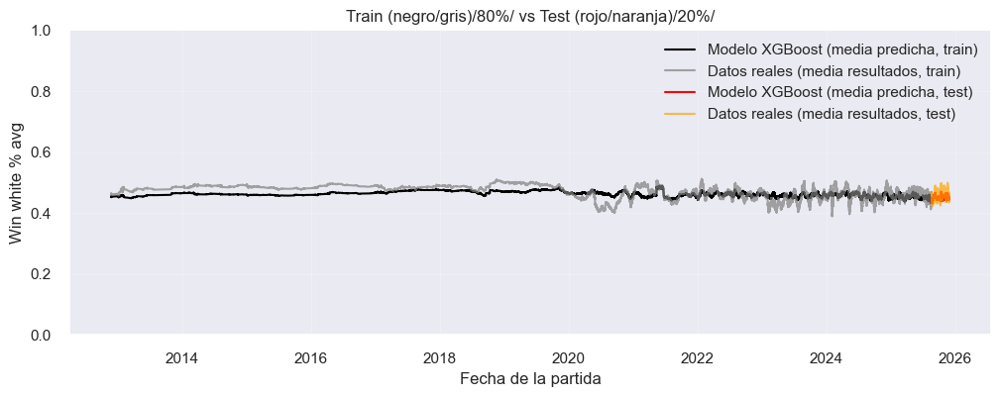

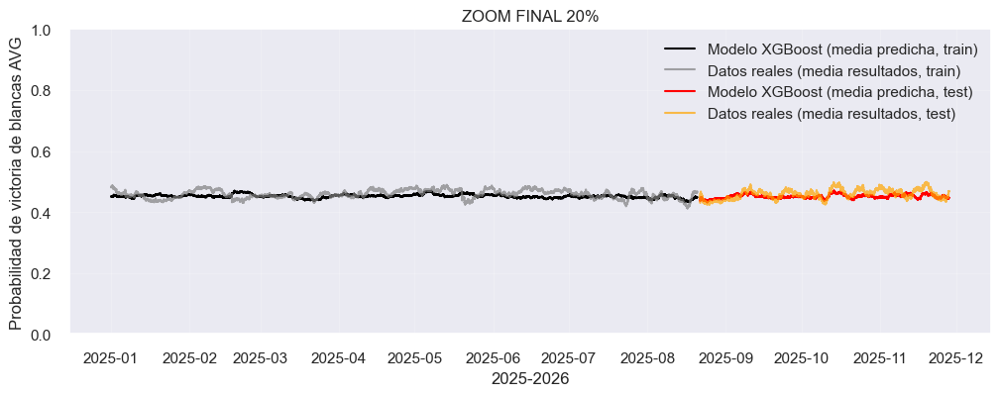

time: 1.16 s (started: 2025-12-11 09:45:07 +01:00)


In [292]:
#WIN % WHITES SEGÚN DIF ELO

bins = np.linspace(df_model["elo_diff"].min(), df_model["elo_diff"].max(), 50)#menor a mayr rango

def agg_by_bins(df_part):
    grouped = df_part.groupby(
        pd.cut(df_part["elo_diff"], bins=bins, include_lowest=True),
        observed=False)  #futurewarning mierdero
    out = grouped.agg(
        mean_elo_diff=("elo_diff", "mean"),
        p_real=("white_win", "mean"),
        p_pred=("p_pred", "mean"),
        n=("white_win", "size"),
    ).dropna()
    return out

train_bins = agg_by_bins(df_train)
test_bins  = agg_by_bins(df_test)

plt.figure(figsize=(10, 5))

elo_grid = np.linspace(df_model["elo_diff"].min(), df_model["elo_diff"].max(), 400)
elo_theo = 1.0 / (1.0 + 10.0 ** (-(elo_grid) / 400.0))#wiki
plt.plot(elo_grid, elo_theo, label="Elo teórico (fórmula clásica)", linewidth=2)

plt.plot(
    train_bins["mean_elo_diff"],
    train_bins["p_pred"],
    label="Modelo XGBoost (media predicha, train)",
)
plt.plot(
    train_bins["mean_elo_diff"],
    train_bins["p_real"],
    "o-",
    label="Datos reales (media resultados, train)",
)

plt.plot(
    test_bins["mean_elo_diff"],
    test_bins["p_pred"],
    "--",
    label="Modelo XGBoost (media predicha, test)",
)
plt.plot(
    test_bins["mean_elo_diff"],
    test_bins["p_real"],
    "o--",
    label="Datos reales (media resultados, test)",
)

plt.ylim(0.0, 1.0)  #escala 0–1 (probabilidades)
plt.xlabel("elo_diff = white_elo - black_elo")
plt.ylabel("Win white %")
plt.title("Modelo vs realidad por diferencia de Elo\n(80% train por fecha, 20% test final)")
plt.grid(True, alpha=0.2)
plt.legend()
plt.show()


#TRAIN VS TEST 

window = 1000
min_periods = window // 5

# df_train_roll y df_test_roll ya vienen de df_train/df_test del 80/20 por fecha
df_train_roll = df_train.sort_values("date").copy()
df_test_roll  = df_test.sort_values("date").copy()

# p_real_roll: media móvil de resultados reales (white_win)
df_train_roll["p_real_roll"] = df_train_roll["white_win"].rolling(
    window, min_periods=min_periods).mean()
df_test_roll["p_real_roll"] = df_test_roll["white_win"].rolling(
    window, min_periods=min_periods).mean()

# p_pred_roll: media móvil de probabilidades predichas por el modelo
df_train_roll["p_pred_roll"] = df_train_roll["p_pred"].rolling(
    window, min_periods=min_periods
).mean()
df_test_roll["p_pred_roll"] = df_test_roll["p_pred"].rolling(
    window, min_periods=min_periods
).mean()

plt.figure(figsize=(12, 4))

plt.plot(
    df_train_roll["date"],
    df_train_roll["p_pred_roll"],
    label="Modelo XGBoost (media predicha, train)",
    color="black",
)
plt.plot(
    df_train_roll["date"],
    df_train_roll["p_real_roll"],
    label="Datos reales (media resultados, train)",
    color="gray",
    alpha=0.7,
)

plt.plot(
    df_test_roll["date"],
    df_test_roll["p_pred_roll"],
    label="Modelo XGBoost (media predicha, test)",
    color="red",
)
plt.plot(
    df_test_roll["date"],
    df_test_roll["p_real_roll"],
    label="Datos reales (media resultados, test)",
    color="orange",
    alpha=0.7,
)

plt.ylim(0.0, 1.0)
plt.xlabel("Fecha de la partida")
plt.ylabel("Win white % avg")
plt.title("Train (negro/gris)/80%/ vs Test (rojo/naranja)/20%/")
plt.grid(True, alpha=0.2)
plt.legend()
plt.show()


#ZOOM 25-26

#desde 1/1/25
start_zoom = pd.Timestamp("2025-01-01")
end_zoom = df_test_roll["date"].max() + pd.Timedelta(days=1)

mask_train_zoom = (df_train_roll["date"] >= start_zoom) & (df_train_roll["date"] <= end_zoom)
mask_test_zoom  = (df_test_roll["date"] >= start_zoom) & (df_test_roll["date"] <= end_zoom)

plt.figure(figsize=(12, 4))

#train ultimo
plt.plot(
    df_train_roll.loc[mask_train_zoom, "date"],
    df_train_roll.loc[mask_train_zoom, "p_pred_roll"],
    label="Modelo XGBoost (media predicha, train)",
    color="black",
)
plt.plot(
    df_train_roll.loc[mask_train_zoom, "date"],
    df_train_roll.loc[mask_train_zoom, "p_real_roll"],
    label="Datos reales (media resultados, train)",
    color="gray",
    alpha=0.7,
)

#Desde 2025
plt.plot(
    df_test_roll.loc[mask_test_zoom, "date"],
    df_test_roll.loc[mask_test_zoom, "p_pred_roll"],
    label="Modelo XGBoost (media predicha, test)",
    color="red",
)
plt.plot(
    df_test_roll.loc[mask_test_zoom, "date"],
    df_test_roll.loc[mask_test_zoom, "p_real_roll"],
    label="Datos reales (media resultados, test)",
    color="orange",
    alpha=0.7,
)

plt.ylim(0.0, 1.0)
plt.xlabel("2025-2026")
plt.ylabel("Probabilidad de victoria de blancas AVG")
plt.title("ZOOM FINAL 20%")
plt.grid(True, alpha=0.2)
plt.legend()
plt.show()


### **PROBAR PARTIDAS DEFS**

In [294]:
def eco_code_to_int(eco_input):
    #Si ya es int, lo devuelve tal cual (e intenta recuperar eco_code).
    #Si es string, busca eco_code en gmr.
    #Si no existe, intenta por prefijo (A0 -> A00 más frecuente).

    if eco_input is None:
        return 0, None

    #int
    if isinstance(eco_input, (int, np.integer)):
        eco_int = int(eco_input)
        fila = gmr[gmr["eco_code_int"] == eco_int].head(1)
        eco_str = fila["eco_code"].iloc[0] if not fila.empty else None
        return eco_int, eco_str         # Si fila ecocode

    #str
    eco_str = str(eco_input).upper().strip()
    sub = gmr[gmr["eco_code"] == eco_str]
    if not sub.empty:
        eco_int = int(sub["eco_code_int"].mode().iloc[0]) #+ frec
        return eco_int, eco_str

    #x prefijo
    prefix = eco_str[:2]  #2 letras
    sub_pref = gmr[gmr["eco_code"].str.startswith(prefix)]

    if not sub_pref.empty: #uso el + frec de los restantes
        eco_counts = (
            sub_pref.groupby("eco_code", observed=False)["eco_code"].count().sort_values(ascending=False))
        eco_best = eco_counts.index[0]#+ frec
        eco_int = int(sub_pref[sub_pref["eco_code"] == eco_best]["eco_code_int"].mode().iloc[0])
        print(f"ECO '{eco_str}' no existe; uso '{eco_best}' por ser la más frecuente con ese prefijo.")
        return eco_int, eco_best

    #algo raro
    print(f"ECO '{eco_str}' no encontrado en gmr; uso eco_code_int=0.")
    return 0, eco_str


#elo onemode last rating def
def get_mode_elo(player_row):
    for col in ["mode_last_rating", "mode_best_rating", "max_last_rating", "overall_best_rating"]:
        if col in player_row and pd.notna(player_row[col]):
            return float(player_row[col])
    raise ValueError("No hay Elo xa este en estos campos")


#asegurarme de que esta con insert usu y games si no esta, si no esta de todas formas (falla algo/ no esiste) devuelve none y dfnew

def ensure_player_row(players_df, username, mode_id=3, auto_insert=False, max_games=None):
    df = players_df
    mask = df["username"].str.lower() == username.lower() #df en minusculas todos los usernames chess.com se la pela
    rows = df[mask]

    if not rows.empty:
        return rows.iloc[0], df

    if not auto_insert:
        print(f"Jugador '{username}' no está en players_df y auto_insert=False.")
        return None, df

    print(f"Intentando insertar usuario '{username}' con insert_usu ....")

    conn = mysql.connector.connect(
        host=MYSQL_HOST,
        user=MYSQL_USER,
        password=MYSQL_PASSWORD,
        database="chesscraping",
    )
    try:
        insert_usu(conn, username)
        conn.commit()
    finally:
        conn.close()

    df_new = modedf(mode_id) #stats modo
    rows2 = df_new[df_new["username"].str.lower() == username.lower()]
    if rows2.empty:
        print(f"Después de insert_usu, el usuario '{username}' sigue sin aparecer en el modo {mode_id} NPI de xq")
        return None, df_new

    return rows2.iloc[0], df_new #usu,dfstats modo


#features elos y ecos
def build_match_features_from_rows(pw, pb, eco_code=None):
    #pw,pb(black/white) son palyer fila de elos (cols nombres)
    elo_white = get_mode_elo(pw)
    elo_black = get_mode_elo(pb)

    #eco con gmr a int desde str si esta disp, si no 0=a00
    eco_int, eco_str = eco_code_to_int(eco_code)

    #rows features
    row = {"elo_diff": elo_white - elo_black, "elo_expected_white": elo_expected_white(elo_white, elo_black),"eco_code_int": eco_int,}

    #ret dict a df
    X_row = pd.DataFrame([row])[feature_cols].copy()
    return X_row, elo_white, elo_black, eco_int, eco_str


def probar_partida(white_name, black_name, eco_code=None, mode_id=3, auto_insert=False, max_games=None,):
    """
    probas XGBoost (P_white_win_xgb, P_black_win_xgb)
    probas Elo teóricas (P_white_win_elo, P_black_win_elo)
    Elo del modo para cada jugador y ECO usado
    Si auto_insert=True, intenta crear los jugadores que falten con insert_usu
    """
    players_df = modedf(mode_id)

    pw, players_df = ensure_player_row(
        players_df, white_name, mode_id=mode_id, auto_insert=auto_insert, max_games=max_games)
    pb, players_df = ensure_player_row(
        players_df, black_name, mode_id=mode_id, auto_insert=auto_insert, max_games=max_games)

    if pw is None or pb is None:
        print("No hay información suficiente (Elo/jugador/npi) para este enfrentamiento")
        return None

    X_row, elo_white, elo_black, eco_int, eco_str = build_match_features_from_rows(pw, pb, eco_code=eco_code)#elos build features elos y ecos

    p_white_xgb = float(xgb_model.predict_proba(X_row)[0, 1])#xrow features
    p_black_xgb = 1.0 - p_white_xgb

    p_white_elo = float(elo_expected_white(elo_white, elo_black))#wiki expected elo win 0-1
    p_black_elo = 1.0 - p_white_elo

    print("<><> Predicción XGBoost (binario: gana blancas vs no gana blancas (draw o lose)) <><>")
    print({
        "white_name": white_name,
        "black_name": black_name,
        "P_white_win_xgb": p_white_xgb,
        "P_black_win_xgb": p_black_xgb,
    })

    print("\n<><> Elo del modo (onemode_mode_id) <><>")
    print(f"{white_name}: {elo_white}")
    print(f"{black_name}: {elo_black}")

    print("\n<><> Probabilidad Elo pura de que gane blancas (fórmula Elo wiki) <><>")
    print(f"P_white_win_elo = {p_white_elo:.4f}")
    print(f"P_black_win_elo = {p_black_elo:.4f}")

    if eco_str is not None:
        print("\n<><><> ECO <><><>")
        print(f"eco_code introducido = {eco_str}, eco_code_int = {eco_int}")

    resultado = {
        "white_name": white_name,
        "black_name": black_name,
        "P_white_win_xgb": p_white_xgb,
        "P_black_win_xgb": p_black_xgb,
        "P_white_win_elo": p_white_elo,
        "P_black_win_elo": p_black_elo,
        "elo_white": elo_white,
        "elo_black": elo_black,
        "eco_code": eco_str,
        "eco_code_int": eco_int,
    }

    print("\nResultado resumido:")
    print(resultado)
    return resultado

time: 15 ms (started: 2025-12-11 09:45:08 +01:00)


### **PROBAR PARTIDAS FAMOSAS**

In [296]:
partidas_famosas = [
    {
        "white_name": "Firouzja2003",
        "black_name": "MagnusCarlsen",
        "eco_code": "B33",
        "url_partida": "https://www.chess.com/game/live/151748880471?username=firouzja2003&move=0",
    },

    {
        "white_name": "MagnusCarlsen",
        "black_name": "ReyEnigma",
        "eco_code": "A40",
        "url_partida": "https://www.chess.com/game/live/1122334455?username=MagnusCarlsen&move=0",
    },

    {
        "white_name": "MagnusCarlsen",
        "black_name": "Hikaru",
        "eco_code": "A00",
        "url_partida": "https://www.chess.com/events/2025-norway-chess-main/13/Carlsen_Magnus-Nakamura_Hikaru",
    }, 

    {
        "white_name": "Hikaru",
        "black_name": "MagnusCarlsen",
        "eco_code": "A00",
        "url_partida": "https://www.chess.com/events/2025-champions-chess-tour-chesscom-classic-playoffs/04-04/Nakamura_Hikaru-Carlsen_Magnus",
    },

    {
        "white_name": "HansOnTwitch",
        "black_name": "MagnusCarlsen",
        "eco_code": "A00",
        "url_partida": "https://www.chess.com/events/2024-titled-tuesday-blitz-july-09-early/dashboard/11/Niemann_Hans_Moke-Carlsen_Magnus",
    },

    {
        "white_name": "HansOnTwitch",
        "black_name": "GiriChess",
        "eco_code": "A00",
        "url_partida": "https://www.chess.com/events/2024-hans-niemann-vs-anish-giri/21/Niemann_Hans_Moke-Giri_Anish",
    },

    {
        "white_name": "FaustinoOro",
        "black_name": "adotand",
        "eco_code": "D00",
        "url_partida": "https://www.chess.com/game/live/144207997328?username=faustinooro&move=0",
    },
]

pn=0
for m in partidas_famosas:
    pn+=1
    print(f"\n |||||| Partida {pn} -- {m["white_name"]} VS {m["black_name"]} |||||||")
    probar_partida(
        m["white_name"],
        m["black_name"],
        eco_code=m["eco_code"],
        mode_id=3, #rápida
        auto_insert=True,#x si acaso
    )
    print("Partida real en chess.com:", m["url_partida"])


 |||||| Partida 1 -- Firouzja2003 VS MagnusCarlsen |||||||
<><> Predicción XGBoost (binario: gana blancas vs no gana blancas (draw o lose)) <><>
{'white_name': 'Firouzja2003', 'black_name': 'MagnusCarlsen', 'P_white_win_xgb': 0.2325047105550766, 'P_black_win_xgb': 0.7674952894449234}

<><> Elo del modo (onemode_mode_id) <><>
Firouzja2003: 2844.0
MagnusCarlsen: 2941.0

<><> Probabilidad Elo pura de que gane blancas (fórmula Elo wiki) <><>
P_white_win_elo = 0.3639
P_black_win_elo = 0.6361

<><><> ECO <><><>
eco_code introducido = B33, eco_code_int = 156

Resultado resumido:
{'white_name': 'Firouzja2003', 'black_name': 'MagnusCarlsen', 'P_white_win_xgb': 0.2325047105550766, 'P_black_win_xgb': 0.7674952894449234, 'P_white_win_elo': 0.36392310031211805, 'P_black_win_elo': 0.636076899687882, 'elo_white': 2844.0, 'elo_black': 2941.0, 'eco_code': 'B33', 'eco_code_int': 156}
Partida real en chess.com: https://www.chess.com/game/live/151748880471?username=firouzja2003&move=0

 |||||| Partida 2 

2/7 mal(1 era empate) 5/7 bien pruebas reales, 